# Início



In [ ]:
# @title Instalar Pacotes
#import os
#import torch

# 1. Desinstala as versões conflitantes antigas
#!pip uninstall torch-scatter torch-sparse torch-geometric torch-geometric-temporal -y

# 2. Detecta dinamicamente o PyTorch nativo e o CUDA do Colab (Sem downgrades forçados)
#TORCH = torch.__version__.split('+')[0]
#CUDA = "cu" + torch.version.cuda.replace('.', '') if torch.version.cuda else "cpu"

#print(f"\n✅ Detectado no Colab: PyTorch {torch.__version__} | CUDA {torch.version.cuda}")
#URL = f"https://data.pyg.org/whl/torch-{TORCH}+{CUDA}.html"
#print(f"🔗 Buscando binários em: {URL}\n")

# 3. Instala os pacotes de álgebra esparsa sob medida para o PyTorch nativo
#!pip install torch-scatter torch-sparse -f {URL}

# 4. Instala as ferramentas de grafos, o Optuna e corrige o problema do NumPy/SHAP
#!pip install torch-geometric torch-geometric-temporal optuna hierarchicalforecast "numpy<2" "shap<=0.45.1"

# 1. Atualiza o PyTorch para a versão 2.4.0 (compatível com Python 3.12 + compile)
!pip install torch==2.4.0 torchvision==0.19.0 torchaudio==2.4.0 --index-url https://download.pytorch.org/whl/cu121

# 2. Instala os binários esparsos específicos criados para o PyTorch 2.4.0
!pip install torch-scatter torch-sparse -f https://data.pyg.org/whl/torch-2.4.0+cu121.html

# 3. Instala o resto das suas dependências
!pip install torch-geometric torch-geometric-temporal optuna hierarchicalforecast "numpy<2" "shap<=0.45.1"

Looking in indexes: https://download.pytorch.org/whl/cu121
Looking in links: https://data.pyg.org/whl/torch-2.4.0+cu121.html


In [ ]:
# @title Importar todos os pacotes
import sys
import warnings
import sqlite3                      # Banco de dados para exportação final
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric_temporal.nn.recurrent import AGCRN
from xgboost import XGBRegressor    # Usado APENAS para SHAP
from sklearn.preprocessing import StandardScaler
from scipy.signal import savgol_filter
from scipy.stats import nbinom

try:
    from hierarchicalforecast.methods import MinTrace
    from hierarchicalforecast.utils import aggregate
    HF_DISPONIVEL = True
except ImportError:
    HF_DISPONIVEL = False
    print("⚠️ hierarchicalforecast não instalado — reconciliação MinT desativada.")

# import shap # shap não vai rodar com numpy <2, mas o AGCRN não roda com numpy >2
from tqdm.auto import tqdm

In [ ]:
# @title Variáveis do banco de dados
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🚀 A executar no hardware: {device.type.upper()}")

VARS = {
    'municipio':         'geocode',
    'semana_epi':        'epiweek',
    'data':              'date',
    'casos_dengue':      'casos.x',
    'casos_chik':        'casos.y',
    'populacao':         'population',
    'uf_code':           'uf_code',
    'temp_min':          'temp_min',
    'temp_med':          'temp_med',
    'temp_max':          'temp_max',
    'precip_min':        'precip_min',
    'precip_med':        'precip_med',
    'precip_max':        'precip_max',
    'precip_tot':        'precip_tot',
    'amplitude_termica': 'thermal_range',
    'pressao_min':       'pressure_min',
    'pressao_atm':       'pressure_med',
    'pressao_max':       'pressure_max',
    'umidade_min':       'rel_humid_min',
    'umidade':           'rel_humid_med',
    'umidade_max':       'rel_humid_max',
    'dias_chuva':        'rainy_days',
    'enso':              'enso',
    'iod':               'iod',
    'pdo':               'pdo',
    'bioma':             'biome',
    'koppen':            'koppen',
    'afya_acessos':      'access_count',
    'vpd':               'vpd',
    'amp_termica_din3':  'amplitude_termica_dinamica3',
    'amp_termica_din2':  'amplitude_termica_dinamica2',
    'volatilidade_temp': 'volatilidade_temp_4w',
    'volatilidade_prec': 'volatilidade_precip_4w',
    'hti3':              'hti_lag3',
    'hti2':              'hti_lag2',
}

SEASONS = {
    1: {'train': "train1_dengue.parquet", 'test': "test1_dengue.parquet", 'label': '2022-2023'},
    2: {'train': "train2_dengue.parquet", 'test': "test2_dengue.parquet", 'label': '2023-2024'},
    3: {'train': "train3_dengue.parquet", 'test': "test3_dengue.parquet", 'label': '2024-2025'},
    4: {'train': "train4_dengue.parquet", 'test': "test4_dengue.parquet", 'label': '2025-2026'}
}

QUANTIS = {
    '50': (0.25, 0.75),
    '80': (0.10, 0.90),
    '90': (0.05, 0.95),
    '95': (0.025, 0.975),
}


🚀 A executar no hardware: CUDA


# Engenharia de features espaciais simples

In [ ]:
# @title Matriz Espacial
import geopandas as gpd
import numpy as np
import pandas as pd
from libpysal.weights import Queen

def construir_hierarquia_w_geografica(caminho_gpkg, mapa_simples, col_geocode_gpkg='geocode'):
    print("🌍 Carregando malha municipal e construindo hierarquia de vizinhanças (Ordens 1 e 2)...")
    gdf = gpd.read_file(caminho_gpkg)

    # Garante compatibilidade de tipo de dados do geocode
    gdf[col_geocode_gpkg] = gdf[col_geocode_gpkg].astype(mapa_simples[VARS['municipio']].dtype)

    # ==============================================================================
    # 1. CONSTRUÇÃO DE W1 (Região Imediata - Ordem 1)
    # ==============================================================================
    w1_queen = Queen.from_dataframe(gdf, idVariable=col_geocode_gpkg)

    # ALINHAMENTO MANDATÓRIO COM O GRAFO (Antes da normalização)
    lista_municipios_ordenada = mapa_simples[VARS['municipio']].tolist()

    # Captura a matriz binária adjacente cheia [N x N] alinhada
    W1_binary = w1_queen.full()[0]
    W1_df_bin = pd.DataFrame(W1_binary, index=w1_queen.id_order, columns=w1_queen.id_order)
    W1_bin_alinhada = W1_df_bin.reindex(index=lista_municipios_ordenada, columns=lista_municipios_ordenada).fillna(0.0).values

    # ==============================================================================
    # 2. CONSTRUÇÃO MATEMÁTICA DE W2 (Região Distante - Ordem 2)
    # ==============================================================================
    # W2 binário puro é o quadrado da matriz W1 binária.
    # [N x N] @ [N x N] -> Diz quantos caminhos de tamanho 2 existem entre i e j
    W2_raw = W1_bin_alinhada @ W1_bin_alinhada

    # Cria a adjacência booleana (existe caminho > 0)
    W2_bin_alinhada = (W2_raw > 0).astype(np.float32)

    # Limpeza estrita para garantir vizinhos DISTANTES:
    N = W1_bin_alinhada.shape[0]
    W2_bin_alinhada[np.eye(N, dtype=bool)] = 0.0      # Remove a autovizinhança (diagonal)
    W2_bin_alinhada[W1_bin_alinhada == 1.0] = 0.0     # Remove os vizinhos de ordem 1

    # ==============================================================================
    # 3. NORMALIZAÇÃO POR LINHA (Row-Standardization)
    # ==============================================================================
    # Transforma contagens em médias dos vizinhos. Trata potencias divisões por zero (ilhas).
    def normalizar_w(W_binary):
        with np.errstate(divide='ignore', invalid='ignore'):
            row_sums = W_binary.sum(axis=1)
            W_norm = W_binary / row_sums[:, np.newaxis]
            return np.nan_to_num(W_norm, nan=0.0)

    W1_final = normalizar_w(W1_bin_alinhada)
    W2_final = normalizar_w(W2_bin_alinhada)

    print(f"✅ Hierarquia concluída. Dimensões: W1={W1_final.shape} | W2={W2_final.shape}")
    return W1_final, W2_final

# Disparo no main:
#W1_geo, W2_geo = construir_hierarquia_w_geografica("shape_muni.gpkg", mapa_simples)

In [ ]:
# @title Criar variáveis de lag espacial
import pandas as pd
import numpy as np

def mapear_lags_escalas_espaciais(df, W1_geografica, W2_geografica):
    print("🧬 Computando lags de escalas espaciais (Ordem 1 e 2) para tempo T-1...")

    # 1. Ordenação rigorosa por tempo e nó para consistência posicional e temporal
    df_res = df.copy().sort_values(['date', 'node_id']).reset_index(drop=True)

    # 🔥 PURIFICAÇÃO: Remove linhas duplicadas para a mesma combinação de Município e Data
    # Isso corrige os artefatos de merges imperfeitos do pipeline anterior (.x e .y)
    if df_res.duplicated(subset=['node_id', 'date']).any():
        linhas_antes = len(df_res)
        df_res = df_res.drop_duplicates(subset=['node_id', 'date'], keep='first').reset_index(drop=True)
        linhas_depois = len(df_res)
        print(f"🧹 Purificação: Removidas {linhas_antes - linhas_depois} linhas duplicadas/conflitantes de histórico.")

    # ==============================================================================
    # PASSO A: GERAÇÃO EXCLUSIVA DO ATRASO TEMPORAL T-1 (Lag 1)
    # ==============================================================================
    cols_regionais = [
        'umid_med_forecast', 'imunidade_ewm', 'precip_tot_forecast',
        'access_count', 'temp_med_forecast', 'pressure_min',
        'casos_chikungunya', 'population'
    ]
    cols_fisica = [
        'casos_suavizados', 'aceleracao', 'velocidade'
    ]

    # União de todas as colunas para checagem de consistência no arquivo
    todas_cols = cols_regionais + cols_fisica
    cols_existentes = [c for c in todas_cols if c in df_res.columns]
    cols_faltantes = [c for c in todas_cols if c not in df_res.columns]

    if cols_faltantes:
        print(f"⚠️  Aviso: Colunas não encontradas e ignoradas neste arquivo: {cols_faltantes}")

    # Geração dos lags temporais T-1 usando .transform para blindagem de eixos
    for col in cols_regionais:
        if col in df_res.columns:
            df_res[f'{col}_t1'] = df_res.groupby('node_id')[col].transform(lambda x: x.shift(1))

    for col in cols_fisica:
        if col in df_res.columns:
            df_res[f'{col}_t1'] = df_res.groupby('node_id')[col].transform(lambda x: x.shift(0))

    # ==============================================================================
    # PASSO B: MULTIPLICAÇÃO MATRICIAL VETORIZADA POR ESCALA GEOGRÁFICA
    # ==============================================================================
    mapeamento_escalas = [
        # ----------------------------------------------------------------------
        # ANEL 1: REGIÃO IMEDIATA (W1) - Vizinhos de Fronteira Direta em T-1
        # ----------------------------------------------------------------------
        ('casos_suavizados_t1', W1_geografica, 'w1_dengue_t1'),
        ('casos_chikungunya_t1', W1_geografica, 'w1_chikungunya_t1'),
        ('imunidade_ewm_t1', W1_geografica, 'w1_imunidade_t1'),
        ('velocidade_t1', W1_geografica, 'w1_velocidade_t1'),
        ('aceleracao_t1', W1_geografica, 'w1_aceleracao_t1'),
        ('temp_med_forecast_t1', W1_geografica, 'w1_temp_forecast_t1'),
        ('umid_med_forecast_t1', W1_geografica, 'w1_umid_forecast_t1'),
        ('precip_tot_forecast_t1', W1_geografica, 'w1_precip_forecast_t1'),
        ('pressure_min_t1', W1_geografica, 'w1_pressure_min_t1'),
        ('access_count_t1', W1_geografica, 'w1_acessos_afya_t1'),
        ('population_t1', W1_geografica, 'w1_population_t1'),

        # ----------------------------------------------------------------------
        # ANEL 2: REGIÃO DISTANTE (W2) - Vizinhos de Segunda Ordem em T-1
        # ----------------------------------------------------------------------
        ('casos_suavizados_t1', W2_geografica, 'w2_dengue_t1'),
        ('casos_chikungunya_t1', W2_geografica, 'w2_chikungunya_t1'),
        ('velocidade_t1', W2_geografica, 'w2_velocidade_t1'),
        ('precip_tot_forecast_t1', W2_geografica, 'w2_precip_forecast_t1'),
        ('umid_med_forecast_t1', W2_geografica, 'w2_umid_forecast_t1'),
        ('aceleracao_t1', W2_geografica, 'w2_aceleracao_t1'),
        ('temp_med_forecast_t1', W2_geografica, 'w2_temp_forecast_t1'),
        ('population_t1', W2_geografica, 'w2_population_t1')
    ]

    print("🌍 Computando multiplicação matricial das escalas geográficas...")
    for col_temporal, Matriz_W, nome_nova_feature in mapeamento_escalas:
        if col_temporal not in df_res.columns:
            continue

        # 1. Pivota o dataframe de forma limpa e segura (agora com garantia de unicidade)
        pivot = df_res.pivot(index='node_id', columns='date', values=col_temporal).fillna(0.0)

        # 2. Multiplicação de matrizes densas usando a álgebra linear do NumPy
        valores_lag_espacial = Matriz_W @ pivot.values

        # 3. Transforma a matriz resultante de volta em um DataFrame estruturado
        df_valores = pd.DataFrame(valores_lag_espacial, index=pivot.index, columns=pivot.columns)

        # 4. Converte o formato largo de matriz para a estrutura longa
        df_lag_longo = df_valores.stack().reset_index()
        df_lag_longo.columns = ['node_id', 'date', nome_nova_feature]

        print(f"   -> Feature '{nome_nova_feature}' gerada com formato longo: {df_lag_longo.shape}")

        # 5. Fusão lógica via MERGE lateral estável
        df_res = df_res.merge(df_lag_longo, on=['node_id', 'date'], how='left')

    print(f"📊 [Telemetria] Saída da função - Formato Final do DataFrame: {df_res.shape}")
    return df_res

In [ ]:
# @title Criar o banco de dados com lag espacial
if __name__ == '__main__':
    # Escolha qual Season deseja processar e estruturar espacialmente
    SEASON_ALVO = 4

    # 1. Definição dos nomes dos arquivos de entrada e saída
    arquivo_treino_in = SEASONS[SEASON_ALVO]['train'].replace('.parquet', '_eng_shap_final.parquet')
    arquivo_teste_in  = SEASONS[SEASON_ALVO]['test'].replace('.parquet', '_eng_shap_final.parquet')

    arquivo_treino_out = arquivo_treino_in.replace('.parquet', '_spatial_v2.parquet')
    arquivo_teste_out  = arquivo_teste_in.replace('.parquet', '_spatial_v2.parquet')

    print(f"📥 Carregando arquivos pré-processados originais do disco...")
    df_train = pd.read_parquet(arquivo_treino_in)
    df_test  = pd.read_parquet(arquivo_teste_in)

    # 2. Remoção do Espírito Santo para manter a coerência da malha de treino do AGCRN
    df_train = df_train[df_train[VARS['uf_code']] != 32].reset_index(drop=True)
    df_test  = df_test[df_test[VARS['uf_code']] != 32].reset_index(drop=True)

    # 3. Extração e construção do mapa de nós (Garante indexação de 0 a N-1)
    mapa_simples = df_train[[VARS['municipio']]].drop_duplicates().sort_values(VARS['municipio']).reset_index(drop=True)
    mapa_simples['node_id'] = mapa_simples.index

    # ⚡ VÍNCULO OBRIGATÓRIO: Injeta a coluna node_id nos DataFrames antes do cálculo de lags
    df_train = df_train.merge(mapa_simples, on=VARS['municipio'], how='left')
    df_test  = df_test.merge(mapa_simples, on=VARS['municipio'], how='left')

    # 4. Construção das Matrizes de Pesos Espaciais de Ordem 1 e 2
    W1_geo, W2_geo = construir_hierarquia_w_geografica("shape_muni.gpkg", mapa_simples)

    # 5. Execução do pipeline de Álgebra Linear para criação das features regionais
    print("\n🚀 Iniciando processamento do set de TREINO...")
    df_train_processado = mapear_lags_escalas_espaciais(df_train, W1_geo, W2_geo)

    print("\n🚀 Iniciando processamento do set de TESTE...")
    df_test_processado = mapear_lags_escalas_espaciais(df_test, W1_geo, W2_geo)

    # ==========================================================================
    # 💾 SALVAMENTO COMPLETO DOS NOVOS DATASETS NO DISCO (Formato Parquet)
    # ==========================================================================
    print(f"\n💾 Salvando novos datasets espaciais consolidados no disco...")
    df_train_processado.to_parquet(arquivo_treino_out, index=False)
    df_test_processado.to_parquet(arquivo_teste_out, index=False)

    print(f"   -> Treino salvo em: {arquivo_treino_out}")
    print(f"   -> Teste salvo em: {arquivo_teste_out}")

    # ==========================================================================
    # 📥 GATILHO DE DOWNLOAD AUTOMÁTICO (Caso esteja executando via Google Colab)
    # ==============================================================================
    try:
        from google.colab import files
        print("\n📥 Ambiente Google Colab detectado. Disparando downloads...")
        files.download(arquivo_treino_out)
        files.download(arquivo_teste_out)
        print("✅ Downloads concluídos!")
    except ImportError:
        print("\n✅ Execução concluída localmente. Os arquivos estão salvos na sua pasta de trabalho.")

📥 Carregando arquivos pré-processados originais do disco...
🌍 Carregando malha municipal e construindo hierarquia de vizinhanças (Ordens 1 e 2)...


/tmp/ipykernel_28919/66454489.py:16: FutureWarning: `idVariable` is deprecated and will be removed in future. Use `ids` instead.
  w1_queen = Queen.from_dataframe(gdf, idVariable=col_geocode_gpkg)
/usr/local/lib/python3.12/dist-packages/libpysal/weights/contiguity.py:347: UserWarning: The weights matrix is not fully connected: 
 There are 3 disconnected components.
 There are 2 islands with ids: 2605459, 3520400.
  W.__init__(self, neighbors, ids=ids, **kw)


✅ Hierarquia concluída. Dimensões: W1=(5492, 5492) | W2=(5492, 5492)

🚀 Iniciando processamento do set de TREINO...
🧬 Computando lags de escalas espaciais (Ordem 1 e 2) para tempo T-1...
🧹 Purificação: Removidas 713960 linhas duplicadas/conflitantes de histórico.
🌍 Computando multiplicação matricial das escalas geográficas...
   -> Feature 'w1_dengue_t1' gerada com formato longo: (4432044, 3)
   -> Feature 'w1_chikungunya_t1' gerada com formato longo: (4432044, 3)
   -> Feature 'w1_imunidade_t1' gerada com formato longo: (4432044, 3)
   -> Feature 'w1_velocidade_t1' gerada com formato longo: (4432044, 3)
   -> Feature 'w1_aceleracao_t1' gerada com formato longo: (4432044, 3)
   -> Feature 'w1_temp_forecast_t1' gerada com formato longo: (4432044, 3)
   -> Feature 'w1_umid_forecast_t1' gerada com formato longo: (4432044, 3)
   -> Feature 'w1_precip_forecast_t1' gerada com formato longo: (4432044, 3)
   -> Feature 'w1_pressure_min_t1' gerada com formato longo: (4432044, 3)
   -> Feature '

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✅ Downloads concluídos!


# Engenharia e seleção de features

In [ ]:
# @title Extrair fisica (casos suavizados, velocidade, aceleracao)
def extrair_fisica(df: pd.DataFrame, janela: int = 7, ordem: int = 3) -> pd.DataFrame:
    df = df.sort_values([VARS['municipio'], VARS['semana_epi']]).copy()
    df['time_index'] = df.groupby(VARS['municipio']).cumcount() + 1

    # Quantas semanas o filtro "olha para frente" — é exatamente isso que
    # precisamos desfazer com o shift causal abaixo.
    deslocamento = janela // 2

    # 1. Pré-aloca arrays 1D no tamanho exato do dataframe (muito leve na memória)
    n_rows = len(df)
    casos_suavizados = np.zeros(n_rows, dtype=np.float64)
    velocidade       = np.zeros(n_rows, dtype=np.float64)
    aceleracao       = np.zeros(n_rows, dtype=np.float64)

    # 2. Extrai os valores brutos uma única vez para evitar acessos repetidos na memória
    y_raw_all = df[VARS['casos_dengue']].fillna(0).values

    # 3. Itera sobre os índices dos grupos em vez de fatiar o dataframe
    for _, idx in df.groupby(VARS['municipio']).indices.items():
        y_raw = y_raw_all[idx]
        y = np.log1p(y_raw)
        n = len(y)

        win = min(janela, n if n % 2 == 1 else max(n - 1, 1))
        win = max(win, ordem + 2 if (ordem + 2) % 2 == 1 else ordem + 3)

        if n < win:
            casos_suavizados[idx] = y_raw
            # velocidade e aceleracao já foram pré-alocadas como 0.0
        else:
            log_suav_centrado = savgol_filter(y, win, ordem, deriv=0)
            vel_centrada       = savgol_filter(y, win, ordem, deriv=1)
            acel_centrada      = savgol_filter(y, win, ordem, deriv=2)

            # [LEAKAGE FIX] Desloca o resultado 'deslocamento' posições para a
            # direita dentro do próprio município: a posição i passa a receber
            # o valor que o filtro centrado calculou na posição (i - deslocamento).
            # As primeiras 'deslocamento' posições da série não têm passado
            # suficiente para um valor causal válido — preenchidas com o
            # primeiro valor disponível (mantém a feature definida, sem
            # introduzir NaN que quebraria o treino).
            log_suav_causal = np.empty_like(log_suav_centrado)
            vel_causal       = np.empty_like(vel_centrada)
            acel_causal       = np.empty_like(acel_centrada)

            if deslocamento > 0 and n > deslocamento:
                log_suav_causal[:deslocamento] = log_suav_centrado[0]
                vel_causal[:deslocamento]      = vel_centrada[0]
                acel_causal[:deslocamento]     = acel_centrada[0]

                log_suav_causal[deslocamento:] = log_suav_centrado[:-deslocamento]
                vel_causal[deslocamento:]      = vel_centrada[:-deslocamento]
                acel_causal[deslocamento:]     = acel_centrada[:-deslocamento]
            else:
                log_suav_causal = log_suav_centrado
                vel_causal      = vel_centrada
                acel_causal      = acel_centrada

            casos_suavizados[idx] = np.expm1(np.maximum(log_suav_causal, 0))
            velocidade[idx]       = vel_causal
            aceleracao[idx]       = acel_causal

    # 4. Atribui os arrays calculados de volta como colunas do dataframe original
    df['casos_suavizados'] = casos_suavizados
    df['velocidade']       = velocidade
    df['aceleracao']       = aceleracao

    return df

In [ ]:
# @title Engenharia de Features (principalmente, lags climáticos)
def engenharia_de_features(df: pd.DataFrame, fit_encoders: bool = True, encoder_means: dict = None) -> tuple:
    df = df.sort_values(by=[VARS['municipio'], VARS['semana_epi']]).copy()
    df['log_pop'] = np.log(df['population'].clip(lower=1).astype(float))
    df['incidencia'] = (df[VARS['casos_dengue']] / df['population'].clip(lower=1)) * 100_000

    df['imunidade_ewm'] = (
        df.groupby(VARS['municipio'])['incidencia']
        .transform(lambda x: x.ewm(halflife=104, adjust=False).mean())
    )

    semana_ano = pd.to_datetime(df[VARS['data']]).dt.isocalendar().week
    df['seno_semana']    = np.sin(2 * np.pi * semana_ano / 52).astype(float)
    df['cosseno_semana'] = np.cos(2 * np.pi * semana_ano / 52).astype(float)

    vars_clima = [
        VARS.get('temp_min'), VARS.get('temp_med'), VARS.get('temp_max'),
        VARS.get('precip_min'), VARS.get('precip_med'), VARS.get('precip_max'), VARS.get('precip_tot'),
        VARS.get('amplitude_termica'), VARS.get('pressao_min'), VARS.get('pressao_atm'), VARS.get('pressao_max'),
        VARS.get('umidade_min'), VARS.get('umidade'), VARS.get('umidade_max'), VARS.get('dias_chuva'),
        VARS.get('vpd')
    ]
    vars_clima = [v for v in vars_clima if v is not None]
    df['_date_dt'] = pd.to_datetime(df[VARS['data']])

    for var in tqdm(vars_clima, desc="  Lags Climáticos", leave=False, file=sys.stdout):
        if var not in df.columns: continue
        for lag in range(2, 5):
            delta = pd.Timedelta(weeks=lag)
            df_src = df[[VARS['municipio'], '_date_dt', var]].rename(columns={'_date_dt': '_date_src', var: f'{var}_lag{lag}'})
            df['_date_lag'] = df['_date_dt'] - delta
            df = df.sort_values('_date_lag')
            df_src = df_src.sort_values('_date_src')
            merged = pd.merge_asof(
                df, df_src, left_on='_date_lag', right_on='_date_src',
                by=VARS['municipio'], tolerance=pd.Timedelta('7 days'), direction='nearest'
            )
            df[f'{var}_lag{lag}'] = merged[f'{var}_lag{lag}'].values
            df = df.drop(columns='_date_lag')

    if VARS['precip_tot'] in df.columns:
        df['chuva_acumulada_4w'] = df.groupby(VARS['municipio'])[VARS['precip_tot']].transform(lambda x: x.rolling(4, min_periods=1).sum())
    if 'precip_max' in df.columns:
        df['precip_max_lag3'] = df.groupby(VARS['municipio'])['precip_max'].shift(3)

    for var in tqdm([VARS['enso'], VARS['iod'], VARS['pdo']], desc="  Lags Macroclimáticos", leave=False, file=sys.stdout):
        if var not in df.columns: continue
        for lag in range(6, 10):
            delta = pd.Timedelta(weeks=lag)
            df_src = df[[VARS['municipio'], '_date_dt', var]].rename(columns={'_date_dt': '_date_src', var: f'{var}_lag{lag}'})
            df['_date_lag'] = df['_date_dt'] - delta
            df = df.sort_values('_date_lag')
            df_src = df_src.sort_values('_date_src')
            merged = pd.merge_asof(
                df, df_src, left_on='_date_lag', right_on='_date_src',
                by=VARS['municipio'], tolerance=pd.Timedelta('14 days'), direction='nearest'
            )
            df[f'{var}_lag{lag}'] = merged[f'{var}_lag{lag}'].values
            df = df.drop(columns='_date_lag')

    df = df.drop(columns='_date_dt', errors='ignore')

    if VARS['afya_acessos'] in df.columns:
        df['afya_log_diff'] = (
            np.log1p(df[VARS['afya_acessos']].clip(lower=0))
            .groupby(df[VARS['municipio']])
            .diff()
            .fillna(0)
        )

    if encoder_means is None:
        encoder_means = {}
    for col in [VARS['bioma'], VARS['koppen']]:
        if col in df.columns:
            if fit_encoders:
                encoder_means[col] = df.groupby(col)[VARS['casos_dengue']].mean()
            df[f'{col}_encoded'] = df[col].map(encoder_means[col]).fillna(0)

    # CORREÇÃO: Preenchimento seguro de NaNs separando números e textos
    df = df.sort_values(by=[VARS['municipio'], VARS['semana_epi']])

    # Isola chaves que não devem ser tocadas
    cols_chaves = [VARS['municipio'], VARS['semana_epi'], VARS['data']]

    # Separa colunas numéricas e de texto
    cols_num = [c for c in df.columns if c not in cols_chaves and pd.api.types.is_numeric_dtype(df[c])]
    cols_texto = [c for c in df.columns if c not in cols_chaves and not pd.api.types.is_numeric_dtype(df[c])]

    # Preenche numéricos projetando dados temporalmente e joga 0 onde não há histórico
    if cols_num:
        df[cols_num] = (
            df.groupby(VARS['municipio'])[cols_num]
            .transform(lambda x: x.ffill().bfill())
            .fillna(0)
        )

    # Preenche textos projetando dados e converte tudo para string para evitar erro no PyArrow
    if cols_texto:
        df[cols_texto] = (
            df.groupby(VARS['municipio'])[cols_texto]
            .transform(lambda x: x.ffill().bfill())
            .fillna("desconhecido")
        )
        for col in cols_texto:
            df[col] = df[col].astype(str)

    df = df.reset_index(drop=True)
    return df, encoder_means


In [ ]:
# @title Seleção SHAP Walkfoward
def selecao_shap_walkforward(df_eng: pd.DataFrame, col_alvo: str = 'incidencia', num_features: int = 15, n_folds: int = 3) -> list:
    print("🔍 Rankeando importância com SHAP walk-forward...")
    cols_ignorar = {
        VARS['municipio'], VARS['semana_epi'], VARS['data'], VARS['casos_dengue'], 'incidencia', 'log_pop',
        VARS['bioma'], VARS['koppen'], 'node_id', 'time_index', '_date_dt', '_date_lag', '_date_src',
        'train_1.x', 'train_2.x', 'train_3.x', 'train_4.x', 'target_1.x', 'target_2.x', 'target_3.x', 'target_4.x',
        'disease.x', 'disease.y','uf', VARS['uf_code'], 'regional_geocode', 'macroregional_geocode', 'target_city.x', 'target_city.y', "population",
        "year", "casos_suavizados"
    }

    semanas_ordenadas = sorted(df_eng[VARS['semana_epi']].unique())
    n = len(semanas_ordenadas)
    fold_size = n // (n_folds + 1)
    importancias_folds = []

    cols_num = [c for c in df_eng.columns if c not in cols_ignorar and pd.api.types.is_numeric_dtype(df_eng[c])]

    for fold in tqdm(range(n_folds), desc="  Folds SHAP", file=sys.stdout):
        corte_idx = (fold + 1) * fold_size
        val_end_idx = corte_idx + fold_size

        df_tr = df_eng[df_eng[VARS['semana_epi']].isin(semanas_ordenadas[:corte_idx])].copy()
        df_vl = df_eng[df_eng[VARS['semana_epi']].isin(semanas_ordenadas[corte_idx:val_end_idx])].copy()

        if df_tr.empty or df_vl.empty: continue

        X_tr, y_tr = df_tr[cols_num].fillna(0), df_tr[col_alvo]
        X_vl = df_vl[cols_num].fillna(0)

        if X_tr.empty or X_vl.empty: continue

        xgb = XGBRegressor(n_estimators=100, max_depth=5, tree_method='hist', n_jobs=-1)
        xgb.fit(X_tr, y_tr)

        sv = shap.TreeExplainer(xgb).shap_values(X_vl)
        imp = pd.Series(np.abs(sv).mean(axis=0), index=cols_num)
        importancias_folds.append(imp)

    if not importancias_folds:
        print("  ⚠️ Aviso: O fatiamento temporal ficou muito curto. Usando heurística base para selecionar features.")
        fallback = [c for c in cols_num if 'lag' in c or 'suavizado' in c or 'vel' in c]
        return fallback[:num_features]

    importancia_final = pd.concat(importancias_folds, axis=1).median(axis=1).sort_values(ascending=False)
    return importancia_final.head(num_features).index.tolist()


In [ ]:
# @title Processamento dos bancos de dados
if __name__ == '__main__':
    # --------------------------------------------------------------------------
    # CONTROLE MANUAL DE EXECUÇÃO
    # Defina aqui qual Season você deseja pré-processar (1, 2, 3 ou 4)
    # --------------------------------------------------------------------------
    SEASON_ALVO = 4

    arquivo_treino = SEASONS[SEASON_ALVO]['train']
    arquivo_teste  = SEASONS[SEASON_ALVO]['test']

    print(f"\n{'='*60}")
    print(f" PREPARAÇÃO DE DADOS: SEASON {SEASON_ALVO} ({SEASONS[SEASON_ALVO]['label']})")
    print(f"{'='*60}")

    print(f"Carregando {arquivo_treino} e {arquivo_teste}...")
    df_train = pd.read_parquet(arquivo_treino)
    df_test  = pd.read_parquet(arquivo_teste)

    print("\n[1/3] Aplicando Engenharia de Features...")
    # Treino: fita os encoders e calcula as médias para bioma/koppen
    df_train_eng, enc_global = engenharia_de_features(df_train, fit_encoders=True)

    # Teste: aplica as transformações utilizando os encoders aprendidos no treino (sem leakage)
    df_test_eng, _ = engenharia_de_features(df_test, fit_encoders=False, encoder_means=enc_global)

    print("\n[2/3] Extraindo Física da Epidemia (Savitzky-Golay)...")
    df_train_eng = extrair_fisica(df_train_eng)
    df_test_eng  = extrair_fisica(df_test_eng)

    print("\n[3/3] Seleção de Features Otimizada...")
    # SHAP roda estritamente sobre os dados de treino
    features_selecionadas = selecao_shap_walkforward(df_train_eng, col_alvo=VARS['casos_dengue'], num_features=15, n_folds=3)
    cols_base = list(set(features_selecionadas))
    # + ['chikungunya_casos', 'afya_log_diff', 'imunidade_ewm', 'seno_semana', 'cosseno_semana']
    print(f"\n✅ Features primárias rankeadas (guarde para o pipeline do AGCRN):")
    for f in cols_base:
        print(f"   - {f}")

    # ==========================================================================
    # SALVAMENTO
    # ==========================================================================
    out_train = arquivo_treino.replace('.parquet', '_eng.parquet')
    out_test  = arquivo_teste.replace('.parquet', '_eng.parquet')

    print(f"\nSalvando datasets pré-processados em disco...")
    df_train_eng.to_parquet(out_train, index=False)
    df_test_eng.to_parquet(out_test, index=False)

    print(f"✅ Arquivos salvos com sucesso:")
    print(f"   Treino : {out_train} (Linhas: {len(df_train_eng)}, Colunas: {len(df_train_eng.columns)})")
    print(f"   Teste  : {out_test} (Linhas: {len(df_test_eng)}, Colunas: {len(df_test_eng.columns)})")
    print(f"\nOs datasets processados já contém todos os lags, física e numéricos alinhados.")

    out_train = arquivo_treino.replace('.parquet', '_eng.parquet')
    out_test  = arquivo_teste.replace('.parquet', '_eng.parquet')
print(df_train_eng.columns.tolist())

In [ ]:
# @title Seleção SHAP walkfoward (para o banco de 170 colunas)
import pandas as pd
import numpy as np
import shap
from xgboost import XGBRegressor
from tqdm import tqdm
import sys

def selecao_shap_walkforward(df_eng: pd.DataFrame, col_alvo: str = 'incidencia', num_features: int = 25, n_folds: int = 3) -> list:
    print(f"🔍 Rankeando importância com SHAP walk-forward (Top {num_features} features)...")

    # Lista expandida para blindar vazamento de dados do tempo atual (t) e metadados irrelevantes do novo merge
    cols_ignorar = {
        # Metadados de Tempo e Espaço
        VARS['municipio'], VARS['semana_epi'], VARS['data'], 'node_id', 'time_index',
        '_date_dt', '_date_lag', '_date_src', 'year', 'date', 'epiweek', 'geocode',

        # Metadados Geográficos e Strings
        VARS['bioma'], VARS['koppen'], 'uf', VARS['uf_code'], 'regional_geocode',
        'macroregional_geocode', 'macroregion_code', 'macroregion_name', 'uf_name',
        'macroregional_name', 'regional_name', 'geocode_name', 'biome',

        # Variáveis de Alvo e População Base
        col_alvo, VARS['casos_dengue'], 'log_pop', 'population', 'incidencia',

        # Variáveis de Tempo Atual (t) que causariam Data Leakage (A rede só pode ver _t1 e w_)
        'casos_suavizados', 'velocidade', 'aceleracao', 'casos_chikungunya',
        'casos.x', 'casos.y', 'disease.x', 'disease.y',

        # Lixo residual de Múltiplos Merges (Padrões .x e .y)
        'target_city.x', 'target_city.y',
        'train_1.x', 'train_2.x', 'train_3.x', 'train_4.x',
        'target_1.x', 'target_2.x', 'target_3.x', 'target_4.x',
        'train_1.y', 'train_2.y', 'train_3.y', 'train_4.y',
        'target_1.y', 'target_2.y', 'target_3.y', 'target_4.y'
    }

    semanas_ordenadas = sorted(df_eng[VARS['semana_epi']].unique())
    n = len(semanas_ordenadas)
    fold_size = n // (n_folds + 1)
    importancias_folds = []

    # O filtro is_numeric_dtype garante que strings (se tiver sobrado alguma) não quebrem o XGBoost
    cols_num = [c for c in df_eng.columns if c not in cols_ignorar and pd.api.types.is_numeric_dtype(df_eng[c])]

    for fold in tqdm(range(n_folds), desc="   Folds SHAP", file=sys.stdout):
        corte_idx = (fold + 1) * fold_size
        val_end_idx = corte_idx + fold_size

        df_tr = df_eng[df_eng[VARS['semana_epi']].isin(semanas_ordenadas[:corte_idx])].copy()
        df_vl = df_eng[df_eng[VARS['semana_epi']].isin(semanas_ordenadas[corte_idx:val_end_idx])].copy()

        if df_tr.empty or df_vl.empty: continue

        X_tr, y_tr = df_tr[cols_num].fillna(0), df_tr[col_alvo]
        X_vl = df_vl[cols_num].fillna(0)

        if X_tr.empty or X_vl.empty: continue

        # XGBoost altamente otimizado para lidar com a nova largura do dataframe (~100 colunas)
        xgb = XGBRegressor(n_estimators=100, max_depth=5, tree_method='hist', n_jobs=-1)
        xgb.fit(X_tr, y_tr)

        # O TreeExplainer extrai o valor exato de contribuição marginal de cada variável nova (w1 e w2)
        sv = shap.TreeExplainer(xgb).shap_values(X_vl)
        imp = pd.Series(np.abs(sv).mean(axis=0), index=cols_num)
        importancias_folds.append(imp)

    if not importancias_folds:
        print("   ⚠️ Aviso: O fatiamento temporal ficou muito curto. Usando heurística base para selecionar features.")
        fallback = [c for c in cols_num if 'lag' in c or 'suavizado' in c or 'vel' in c or 'w1_' in c]
        return fallback[:num_features]

    # Agrega a importância atravessando todos os folds temporais e pega as Top N
    importancia_final = pd.concat(importancias_folds, axis=1).median(axis=1).sort_values(ascending=False)

    # Print rápido no console para você auditar quem ganhou a disputa (Opcional, mas muito útil)
    print("\n🏆 Top 5 Variáveis SHAP Globais:")
    print(importancia_final.head(25).to_string())

    return importancia_final.head(num_features).index.tolist()

In [ ]:
# @title Processamento dos bancos de dados (para 170 linhas)
from collections import Counter

if __name__ == '__main__':
    # Dicionário para guardar as 25 features selecionadas de cada safra
    features_por_safra = {}

    # Loop principal para rodar as 4 Seasons
    for SEASON_ALVO in range(1, 5):
        arquivo_treino = SEASONS[SEASON_ALVO]['train']
        arquivo_teste  = SEASONS[SEASON_ALVO]['test']

        print(f"\n{'='*60}")
        print(f" PREPARAÇÃO DE DADOS E SHAP: SEASON {SEASON_ALVO} ({SEASONS[SEASON_ALVO]['label']})")
        print(f"{'='*60}")

        print(f"Carregando {arquivo_treino} e {arquivo_teste}...")
        df_train = pd.read_parquet(arquivo_treino)
        df_test  = pd.read_parquet(arquivo_teste)

        # ==========================================================================
        # ⚠️ INSIRA AQUI SUA LÓGICA DE ENGENHARIA DE FEATURES
        # (O código que gera df_train_eng e df_test_eng a partir do df_train/test)
        # ==========================================================================
        # df_train_eng = ...
        # df_test_eng = ...

        print(f"\n[3/3] Seleção de Features Otimizada (Top 25) - Safra {SEASON_ALVO}...")

        # SHAP roda estritamente sobre os dados de treino com 25 features
        features_selecionadas = selecao_shap_walkforward(
            df_train_eng,
            col_alvo=VARS['casos_dengue'],
            num_features=25,
            n_folds=3
        )

        cols_base = list(set(features_selecionadas))
        features_por_safra[SEASON_ALVO] = cols_base

        print(f"\n✅ Top 25 Features primárias rankeadas na Season {SEASON_ALVO}:")
        for f in cols_base:
            print(f"   - {f}")


    # ==========================================================================
    # CONSOLIDAÇÃO FINAL (PÓS-LOOP)
    # ==========================================================================
    print(f"\n{'='*60}")
    print(" 🏆 RESUMO GERAL DAS FEATURES SELECIONADAS (SAFRAS 1 A 4)")
    print(f"{'='*60}")

    todas_features = []
    for s, feats in features_por_safra.items():
        todas_features.extend(feats)

    # Conta quantas vezes cada variável apareceu no top 25 das 4 safras
    contagem = Counter(todas_features)

    print("Frequência de aparição das variáveis nos Top 25 (Máximo = 4x):")
    for feat, count in contagem.most_common():
        print(f"   - [{count}/4 safras] {feat}")

# Rodar o código da AGCRN

# Entender o banco de dados

🔄 Agregando série temporal por semana epidemiológica...

📊 RANKING DAS SEMANAS COM MAIOR TRANSMISSÃO (MEDIANA):
🥇 13º Lugar: Semana SE-13 | Mediana de casos: 64218
🥇 10º Lugar: Semana SE-10 | Mediana de casos: 46965
🥇 17º Lugar: Semana SE-17 | Mediana de casos: 42131
🥇 11º Lugar: Semana SE-11 | Mediana de casos: 41255
🥇 14º Lugar: Semana SE-14 | Mediana de casos: 39982


/tmp/ipykernel_21506/4008596932.py:55: UserWarning: Glyph 129515 (\N{PETRI DISH}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129515 (\N{PETRI DISH}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


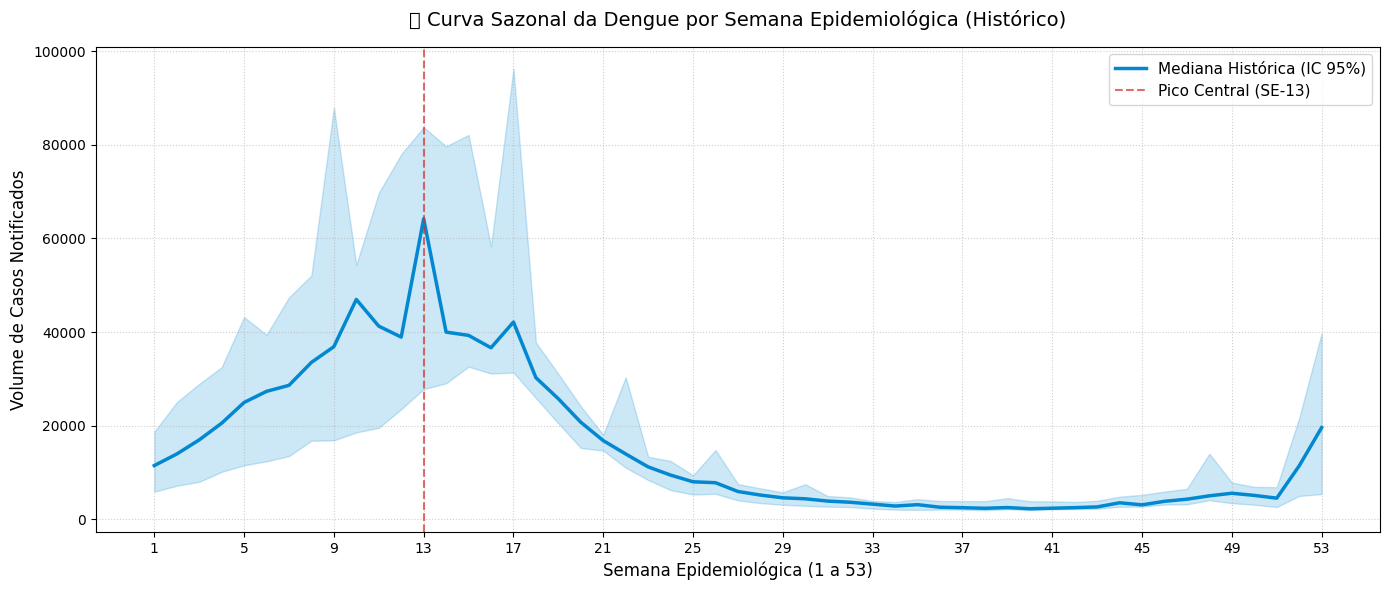

In [ ]:
# @title Análise Sazonal da Dengue em median+IC95%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
arquivo_treino = SEASONS[SEASON_ALVO]['train'].replace('.parquet', '_eng_shap_final.parquet')
arquivo_teste  = SEASONS[SEASON_ALVO]['test'].replace('.parquet', '_eng_shap_final.parquet')
df_train = pd.read_parquet(arquivo_treino)
df_test  = pd.read_parquet(arquivo_teste)
df_train = df_train[df_train[VARS['uf_code']] != 32].reset_index(drop=True)
df_test  = df_test[df_test[VARS['uf_code']] != 32].reset_index(drop=True)
def analisar_sazonalidade_dengue(df_dados, col_data='date', col_casos='casos_dengue'):
    df = df_dados.copy()

    # 1. Garantir o formato de datetime se a coluna for string
    df[col_data] = pd.to_datetime(df[col_data])

    # 2. Extrair o Ano e a Semana Epidemiológica (ISO week)
    df['ano'] = df[col_data].dt.isocalendar().year
    df['semana_epidemiologica'] = df[col_data].dt.isocalendar().week

    # 3. Agrupar os casos por Ano e Semana (Total do território do dataset)
    print("🔄 Agregando série temporal por semana epidemiológica...")
    df_agrupado = df.groupby(['ano', 'semana_epidemiologica'])[col_casos].sum().reset_index()

    # 4. Calcular a métrica de tendência central por semana (Mediana e Média)
    # Usamos a mediana para evitar que um único ano de surto histórico distorça a curva normal
    sazonalidade = df_agrupado.groupby('semana_epidemiologica')[col_casos].agg(['median', 'mean', 'sum']).reset_index()

    # 5. Identificar matematicamente o Top 3 semanas de pico
    top_semanas = sazonalidade.sort_values(by='median', ascending=False).head(5)

    print("\n" + "="*50)
    print("📊 RANKING DAS SEMANAS COM MAIOR TRANSMISSÃO (MEDIANA):")
    print("="*50)
    for idx, row in top_semanas.iterrows():
        print(f"🥇 {idx+1}º Lugar: Semana SE-{int(row['semana_epidemiologica'])} | Mediana de casos: {row['median']:.0f}")
    print("="*50)

    # 6. Plotar o Gráfico de Curva Epidemiológica Sazonal
    plt.figure(figsize=(14, 6))
    sns.lineplot(data=df_agrupado, x='semana_epidemiologica', y=col_casos,
                 estimator=np.median, errorbar=('ci', 95), color='#0288d1', linewidth=2.5, label='Mediana Histórica (IC 95%)')

    # Destacar a região de pico encontrada
    semana_pico_max = top_semanas.iloc[0]['semana_epidemiologica']
    plt.axvline(x=semana_pico_max, color='#d32f2f', linestyle='--', alpha=0.7,
                label= f'Pico Central (SE-{int(semana_pico_max)})')

    plt.title('🧫 Curva Sazonal da Dengue por Semana Epidemiológica (Histórico)', fontsize=14, pad=15)
    plt.xlabel('Semana Epidemiológica (1 a 53)', fontsize=12)
    plt.ylabel('Volume de Casos Notificados', fontsize=12)
    plt.xticks(range(1, 54, 4))
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.legend(loc='upper right', fontsize=11)
    plt.tight_layout()
    plt.show()

    return sazonalidade, top_semanas

# --- Execução no seu ambiente ---
# Substitua 'df_train' pelo nome do seu dataframe carregado
sazonalidade, ranking = analisar_sazonalidade_dengue(df_train, col_data='date', col_casos=VARS['casos_dengue'])

In [ ]:
print(df_train.columns.tolist())

['geocode', 'date', 'epiweek', 'uf_code', 'population', 'uf', 'macroregional_geocode', 'regional_geocode', 'casos.x', 'seno_semana', 'umid_med_forecast', 'imunidade_ewm', 'precip_tot_forecast', 'access_count', 'temp_med_forecast', 'pressure_min', 'casos_chikungunya', 'koppen_encoded', 'time_index', 'casos_suavizados', 'velocidade', 'aceleracao', 'node_id']


# Conciliação Municipal X Estadual

In [ ]:
# @title Reconciliação Hierárquica Mint simples

# ==============================================================================
# RECONCILIAÇÃO HIERÁRQUICA MINT
# ==============================================================================
def reconciliar_mint(df_municipal: pd.DataFrame, df_estadual: pd.DataFrame, col_uf_code: str = 'uf_code') -> tuple:
    if not HF_DISPONIVEL:
        return df_municipal, df_estadual

    print("  [MinT] Reconciliação municipal → estadual vetorizada...")

    cols_quantis = ['pred', 'lower_50', 'upper_50', 'lower_80', 'upper_80', 'lower_90', 'upper_90', 'lower_95', 'upper_95']
    datas = sorted(df_municipal['date'].unique())

    df_mun_rec = df_municipal.copy()
    df_est_rec = df_estadual.copy()

    mapa_uf = df_municipal[[VARS['municipio'], col_uf_code]].drop_duplicates().set_index(VARS['municipio'])[col_uf_code].to_dict()
    geocodes, ufs = sorted(df_municipal[VARS['municipio']].unique()), sorted(df_estadual[col_uf_code].unique())

    n_uf, n_mun = len(ufs), len(geocodes)
    uf_idx, mun_idx = {uf: i for i, uf in enumerate(ufs)}, {g: i for i, g in enumerate(geocodes)}

    # Construção da Matriz de Agregação S (Igual)
    S = np.zeros((n_uf + n_mun, n_mun))
    for g in geocodes:
        if mapa_uf.get(g) in uf_idx:
            S[uf_idx[mapa_uf.get(g)], mun_idx[g]] = 1.0
        S[n_uf + mun_idx[g], mun_idx[g]] = 1.0

    # Matriz de Projeção Ortogonal (OLS / MinT simplificado)
    STS = S.T @ S + 1e-6 * np.eye(n_mun)
    P = S @ np.linalg.solve(STS, S.T)

    # Prepara os DataFrames com MultiIndex para indexação em bloco ultra-rápida
    df_mun_rec = df_mun_rec.set_index([VARS['municipio'], 'date'])
    df_est_rec = df_est_rec.set_index([col_uf_code, 'date'])

    for col in cols_quantis:
        if col not in df_municipal.columns:
            continue

        # 🔥 SOLUÇÃO DO ERRO + OTIMIZAÇÃO 1:
        # O groupby com .mean() reduz qualquer duplicidade acidental a um escalar estável,
        # e o .unstack() monta a matriz de tempo inteira instantaneamente.
        mun_pivot = df_municipal.groupby([VARS['municipio'], 'date'])[col].mean().unstack(level='date')
        est_pivot = df_estadual.groupby([col_uf_code, 'date'])[col].mean().unstack(level='date')

        # OTIMIZAÇÃO 2: Garante o alinhamento perfeito de eixos via reindex (sem loops)
        est_matrix = est_pivot.reindex(index=ufs, columns=datas).fillna(0.0).values
        mun_matrix = mun_pivot.reindex(index=geocodes, columns=datas).fillna(0.0).values

        # Monta o Y_hat completo em uma única colagem vertical
        Y_hat = np.vstack([est_matrix, mun_matrix])

        # Aplica a reconciliação coerente e remove valores negativos
        Y_rec = np.maximum(P @ Y_hat, 0)

        # Separa os blocos reconciliados de volta
        Y_rec_est = Y_rec[:n_uf, :]
        Y_rec_mun = Y_rec[n_uf:, :]

        # 🔥 OTIMIZAÇÃO 3: Transforma as matrizes NumPy de volta para o formato longo do Pandas
        # O método .stack() reconstrói o MultiIndex de forma instantânea.
        df_mun_mapped = pd.DataFrame(Y_rec_mun, index=geocodes, columns=datas)
        df_mun_mapped.index.name = VARS['municipio']
        df_mun_mapped = df_mun_mapped.stack().to_frame(name=col).round(2)
        df_mun_mapped.index.names = [VARS['municipio'], 'date']

        df_est_mapped = pd.DataFrame(Y_rec_est, index=ufs, columns=datas)
        df_est_mapped.index.name = col_uf_code
        df_est_mapped = df_est_mapped.stack().to_frame(name=col).round(2)
        df_est_mapped.index.names = [col_uf_code, 'date']

        # 🔥 OTIMIZAÇÃO 4: Atualização em bloco na memória nativa do Pandas (Substitui milhares de .loc)
        df_mun_rec.update(df_mun_mapped)
        df_est_rec.update(df_est_mapped)

    # Retorna os DataFrames para a estrutura original de colunas comuns
    return df_mun_rec.reset_index(), df_est_rec.reset_index()


In [ ]:
# @title Reconciliar MINT WLS
def reconciliar_mint_wls(df_municipal: pd.DataFrame, df_estadual: pd.DataFrame, col_uf_code: str = 'uf_code') -> tuple:
    if not HF_DISPONIVEL:
        return df_municipal, df_estadual

    print("  [MinT Advanced] Executando Reconciliação HIERÁRQUICA WLS...")

    cols_quantis = ['pred', 'lower_50', 'upper_50', 'lower_80', 'upper_80', 'lower_90', 'upper_90', 'lower_95', 'upper_95']
    datas = sorted(df_municipal['date'].unique())

    df_mun_rec = df_municipal.copy()
    df_est_rec = df_estadual.copy()

    mapa_uf = df_municipal[[VARS['municipio'], col_uf_code]].drop_duplicates().set_index(VARS['municipio'])[col_uf_code].to_dict()
    geocodes, ufs = sorted(df_municipal[VARS['municipio']].unique()), sorted(df_estadual[col_uf_code].unique())

    n_uf, n_mun = len(ufs), len(geocodes)
    uf_idx, mun_idx = {uf: i for i, uf in enumerate(ufs)}, {g: i for i, g in enumerate(geocodes)}

    # 1. Construção da Matriz de Agregação S
    S = np.zeros((n_uf + n_mun, n_mun))
    for g in geocodes:
        if mapa_uf.get(g) in uf_idx:
            S[uf_idx[mapa_uf.get(g)], mun_idx[g]] = 1.0
        S[n_uf + mun_idx[g], mun_idx[g]] = 1.0

    # 🔥 A GRANDE MELHORIA: Construção da Matriz de Pesos W (Variância dos Erros)
    # Calculamos a variância do resíduo (real - pred) para cada município
    variancias = []
    for g in geocodes:
        df_mun_especifico = df_municipal[df_municipal[VARS['municipio']] == g]
        if len(df_mun_especifico) > 1 and 'casos_reais' in df_mun_especifico.columns:
            erros = df_mun_especifico['casos_reais'] - df_mun_especifico['pred']
            var_g = np.var(erros)
            # Adiciona um limitador (shrinkage) para evitar divisão por zero em cidades sem casos
            variancias.append(max(var_g, 1e-3))
        else:
            variancias.append(1.0)

    # Variância para a parte de cima da matriz (Estados)
    # No WLS estrutural, a variância do estado é a soma das variâncias dos seus municípios
    var_estados = np.zeros(n_uf)
    for idx_g, g in enumerate(geocodes):
        uf = mapa_uf.get(g)
        if uf in uf_idx:
            var_estados[uf_idx[uf]] += variancias[idx_g]

    # Vetor completo de variâncias (Estados na parte superior, Municípios na inferior)
    diag_w = np.concatenate([var_estados, np.array(variancias)])

    # Matriz de pesos inversa W^-1 (Diagonal)
    W_inv = np.diag(1.0 / diag_w)

    # 🔥 Nova Projeção Ortogonal Ponderada (Fórmula matemática estrita do MinT-WLS)
    # P = (S^T * W^-1 * S)^-1 * S^T * W^-1
    STS_wls = S.T @ W_inv @ S + 1e-6 * np.eye(n_mun)
    P = np.linalg.solve(STS_wls, S.T @ W_inv)

    # Prepara os DataFrames com MultiIndex para velocidade de bloco
    df_mun_rec = df_mun_rec.set_index([VARS['municipio'], 'date'])
    df_est_rec = df_est_rec.set_index([col_uf_code, 'date'])

    for col in cols_quantis:
        if col not in df_municipal.columns:
            continue

        mun_pivot = df_municipal.groupby([VARS['municipio'], 'date'])[col].mean().unstack(level='date')
        est_pivot = df_estadual.groupby([col_uf_code, 'date'])[col].mean().unstack(level='date')

        est_matrix = est_pivot.reindex(index=ufs, columns=datas).fillna(0.0).values
        mun_matrix = mun_pivot.reindex(index=geocodes, columns=datas).fillna(0.0).values

        Y_hat = np.vstack([est_matrix, mun_matrix])

        # Aplica a reconciliação coerente baseada nas certezas estatísticas locais
        Y_rec = np.maximum(P @ Y_hat, 0)

        Y_rec_est = Y_rec[:n_uf, :]
        Y_rec_mun = Y_rec[n_uf:, :]

        # Mapeamento de volta para formato longo do Pandas
        df_mun_mapped = pd.DataFrame(Y_rec_mun, index=geocodes, columns=datas).stack().to_frame(name=col).round(2)
        df_mun_mapped.index.names = [VARS['municipio'], 'date']

        df_est_mapped = pd.DataFrame(Y_rec_est, index=ufs, columns=datas).stack().to_frame(name=col).round(2)
        df_est_mapped.index.names = [col_uf_code, 'date']

        df_mun_rec.update(df_mun_mapped)
        df_est_rec.update(df_est_mapped)

    return df_mun_rec.reset_index(), df_est_rec.reset_index()

In [ ]:
# @title Reconciliar Mint Dinâmico
import numpy as np
import pandas as pd

def reconciliar_mint_dinamico(df_municipal: pd.DataFrame, df_estadual: pd.DataFrame,
                               semana_inicio_alta: int = 47, semana_fim_alta: int = 25,
                               col_uf_code: str = 'uf_code') -> tuple:
    """
    Executa a Reconciliação Hierárquica Mínimo Traço (MinT) Dinâmica e Sazonal
    baseada nas Semanas Epidemiológicas reais de transmissão da Dengue.
    Suporta janelas temporais que cruzam a virada do ano civil (ex: SE-49 a SE-22).
    """
    print(f"⚙️ [Dynamic MinT] Iniciando reconciliação orientada a dados (Alta Transmissão: SE-{semana_inicio_alta} a SE-{semana_fim_alta})...")

    # Lista de colunas probabilísticas que passarão pelo ajuste geométrico
    cols_quantis = ['pred', 'lower_50', 'upper_50', 'lower_80', 'upper_80', 'lower_90', 'upper_90', 'lower_95', 'upper_95']
    datas = sorted(df_municipal['date'].unique())

    df_mun_rec = df_municipal.copy()
    df_est_rec = df_estadual.copy()

    # Mapeamentos estruturais da malha geográfica
    mapa_uf = df_municipal[[VARS['municipio'], col_uf_code]].drop_duplicates().set_index(VARS['municipio'])[col_uf_code].to_dict()
    geocodes, ufs = sorted(df_municipal[VARS['municipio']].unique()), sorted(df_estadual[col_uf_code].unique())

    n_uf, n_mun = len(ufs), len(geocodes)
    uf_idx, mun_idx = {uf: i for i, uf in enumerate(ufs)}, {g: i for i, g in enumerate(geocodes)}

    # ==============================================================================
    # 1. CONSTRUÇÃO DA MATRIZ DE ESTRUTURA ESPACIAL (S)
    # ==============================================================================
    S = np.zeros((n_uf + n_mun, n_mun), dtype=np.float32)
    for g in geocodes:
        if mapa_uf.get(g) in uf_idx:
            S[uf_idx[mapa_uf.get(g)], mun_idx[g]] = 1.0
        S[n_uf + mun_idx[g], mun_idx[g]] = 1.0

    # ==============================================================================
    # 2. SEPARAÇÃO SAZONAL POR SEMANA EPIDEMIOLÓGICA (DADOS DE TREINO)
    # ==============================================================================
    df_municipal['datetime_aux'] = pd.to_datetime(df_municipal['date'])
    df_municipal['semana_num_aux'] = df_municipal['datetime_aux'].dt.isocalendar().week

    # 🔥 CORREÇÃO: Tratamento de janelas que cruzam a virada do ano civil
    if semana_inicio_alta <= semana_fim_alta:
        mask_alta = df_municipal['semana_num_aux'].between(semana_inicio_alta, semana_fim_alta)
    else:
        mask_alta = (df_municipal['semana_num_aux'] >= semana_inicio_alta) | (df_municipal['semana_num_aux'] <= semana_fim_alta)

    df_alta = df_municipal[mask_alta]
    df_baixa = df_municipal[~mask_alta]

    # ==============================================================================
    # 3. ALGORITMO INTERNO DE CÁLCULO DA MATRIZ DE PROJEÇÃO MINT (P)
    # ==============================================================================
    def calcular_matriz_P(df_fase):
        variancias = []
        for g in geocodes:
            df_mun_g = df_fase[df_fase[VARS['municipio']] == g]
            if len(df_mun_g) > 1 and 'casos_reais' in df_mun_g.columns:
                erros = df_mun_g['casos_reais'] - df_mun_g['pred']
                # Shrinkage estatístico para evitar divisão por zero em locais esparsos
                variancias.append(max(np.var(erros), 1e-3))
            else:
                variancias.append(1.0)

        var_estados = np.zeros(n_uf)
        for idx_g, g in enumerate(geocodes):
            uf = mapa_uf.get(g)
            if uf in uf_idx:
                var_estados[uf_idx[uf]] += variancias[idx_g]

        # Montagem da matriz diagonal de covariância dos erros (W)
        diag_w = np.concatenate([var_estados, np.array(variancias)])
        W_inv = np.diag(1.0 / diag_w)

        # Resolução da equação de Mínimos Quadrados Ponderados (WLS Estrutural)
        STS_wls = S.T @ W_inv @ S + 1e-6 * np.eye(n_mun)
        return np.linalg.solve(STS_wls, S.T @ W_inv)

    # Pré-computação das duas lentes geométricas do ecossistema
    print("    -> Calculando pesos para o bloco de ALTA TRANSMISSÃO (Picos)...")
    P_alta = calcular_matriz_P(df_alta)

    print("    -> Calculando pesos para o bloco de BAIXA TRANSMISSÃO (Entressafra)...")
    P_baixa = calcular_matriz_P(df_baixa)

    # ==============================================================================
    # 4. LOOP DE RECONCILIAÇÃO TEMPORAL PASSO A PASSO
    # ==============================================================================
    df_mun_rec = df_mun_rec.set_index([VARS['municipio'], 'date'])
    df_est_rec = df_est_rec.set_index([col_uf_code, 'date'])

    for col in cols_quantis:
        if col not in df_municipal.columns:
            continue

        # Pivoteamento para processamento vetorial rápido em matrizes
        mun_pivot = df_municipal.groupby([VARS['municipio'], 'date'])[col].mean().unstack(level='date')
        est_pivot = df_estadual.groupby([col_uf_code, 'date'])[col].mean().unstack(level='date')

        est_matrix = est_pivot.reindex(index=ufs, columns=datas).fillna(0.0).values
        mun_matrix = mun_pivot.reindex(index=geocodes, columns=datas).fillna(0.0).values
        Y_hat_total = np.vstack([est_matrix, mun_matrix])

        # Arrays vazios para armazenar as projeções limpas da coluna atual
        Y_rec_final = np.zeros_like(Y_hat_total[n_uf:, :])
        Y_rec_est_final = np.zeros_like(Y_hat_total[:n_uf, :])

        # Roteamento Sazonal Dinâmico coluna por coluna (Semana por Semana)
        for t_idx, data_str in enumerate(datas):
            semana_corrente = pd.to_datetime(data_str).isocalendar().week
            Y_hat_t = Y_hat_total[:, t_idx:t_idx+1]

            # 🔥 CORREÇÃO: Avaliação robusta do roteamento para janelas invertidas
            if semana_inicio_alta <= semana_fim_alta:
                eh_alta_temporada = (semana_inicio_alta <= semana_corrente <= semana_fim_alta)
            else:
                eh_alta_temporada = (semana_corrente >= semana_inicio_alta) or (semana_corrente <= semana_fim_alta)

            # Seleção do operador de projeção ótimo para a assinatura epidemiológica da semana
            if eh_alta_temporada:
                P_t = P_alta
            else:
                P_t = P_baixa

            # 1. Projeção coerente dos nós base municipais (Garante não-negatividade)
            mun_rec_t = np.maximum(P_t @ Y_hat_t, 0)
            Y_rec_final[:, t_idx:t_idx+1] = mun_rec_t

            # 2. Agregação coerente estrita e imediata para o nível Estadual
            Y_rec_est_final[:, t_idx:t_idx+1] = S[:n_uf, :] @ mun_rec_t

        # Mapeamento reverso das matrizes para o formato longo do Pandas Dataframe
        df_mun_mapped = pd.DataFrame(Y_rec_final, index=geocodes, columns=datas).stack().to_frame(name=col).round(2)
        df_mun_mapped.index.names = [VARS['municipio'], 'date']

        df_est_mapped = pd.DataFrame(Y_rec_est_final, index=ufs, columns=datas).stack().to_frame(name=col).round(2)
        df_est_mapped.index.names = [col_uf_code, 'date']

        # Atualização atômica dos arquivos de saída
        df_mun_rec.update(df_mun_mapped)
        df_est_rec.update(df_est_mapped)

    # Limpeza e remoção das colunas auxiliares de tempo do dataframe de entrada
    df_municipal.drop(columns=['datetime_aux', 'semana_num_aux'], inplace=True, errors='ignore')
    print("✅ [Dynamic MinT] Processo concluído. Hierarquia perfeitamente coerente.")

    return df_mun_rec.reset_index(), df_est_rec.reset_index()

In [ ]:
# @title Reconciliar Mint Dinâmico WLS
import numpy as np
import pandas as pd

def reconciliar_mint_dinamico_wls(df_municipal: pd.DataFrame, df_estadual: pd.DataFrame,
                                  semana_inicio_alta: int = 47, semana_fim_alta: int = 25,
                                  col_uf_code: str = 'uf_code', var_municipio: str = 'geocode') -> tuple:
    """
    Executa a Reconciliação Hierárquica MinT combinando roteamento Sazonal Dinâmico
    com Mínimos Quadrados Ponderados (WLS) baseados na variância dos resíduos de cada fase.
    """
    print(f"⚙️ [MinT Dinâmico WLS] Iniciando reconciliação orientada a variância sazonal...")
    print(f"   -> Alta Transmissão: SE-{semana_inicio_alta} a SE-{semana_fim_alta}")

    cols_quantis = ['pred', 'lower_50', 'upper_50', 'lower_80', 'upper_80', 'lower_90', 'upper_90', 'lower_95', 'upper_95']
    datas = sorted(df_municipal['date'].unique())

    df_mun_rec = df_municipal.copy()
    df_est_rec = df_estadual.copy()

    # Mapeamentos estruturais blindados
    mapa_uf = df_municipal[[var_municipio, col_uf_code]].drop_duplicates().set_index(var_municipio)[col_uf_code].to_dict()

    # GARANTIA DE SHAPE: Universo completo e ordenado
    geocodes = sorted(df_municipal[var_municipio].unique())
    ufs = sorted(df_estadual[col_uf_code].unique())

    n_uf, n_mun = len(ufs), len(geocodes)
    uf_idx = {uf: i for i, uf in enumerate(ufs)}
    mun_idx = {g: i for i, g in enumerate(geocodes)}

    # ==============================================================================
    # 1. CONSTRUÇÃO DA MATRIZ DE ESTRUTURA ESPACIAL (S)
    # ==============================================================================
    S = np.zeros((n_uf + n_mun, n_mun), dtype=np.float32)
    for g in geocodes:
        if mapa_uf.get(g) in uf_idx:
            S[uf_idx[mapa_uf.get(g)], mun_idx[g]] = 1.0
        S[n_uf + mun_idx[g], mun_idx[g]] = 1.0

    # ==============================================================================
    # 2. SEPARAÇÃO SAZONAL (TREINO DE VARIÂNCIAS)
    # ==============================================================================
    df_municipal['datetime_aux'] = pd.to_datetime(df_municipal['date'])
    df_municipal['semana_num_aux'] = df_municipal['datetime_aux'].dt.isocalendar().week

    if semana_inicio_alta <= semana_fim_alta:
        mask_alta = df_municipal['semana_num_aux'].between(semana_inicio_alta, semana_fim_alta)
    else:
        mask_alta = (df_municipal['semana_num_aux'] >= semana_inicio_alta) | (df_municipal['semana_num_aux'] <= semana_fim_alta)

    df_alta = df_municipal[mask_alta]
    df_baixa = df_municipal[~mask_alta]

    # ==============================================================================
    # 3. CONSTRUTOR WLS (Mínimos Quadrados Ponderados)
    # ==============================================================================
    def calcular_matriz_P_wls(df_fase, nome_fase):
        variancias = []
        for g in geocodes:
            df_mun_g = df_fase[df_fase[var_municipio] == g]
            if len(df_mun_g) > 1 and 'casos_reais' in df_mun_g.columns:
                erros = df_mun_g['casos_reais'] - df_mun_g['pred']
                # Variância do município na fase específica
                variancias.append(max(np.var(erros), 1e-3))
            else:
                variancias.append(1.0) # Fallback caso não haja dados históricos na janela

        # Agregação da variância para os Estados (Soma WLS hierárquica)
        var_estados = np.zeros(n_uf)
        for idx_g, g in enumerate(geocodes):
            uf = mapa_uf.get(g)
            if uf in uf_idx:
                var_estados[uf_idx[uf]] += variancias[idx_g]

        diag_w = np.concatenate([var_estados, np.array(variancias)])
        W_inv = np.diag(1.0 / diag_w)

        # Projeção Ortogonal Ponderada WLS: P = (S^T * W^-1 * S)^-1 * S^T * W^-1
        STS_wls = S.T @ W_inv @ S + 1e-6 * np.eye(n_mun) # 1e-6 evita matriz singular
        P = np.linalg.solve(STS_wls, S.T @ W_inv)

        print(f"   -> Matriz P_wls ({nome_fase}) calculada e otimizada.")
        return P

    P_alta = calcular_matriz_P_wls(df_alta, "PICO")
    P_baixa = calcular_matriz_P_wls(df_baixa, "SECA")

    # ==============================================================================
    # 4. ROTEAMENTO DINÂMICO E RECONCILIAÇÃO MATRICIAL
    # ==============================================================================
    df_mun_rec = df_mun_rec.set_index([var_municipio, 'date'])
    df_est_rec = df_est_rec.set_index([col_uf_code, 'date'])

    for col in cols_quantis:
        if col not in df_municipal.columns:
            continue

        mun_pivot = df_municipal.groupby([var_municipio, 'date'])[col].mean().unstack(level='date')
        est_pivot = df_estadual.groupby([col_uf_code, 'date'])[col].mean().unstack(level='date')

        # Reindexação estrita para evitar o ValueError de dimensões
        est_matrix = est_pivot.reindex(index=ufs, columns=datas).fillna(0.0).values
        mun_matrix = mun_pivot.reindex(index=geocodes, columns=datas).fillna(0.0).values

        Y_hat_total = np.vstack([est_matrix, mun_matrix])

        Y_rec_final = np.zeros_like(mun_matrix)
        Y_rec_est_final = np.zeros_like(est_matrix)

        for t_idx, data_str in enumerate(datas):
            semana_corrente = pd.to_datetime(data_str).isocalendar().week
            Y_hat_t = Y_hat_total[:, t_idx:t_idx+1]

            if semana_inicio_alta <= semana_fim_alta:
                eh_alta = (semana_inicio_alta <= semana_corrente <= semana_fim_alta)
            else:
                eh_alta = (semana_corrente >= semana_inicio_alta) or (semana_corrente <= semana_fim_alta)

            # O Gatekeeper que define a lente estatística da semana
            P_t = P_alta if eh_alta else P_baixa

            # Reconcilia o nível local evitando projeções negativas
            mun_rec_t = np.maximum(P_t @ Y_hat_t, 0)
            Y_rec_final[:, t_idx:t_idx+1] = mun_rec_t

            # Sobe a projeção coerente de volta para o nível Estadual
            Y_rec_est_final[:, t_idx:t_idx+1] = S[:n_uf, :] @ mun_rec_t

        # Transforma de volta para o layout do Pandas
        df_mun_mapped = pd.DataFrame(Y_rec_final, index=geocodes, columns=datas).stack().to_frame(name=col).round(2)
        df_mun_mapped.index.names = [var_municipio, 'date']

        df_est_mapped = pd.DataFrame(Y_rec_est_final, index=ufs, columns=datas).stack().to_frame(name=col).round(2)
        df_est_mapped.index.names = [col_uf_code, 'date']

        df_mun_rec.update(df_mun_mapped)
        df_est_rec.update(df_est_mapped)

    # Limpeza final das variáveis embutidas no ciclo
    df_municipal.drop(columns=['datetime_aux', 'semana_num_aux'], inplace=True, errors='ignore')

    print("✅ [MinT Dinâmico WLS] Finalizado com sucesso!")

    return df_mun_rec.reset_index(), df_est_rec.reset_index()

# Preparar o AGCRN

In [ ]:
# @title Função de perda BN simples
def nb_loss(log_mu: torch.Tensor, log_r: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    log_mu = torch.clamp(log_mu, min=-10, max=10)
    log_r  = torch.clamp(log_r,  min=-6,  max=6)
    mu, r = torch.exp(log_mu), torch.exp(log_r)
    nll = (
        - torch.lgamma(y + r) + torch.lgamma(r) + torch.lgamma(y + 1)
        - r * torch.log(r / (r + mu + 1e-8)) - y * torch.log(mu / (r + mu + 1e-8))
    )
    return nll.mean()

def nb_quantile(mu: np.ndarray, r: np.ndarray, q: float) -> np.ndarray:
    p = r / (r + mu + 1e-8)
    return nbinom.ppf(q, n=r, p=p).astype(float)

In [ ]:
# @title Função de perda BN penaliza picos
def nb_loss(log_mu: torch.Tensor, log_r: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    log_mu = torch.clamp(log_mu, min=-10, max=10)
    log_r  = torch.clamp(log_r,  min=-6,  max=6)
    mu, r = torch.exp(log_mu), torch.exp(log_r)

    # Cálculo base da log-verossimilhança negativa
    nll = (
        - torch.lgamma(y + r) + torch.lgamma(r) + torch.lgamma(y + 1)
        - r * torch.log(r / (r + mu + 1e-8)) - y * torch.log(mu / (r + mu + 1e-8))
    )

    # 🔥 PONDERAÇÃO DINÂMICA: Dá mais peso estatístico para erros em semanas/cidades com muitos casos
    # O log1p garante que o peso cresça de forma controlada sem explodir o gradiente
    pesos_surto = 1.0 + torch.log1p(y)
    nll_ponderada = nll * pesos_surto

    return nll_ponderada.mean()

    def nb_quantile(mu: np.ndarray, r: np.ndarray, q: float) -> np.ndarray:
    p = r / (r + mu + 1e-8)
    return nbinom.ppf(q, n=r, p=p).astype(float)



In [ ]:
# @title Criação do AGCRN (12 features+dropout+embedings 64)
# ==============================================================================
# AGCRN & BINOMIAL NEGATIVA
# ==============================================================================

COLS_FISICA  = ['casos_suavizados', 'velocidade', 'aceleracao']
COLS_SHAP    = [
    'seno_semana',
    'umid_med_forecast',
    'imunidade_ewm',
    'precip_tot_forecast',
    'access_count',
    'temp_med_forecast',
    'pressure_min',
    'casos_chikungunya',
    'koppen_encoded',
]
COLS_MODELO = COLS_FISICA + COLS_SHAP   # 12 features no total
class PreditorNBAGCRN(nn.Module):
    def __init__(self, num_nodes: int, num_features: int, embedding_dim: int = 64, idx_velocidade: int = 1, idx_aceleracao: int = 2):
        super().__init__()
        self.idx_vel = idx_velocidade
        self.idx_acel = idx_aceleracao
        self.node_embeddings = nn.Parameter(torch.randn(num_nodes, embedding_dim), requires_grad=True)
        self.recurrent = AGCRN(
            number_of_nodes=num_nodes,
            in_channels=num_features,
            out_channels=64,
            K=2,                                   # Ordem de vizinhança espacial
            embedding_dimensions=embedding_dim     # Passando a mesma dimensão (32)
        )

        # 🔥 ALTERAÇÃO 2: Inclusão de Dropout Espaço-Temporal
        # Crucial para combater o sMAPE alto. Evita que a rede decore o ruído de zeros na entressafra.
        self.dropout = nn.Dropout(p=0.2)
        self.head_mu = nn.Linear(64, 1)
        self.head_logr = nn.Linear(64 + 2, 1)

    def forward(self, x: torch.Tensor, log_pop: torch.Tensor, h=None):
        # 1. Adiciona a dimensão de Batch exigida pela nova versão do AGCRN
        # x passa de [num_nodes, features] para [1, num_nodes, features]
        x_batched = x.unsqueeze(0)

        # 2. Passa pela rede recorrente
        h = self.recurrent(x_batched, self.node_embeddings, h)

        h_out = h.squeeze(0)

        h_relu = F.relu(h_out)
        h_reg = self.dropout(h_relu) # Base correta
        log_mu_raw = self.head_mu(h_relu)
        log_mu = log_mu_raw + log_pop.unsqueeze(-1)

        vel = x[:, self.idx_vel].unsqueeze(-1)
        acel = x[:, self.idx_acel].unsqueeze(-1)
        h_r = torch.cat([h_relu, vel, acel], dim=-1)
        log_r = self.head_logr(h_r)

        # Retorna o log_mu e log_r processados, e o h original (com batch) para a próxima iteração
        return log_mu, log_r, h


In [ ]:
# @title NOVA VALIDAÇÃO E TREINO (dados em float16+cudn.benchmarkTRUE+earlystoppingMAE+standardScaller+compile+AdamW)
def treinar_e_validar_season(df_train: pd.DataFrame, df_test: pd.DataFrame,
                             season_id: int,
                             encoder_means_globais: dict,
                             num_nodes: int, mapa_simples: pd.DataFrame, epochs_max: int = 150, patience: int = 25) -> dict:

    torch.backends.cudnn.benchmark = True

    df_tr, df_tgt = df_train.copy(), df_test.copy()

    if 'log_pop' not in df_tr.columns:
        df_tr['log_pop'] = np.log(df_tr[VARS['populacao']].clip(lower=1).astype(float))
    if 'log_pop' not in df_tgt.columns:
        df_tgt['log_pop'] = np.log(df_tgt[VARS['populacao']].clip(lower=1).astype(float))

    semanas_treino = sorted(df_tr[VARS['semana_epi']].unique())
    df_tr_real = df_tr[df_tr[VARS['semana_epi']].isin(semanas_treino[:-10])]
    df_val_int = df_tr[df_tr[VARS['semana_epi']].isin(semanas_treino[-10:])]

    df_tr_sort  = df_tr_real.merge(mapa_simples, on=VARS['municipio'], how='left').sort_values(['time_index', 'node_id'])
    df_val_sort = df_val_int.merge(mapa_simples, on=VARS['municipio'], how='left').sort_values(['time_index', 'node_id'])
    df_tgt_sort = df_tgt.merge(mapa_simples, on=VARS['municipio'], how='left').sort_values(['time_index', 'node_id'])

    cols = [c for c in COLS_MODELO if c in df_tr_sort.columns]
    num_features = len(cols)

    idx_vel  = cols.index('velocidade')  if 'velocidade'  in cols else 1
    idx_acel = cols.index('aceleracao')  if 'aceleracao'  in cols else 2

    tempos_tr  = sorted(df_tr_sort['time_index'].unique())
    tempos_val = sorted(df_val_sort['time_index'].unique())
    tempos_tgt = sorted(df_tgt_sort['time_index'].unique())

    scaler_X = StandardScaler()
    X_tr_sc  = scaler_X.fit_transform(df_tr_sort[cols].fillna(0))
    X_val_sc = scaler_X.transform(df_val_sort[cols].fillna(0))
    X_tgt_sc = scaler_X.transform(df_tgt_sort[cols].fillna(0))

    # 🔥 ACELERAÇÃO 1: Armazena os recursos diretamente em Float16 na GPU (economiza VRAM bandwidth e CPU)
    def _to_tensor(X_sc, tempos): return torch.tensor(X_sc.reshape(len(tempos), num_nodes, num_features), dtype=torch.float16).to(device)
    def _pop_tensor(df_sort, tempos): return torch.tensor(df_sort['log_pop'].values.reshape(len(tempos), num_nodes), dtype=torch.float16).to(device)
    # Alvos (Y) permanecem em Float32 para estabilidade matemática da perda (lgamma)
    def _casos_tensor(df_sort, tempos): return torch.tensor(df_sort[VARS['casos_dengue']].fillna(0).values.reshape(len(tempos), num_nodes), dtype=torch.float32).to(device)

    X_tr_t, X_val_t, X_tgt_t = _to_tensor(X_tr_sc, tempos_tr), _to_tensor(X_val_sc, tempos_val), _to_tensor(X_tgt_sc, tempos_tgt)
    logpop_tr_t, logpop_val_t, logpop_tgt_t = _pop_tensor(df_tr_sort, tempos_tr), _pop_tensor(df_val_sort, tempos_val), _pop_tensor(df_tgt_sort, tempos_tgt)
    Y_tr_t, Y_val_t = _casos_tensor(df_tr_sort, tempos_tr), _casos_tensor(df_val_sort, tempos_val)

    # 🔥 ALÍVIO DE RAM DA CPU: Deleta imediatamente os DataFrames pesados que já viraram tensores
    # Mantemos apenas o df_tgt_sort que será usado no retorno final
    del df_tr, df_tr_real, df_val_int, df_tr_sort, df_val_sort
    del X_tr_sc, X_val_sc, X_tgt_sc
    import gc
    gc.collect() # Força a RAM do sistema a cair instantaneamente

    modelo = PreditorNBAGCRN(
        num_nodes=num_nodes, num_features=num_features, embedding_dim=32, idx_velocidade=idx_vel, idx_aceleracao=idx_acel
    ).to(device)

    modelo = torch.compile(modelo)

    # 🔥 AGORA: Upgrade para AdamW com decaimento de peso desacoplado
    otimizador = torch.optim.AdamW(modelo.parameters(), lr=0.004, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(otimizador, patience=5, factor=0.5, min_lr=1e-5)

    melhor_mae_val = float('inf')
    melhor_estado = None
    sem_melhora = 0

    # 🔥 ACELERAÇÃO 2: Faz a transferência do alvo de validação para a CPU UMA ÚNICA VEZ fora do loop
    Y_val_t_np = Y_val_t.cpu().numpy()

    barra = tqdm(range(epochs_max), desc=f'  Treino S{season_id}', unit='epoch', file=sys.stdout)
    modelo.train()
    for epoch in barra:
        h, loss_epoch = None, 0.0
        for t in range(len(tempos_tr) - 1):
            otimizador.zero_grad()

            with torch.amp.autocast(device_type='cuda', dtype=torch.float16):
                log_mu, log_r, h = modelo(X_tr_t[t], logpop_tr_t[t], h)
                h = h.detach().clone()
                alvo = Y_tr_t[t + 1].unsqueeze(-1)
                loss = nb_loss(log_mu, log_r, alvo)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            otimizador.step()
            loss_epoch += loss.detach()

        loss_epoch_scalar = float(loss_epoch.cpu()) / (len(tempos_tr) - 1)

        # --- Validação ---
        modelo.eval()
        with torch.no_grad():
            h_val, preds_mu = None, []
            with torch.amp.autocast(device_type='cuda', dtype=torch.float16):
                for t in range(len(tempos_val)):
                    log_mu_v, _, h_val = modelo(X_val_t[t], logpop_val_t[t], h_val)
                    if h_val is not None:
                        h_val = h_val.clone()
                    preds_mu.append(torch.exp(log_mu_v).squeeze(-1))

        preds_mu_np = torch.stack(preds_mu).cpu().numpy()

        # Usa a matriz já presente na CPU (Removeu o gargalo de sincronização de épocas)
        mae_val = np.mean(np.abs(preds_mu_np - Y_val_t_np))
        scheduler.step(mae_val)
        barra.set_postfix({'Loss': f'{loss_epoch_scalar:.4f}', 'MAE': f'{mae_val:.1f}'})

        if mae_val < melhor_mae_val - 1e-3:
            melhor_mae_val = mae_val
            melhor_estado = {k: v.clone() for k, v in modelo.state_dict().items()}
            sem_melhora = 0
        else:
            sem_melhora += 1
            if sem_melhora >= patience: break
        modelo.train()

    if melhor_estado:
        modelo.load_state_dict(melhor_estado)
        torch.save(melhor_estado, f"modelo_agcrn_season_{season_id}.pt")

    # --- Predição Final ---
    modelo.eval()
    preds_mu_tgt, preds_r_tgt = [], []
    with torch.no_grad():
        h_tgt = None
        with torch.amp.autocast(device_type='cuda', dtype=torch.float16):
            for t in range(len(tempos_tgt)):
                log_mu_t, log_r_t, h_tgt = modelo(X_tgt_t[t], logpop_tgt_t[t], h_tgt)
                if h_tgt is not None:
                    h_tgt = h_tgt.clone()
                preds_mu_tgt.append(torch.exp(log_mu_t).squeeze(-1))
                preds_r_tgt.append(torch.exp(log_r_t).squeeze(-1))

    preds_mu_tgt_np = torch.stack(preds_mu_tgt).cpu().numpy()
    preds_r_tgt_np = torch.stack(preds_r_tgt).cpu().numpy()

    return {
        'season_id': season_id,
        'preds_mu_np': np.maximum(preds_mu_tgt_np, 0),
        'preds_r_np': np.maximum(preds_r_tgt_np, 1e-3),
        'df_tgt_sort': df_tgt_sort,
        'mapa_simples': mapa_simples,
    }

In [ ]:
# @title Montar submissao AGCRN
# ==============================================================================
# GERAÇÃO DA SUBMISSÃO MUNICIPAL (COM CASOS REAIS)
# ==============================================================================
def montar_submissao_agcrn(resultado_agcrn: dict) -> pd.DataFrame:
    df_tgt_sort  = resultado_agcrn['df_tgt_sort']
    mapa_simples = resultado_agcrn['mapa_simples']
    mu_agcrn     = resultado_agcrn['preds_mu_np']
    r_agcrn      = resultado_agcrn['preds_r_np']

    geocodes = mapa_simples[VARS['municipio']].values
    semanas  = sorted(df_tgt_sort[VARS['semana_epi']].unique())

    quantis_necessarios = {
        'lower_95': 0.025, 'lower_90': 0.05, 'lower_80': 0.10, 'lower_50': 0.25,
        'upper_50': 0.75,  'upper_80': 0.90, 'upper_90': 0.95, 'upper_95': 0.975,
    }

    rows = []
    for t_idx, semana in enumerate(semanas):
        mu_t = mu_agcrn[t_idx]
        r_t  = r_agcrn[t_idx]
        for n_idx, geocode in enumerate(geocodes):
            mu = float(mu_t[n_idx])
            r  = float(r_t[n_idx])

            pred_med = float(nb_quantile(np.array([mu]), np.array([r]), 0.50)[0])
            row = {
                VARS['municipio']:  geocode,
                VARS['semana_epi']: semana,
                'pred':             round(max(pred_med, 0), 2),
            }
            for col_name, q in quantis_necessarios.items():
                row[col_name] = round(max(float(nb_quantile(np.array([mu]), np.array([r]), q)[0]), 0), 2)
            rows.append(row)

    df_pred = pd.DataFrame(rows)

    df_pred['date_parsed'] = pd.to_datetime(df_pred[VARS['semana_epi']].astype(str) + '-0', format='%G%V-%w')
    df_pred['date'] = df_pred['date_parsed'].dt.strftime('%Y-%m-%d')

    todas_datas = pd.date_range(start=df_pred['date_parsed'].min(), end=df_pred['date_parsed'].max(), freq='W-SUN')
    grade = pd.MultiIndex.from_product([geocodes, todas_datas], names=[VARS['municipio'], 'date_parsed']).to_frame().reset_index(drop=True)
    grade['date'] = grade['date_parsed'].dt.strftime('%Y-%m-%d')

    df_pred = pd.merge(grade, df_pred, on=[VARS['municipio'], 'date', 'date_parsed'], how='left')

    # Merge target cases
    df_reais = df_tgt_sort[[VARS['municipio'], VARS['semana_epi'], VARS['casos_dengue']]].rename(columns={VARS['casos_dengue']: 'casos_reais'})
    df_reais['date_parsed'] = pd.to_datetime(df_reais[VARS['semana_epi']].astype(str) + '-0', format='%G%V-%w')

    df_pred = pd.merge(df_pred, df_reais[[VARS['municipio'], 'date_parsed', 'casos_reais']], on=[VARS['municipio'], 'date_parsed'], how='left')

    cols_pred = ['pred'] + list(quantis_necessarios.keys())
    for col in cols_pred:
        df_pred[col] = df_pred.groupby(VARS['municipio'])[col].transform(lambda x: x.interpolate('linear').bfill().ffill())
        df_pred[col] = np.maximum(df_pred[col], 0).round(2)

    colunas_finais = [
        VARS['municipio'], 'date', 'casos_reais', 'pred',
        'lower_50', 'upper_50', 'lower_80', 'upper_80',
        'lower_90', 'upper_90', 'lower_95', 'upper_95',
    ]
    return df_pred[colunas_finais].sort_values(by=[VARS['municipio'], 'date']).reset_index(drop=True)


# Execução e avaliação

In [ ]:
# @title EXECUÇÃO PRINCIPAL

# EXECUÇÃO PRINCIPAL
# ==============================================================================
if __name__ == '__main__':
    # --------------------------------------------------------------------------
    # CONTROLE MANUAL DE EXECUÇÃO
    # Defina aqui qual Season deve ser executada (1, 2, 3 ou 4)
    # --------------------------------------------------------------------------
    SEASON_ALVO = 1

    # Carrega os arquivos JÁ PRÉ-PROCESSADOS do disco
    arquivo_treino = SEASONS[SEASON_ALVO]['train'].replace('.parquet', '_eng_shap_final.parquet')
    arquivo_teste  = SEASONS[SEASON_ALVO]['test'].replace('.parquet', '_eng_shap_final.parquet')

    print(f"Carregando datasets pré-processados:\n  - {arquivo_treino}\n  - {arquivo_teste}")
    df_train = pd.read_parquet(arquivo_treino)
    df_test  = pd.read_parquet(arquivo_teste)
    df_train = df_train[df_train[VARS['uf_code']] != 32].reset_index(drop=True)
    df_test  = df_test[df_test[VARS['uf_code']] != 32].reset_index(drop=True)

    print(f"Espírito Santo removido. Linhas restantes -> Treino: {len(df_train)} | Teste: {len(df_test)}")
    # O mapa de nós é extraído do dataframe
    mapa_simples = df_train[[VARS['municipio']]].drop_duplicates().sort_values(VARS['municipio']).reset_index(drop=True)
    mapa_simples['node_id'] = mapa_simples.index
    num_nodes = len(mapa_simples)

    # --------------------------------------------------------------------------
    # FEATURES DO MODELO (Física da epidemia + Top SHAP rankeadas anteriormente)
    # --------------------------------------------------------------------------

    db_conn = sqlite3.connect('resultados_agcrn.db')

    print(f"\n{'='*60}")
    print(f"  EXECUÇÃO ISOLADA: SEASON {SEASON_ALVO} ({SEASONS[SEASON_ALVO]['label']})")
    print(f"{'='*60}")

    # 1. Treinamento
    res_agcrn = treinar_e_validar_season(
        df_train=df_train,
        df_test=df_test,
        season_id=SEASON_ALVO,
        encoder_means_globais={}, # Parâmetro residual da assinatura original (mantido vazio)
        num_nodes=num_nodes,
        mapa_simples=mapa_simples,
        epochs_max=150,
        patience=15
    )

    # 2. DataFrame Municipal (com Casos Reais)
    df_mun = montar_submissao_agcrn(res_agcrn)

    # Mapeamento do uf_code (agora diretamente do df_train pré-processado)
    mapa_uf_code = df_train[[VARS['municipio'], VARS['uf_code']]].drop_duplicates()
    df_mun = df_mun.merge(mapa_uf_code, on=VARS['municipio'], how='left')

    # 3. Aggregation para DataFrame Estadual Baseline (com Casos Reais)
    cols_agregacao = ['pred', 'lower_50', 'upper_50', 'lower_80', 'upper_80', 'lower_90', 'upper_90', 'lower_95', 'upper_95', 'casos_reais']
    df_est = df_mun.groupby([VARS['uf_code'], 'date'])[cols_agregacao].sum().reset_index()

    # 4. Reconciliação MinT
    df_mun_rec, df_est_rec = reconciliar_mint(df_mun, df_est, col_uf_code=VARS['uf_code'])

    # 5. Salvar no Banco de Dados
    df_mun_rec['season'] = SEASON_ALVO
    df_est_rec['season'] = SEASON_ALVO

    df_mun_rec.to_sql('municipal_results', db_conn, if_exists='append', index=False)
    df_est_rec.to_sql('estadual_results', db_conn, if_exists='append', index=False)

    print(f"  Resultados S{SEASON_ALVO} salvos com sucesso no banco de dados SQLite.")

    db_conn.close()
    print("\n✅ Execução finalizada.")

Carregando datasets pré-processados:
  - train1_dengue_eng_shap_final.parquet
  - test1_dengue_eng_shap_final.parquet
Espírito Santo removido. Linhas restantes -> Treino: 4179412 | Teste: 340504

  EXECUÇÃO ISOLADA: SEASON 1 (2022-2023)


  Treino S1:   0%|          | 0/150 [00:00<?, ?epoch/s]

  [MinT] Reconciliação municipal → estadual vetorizada...
  Resultados S1 salvos com sucesso no banco de dados SQLite.

✅ Execução finalizada.


In [ ]:
# @title Avaliar Desempenho
import sqlite3
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr

def avaliar_desempenho_season(db_path: str = 'resultados_agcrn.db', season_id: int = 1):
    """
    Conecta ao banco de dados SQLite, extrai as predições reconciliadas (MinT)
    e calcula as métricas de validação científica (MAE, RMSE, sMAPE e Pearson)
    nos níveis municipal e estadual.
    """
    # 1. Conexão e extração de dados
    conn = sqlite3.connect(db_path)
    df_mun = pd.read_sql(f"SELECT * FROM municipal_results WHERE season = {season_id}", conn)
    df_est = pd.read_sql(f"SELECT * FROM estadual_results WHERE season = {season_id}", conn)
    conn.close()

    if df_mun.empty or df_est.empty:
        print(f"❌ Nenhum registro encontrado para a Season {season_id} no banco '{db_path}'.")
        return

    # 2. Função matemática interna para o bloco de métricas
    def _calcular_metricas(y_real, y_pred):
        # Erros Absolutos e Quadráticos
        mae = mean_absolute_error(y_real, y_pred)
        rmse = np.sqrt(mean_squared_error(y_real, y_pred))

        # sMAPE (Symmetric Mean Absolute Percentage Error) protegido contra divisões por zero
        denominador = (np.abs(y_real) + np.abs(y_pred)) / 2
        smape = np.mean(np.where(denominador == 0, 0, np.abs(y_real - y_pred) / denominador)) * 100

        # Correlação de Pearson (Captura de tendência e sincronia temporal)
        if np.std(y_real) == 0 or np.std(y_pred) == 0:
            pearson = 0.0
        else:
            pearson, _ = pearsonr(y_real, y_pred)

        return mae, rmse, smape, pearson

    # 3. Extração dos vetores de análise (Real vs Reconciliado)
    y_real_mun = df_mun['casos_reais'].fillna(0.0).values
    y_pred_mun = df_mun['pred'].fillna(0.0).values

    y_real_est = df_est['casos_reais'].fillna(0.0).values
    y_pred_est = df_est['pred'].fillna(0.0).values

    # 4. Execução dos cálculos
    mae_m, rmse_m, smape_m, pearson_m = _calcular_metricas(y_real_mun, y_pred_mun)
    mae_e, rmse_e, smape_e, pearson_e = _calcular_metricas(y_real_est, y_pred_est)

    # 5. Exibição do Relatório com Rigor Acadêmico
    print(f"\n" + "="*65)
    print(f"      RELATÓRIO DE PERFORMANCE EPIDEMIOLÓGICA — SEASON {season_id}")
    print("="*65)
    print(f"📊 NÍVEL MUNICIPAL (Granularidade Espaço-Tempo Local):")
    print(f"  • MAE   : {mae_m:.2f} casos (Magnitude média do erro por cidade-semana)")
    print(f"  • RMSE  : {rmse_m:.2f} casos (Sensível a erros em picos epidêmicos)")
    print(f"  • sMAPE : {smape_m:.2f}% (Métrica percentual robusta a baixos baselines)")
    print(f"  • Pearson: {pearson_m:.4f} (Sincronia da curva de transmissão local)")
    print("-"*65)
    print(f"🏛️ NÍVEL ESTADUAL (Agregação Macro Regional):")
    print(f"  • MAE   : {mae_e:.2f} casos (Magnitude média do erro por estado-semana)")
    print(f"  • RMSE  : {rmse_e:.2f} casos")
    print(f"  • sMAPE : {smape_e:.2f}%")
    print(f"  • Pearson: {pearson_e:.4f} (Capacidade de prever o timing do pico macro)")
    print("="*65 + "\n")

# ==============================================================================
# DISPARO DO SCRIPT DE ANÁLISE
# ==============================================================================
if __name__ == '__main__':
    # Altere o ID da Season conforme desejar avaliar
    avaliar_desempenho_season(db_path='resultados_agcrn.db', season_id=1)


      RELATÓRIO DE PERFORMANCE EPIDEMIOLÓGICA — SEASON 1
📊 NÍVEL MUNICIPAL (Granularidade Espaço-Tempo Local):
  • MAE   : 5.14 casos (Magnitude média do erro por cidade-semana)
  • RMSE  : 52.03 casos (Sensível a erros em picos epidêmicos)
  • sMAPE : 69.49% (Métrica percentual robusta a baixos baselines)
  • Pearson: 0.4473 (Sincronia da curva de transmissão local)
-----------------------------------------------------------------
🏛️ NÍVEL ESTADUAL (Agregação Macro Regional):
  • MAE   : 837.51 casos (Magnitude média do erro por estado-semana)
  • RMSE  : 2586.25 casos
  • sMAPE : 69.35%
  • Pearson: 0.6709 (Capacidade de prever o timing do pico macro)



/tmp/ipykernel_21506/3606443378.py:32: RuntimeWarning: invalid value encountered in divide
  smape = np.mean(np.where(denominador == 0, 0, np.abs(y_real - y_pred) / denominador)) * 100


In [ ]:
# @title GRÁFICO DE PREDIÇÕES ESTADUAIS
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plotar_grid_geofacet_brasil_hd(df_estadual_resultados, col_uf=VARS['uf_code']):
    """
    Gera e salva o grid geofacet do Brasil em ULTRA ALTA RESOLUÇÃO (4000x4000px)
    para análise detalhada com zoom.
    """
    df_plot = df_estadual_resultados.copy()
    df_plot['date'] = pd.to_datetime(df_plot['date'])
    df_plot = df_plot.sort_values('date')

    # Matriz do Layout Geográfico do Brasil
    grid_brasil = {
        14: {'uf': 'RR', 'row': 0, 'col': 1},
        16: {'uf': 'AP', 'row': 0, 'col': 4},
        12: {'uf': 'AC', 'row': 1, 'col': 0},
        13: {'uf': 'AM', 'row': 1, 'col': 1},
        11: {'uf': 'RO', 'row': 1, 'col': 2},
        15: {'uf': 'PA', 'row': 1, 'col': 3},
        17: {'uf': 'TO', 'row': 1, 'col': 4},
        21: {'uf': 'MA', 'row': 1, 'col': 5},
        23: {'uf': 'CE', 'row': 1, 'col': 6},
        24: {'uf': 'RN', 'row': 1, 'col': 7},
        51: {'uf': 'MT', 'row': 2, 'col': 2},
        52: {'uf': 'GO', 'row': 2, 'col': 3},
        53: {'uf': 'DF', 'row': 2, 'col': 4},
        22: {'uf': 'PI', 'row': 2, 'col': 5},
        26: {'uf': 'PE', 'row': 2, 'col': 6},
        25: {'uf': 'PB', 'row': 2, 'col': 7},
        50: {'uf': 'MS', 'row': 3, 'col': 2},
        31: {'uf': 'MG', 'row': 3, 'col': 3},
        29: {'uf': 'BA', 'row': 3, 'col': 4},
        27: {'uf': 'AL', 'row': 3, 'col': 5},
        28: {'uf': 'SE', 'row': 3, 'col': 6},
        35: {'uf': 'SP', 'row': 4, 'col': 3},
        33: {'uf': 'RJ', 'row': 4, 'col': 4},
        32: {'uf': 'ES', 'row': 4, 'col': 5},
        41: {'uf': 'PR', 'row': 5, 'col': 2},
        42: {'uf': 'SC', 'row': 5, 'col': 3},
        43: {'uf': 'RS', 'row': 6, 'col': 2}
    }

    total_linhas, total_colunas = 7, 8

    # 📐 Definindo 20x20 polegadas para proporção perfeita de 4000x4000 a 200 DPI
    fig, axes = plt.subplots(total_linhas, total_colunas, figsize=(20, 20), sharex=False)

    for r in range(total_linhas):
        for c in range(total_colunas):
            axes[r, c].axis('off')

    for code, info in grid_brasil.items():
        r, c = info['row'], info['col']
        sigla = info['uf']
        ax = axes[r, c]

        df_uf = df_plot[df_plot[col_uf] == code]
        if df_uf.empty:
            continue

        ax.axis('on')
        ax.set_facecolor('#ffffff')

        # Ajuste leve na opacidade e espessura para suportar a alta densidade de pixels
        ax.fill_between(df_uf['date'], df_uf['lower_95'], df_uf['upper_95'],
                        color='#1e88e5', alpha=0.18, label='IC 95%' if (r==1 and c==0) else "")

        ax.plot(df_uf['date'], df_uf['pred'], color='#00468b', linewidth=2.5,
                label='Predito (Dynamic MinT)' if (r==1 and c==0) else "")

        ax.plot(df_uf['date'], df_uf['casos_reais'], color='#d32f2f', linewidth=2, linestyle=':',
                label='Real Observado' if (r==1 and c==0) else "")

        ax.set_title(f"📍 {sigla}", fontsize=14, weight='bold', pad=6)
        ax.tick_params(axis='both', which='major', labelsize=9)
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.tick_params(axis='x', rotation=45)
        ax.set_ylim(bottom=0)

    fig.legend(loc='upper right', bbox_to_anchor=(0.85, 0.95), fontsize=14, frameon=True, facecolor='white')

    plt.suptitle(f'🗺️ Validação Hierárquica Espaço-Temporal: AGCRN + Dynamic MinT (Season {SEASON_ALVO})',
                 fontsize=20, weight='bold', y=0.96)

    plt.subplots_adjust(wspace=0.4, hspace=0.5)

    # ==============================================================================
    # 💾 EXPORTAÇÃO EM ULTRA ALTA RESOLUÇÃO (4000 x 4000 pixels)
    # ==============================================================================
    nome_arquivo = f'validacao_brasil_season_{SEASON_ALVO}_4K.png'

    print(f"💾 Renderizando e salvando imagem em alta resolução ({nome_arquivo})...")
    plt.savefig(nome_arquivo,
                dpi=200,                # 20 polegadas * 200 DPI = 4000 pixels
                bbox_inches='tight',    # Remove bordas brancas sobressalentes e protege textos
                facecolor='white',      # Garante fundo opaco
                transparent=False)

    plt.show()

    # ⚡ Gatilho de download automático para o ecossistema Google Colab
    try:
        from google.colab import files
        print("📥 Iniciando download automático para a sua máquina...")
        files.download(nome_arquivo)
    except ImportFalse:
        print(f"Arquivo salvo localmente no diretório como: {nome_arquivo}")

# Executar a plotagem com download automático
plotar_grid_geofacet_brasil_hd(df_est_rec)

NameError: name 'df_est_rec' is not defined

# Miscelânea e backups

In [ ]:
# @title Salvar modelo
import torch
from google.colab import files

# ==============================================================================
# 1. SALVAR O MODELO ATUAL DA MEMÓRIA
# ==============================================================================
# Se você usou o torch.compile(), extraímos o '_orig_mod' para salvar os pesos limpos
if 'modelo' in globals():
    modelo_limpo = modelo._orig_mod if hasattr(modelo, '_orig_mod') else modelo
    nome_modelo = f"modelo_agcrn_season_{SEASON_ALVO}.pt"

    torch.save(modelo_limpo.state_dict(), nome_modelo)
    print(f"✅ Pesos do modelo salvos com sucesso em: '{nome_modelo}'")
else:
    print("⚠️ O objeto 'modelo' não foi encontrado nesta sessão do notebook (talvez o treino tenha rodado dentro de uma função isolada).")

# ==============================================================================
# 2. BAIXAR OS ARQUIVOS DIRETO PARA SUA MÁQUINA LOCAL
# ==============================================================================
print("📥 Iniciando o download dos arquivos para o seu computador...")

# Baixa o banco de dados SQLite
files.download('resultados_agcrn.db')

# Baixa os pesos do modelo (se tiver sido gerado acima)
if 'modelo' in globals():
    files.download(nome_modelo)

⚠️ O objeto 'modelo' não foi encontrado nesta sessão do notebook (talvez o treino tenha rodado dentro de uma função isolada).
📥 Iniciando o download dos arquivos para o seu computador...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# @title Reconciliação hierárquica de backup (min dinâmico)
# ==============================================================================
# CONTINUIDADE DA EXECUÇÃO (USANDO OS DADOS DA MEMÓRIA)
# ==============================================================================

# 2. DataFrame Municipal (com Casos Reais)
df_mun = montar_submissao_agcrn(res_agcrn)

# Mapeamento do uf_code (usando os DataFrames que já estão na memória)
mapa_uf_code = df_train[[VARS['municipio'], VARS['uf_code']]].drop_duplicates()
df_mun = df_mun.merge(mapa_uf_code, on=VARS['municipio'], how='left')

# 3. Aggregation para DataFrame Estadual Baseline (com Casos Reais)
cols_agregacao = ['pred', 'lower_50', 'upper_50', 'lower_80', 'upper_80', 'lower_90', 'upper_90', 'lower_95', 'upper_95', 'casos_reais']
df_est = df_mun.groupby([VARS['uf_code'], 'date'])[cols_agregacao].sum().reset_index()

# 4. Reconciliação MinT (Configurada para o ciclo biológico real da SE-49 à SE-22)
df_mun_rec, df_est_rec = reconciliar_mint_dinamico(
    df_municipal=df_mun,
    df_estadual=df_est,
    semana_inicio_alta=49,  # Início do alargamento da variância no fim do ano
    semana_fim_alta=22,     # Fim do pico epidemiológico e retorno ao platô seco
    col_uf_code=VARS['uf_code']
)

# 5. Salvar no Banco de Dados SQLite
db_conn = sqlite3.connect('resultados_agcrn.db')

df_mun_rec['season'] = SEASON_ALVO
df_est_rec['season'] = SEASON_ALVO

df_mun_rec.to_sql('municipal_results', db_conn, if_exists='append', index=False)
df_est_rec.to_sql('estadual_results', db_conn, if_exists='append', index=False)

db_conn.close()

print(f"✨ Sucesso! Dados da Season {SEASON_ALVO} reconciliados e salvos no banco de dados sem precisar retreinar!")

⚙️ [Dynamic MinT] Iniciando reconciliação orientada a dados (Alta Transmissão: SE-49 a SE-22)...
    -> Calculando pesos para o bloco de ALTA TRANSMISSÃO (Picos)...
    -> Calculando pesos para o bloco de BAIXA TRANSMISSÃO (Entressafra)...
✅ [Dynamic MinT] Processo concluído. Hierarquia perfeitamente coerente.
✨ Sucesso! Dados da Season 1 reconciliados e salvos no banco de dados sem precisar retreinar!


In [ ]:
# @title Reconciliação hierárquica de backup
# ==============================================================================
# CONTINUIDADE DA EXECUÇÃO (USANDO OS DADOS DA MEMÓRIA)
# ==============================================================================

# 2. DataFrame Municipal (com Casos Reais)
df_mun = montar_submissao_agcrn(res_agcrn)

# Mapeamento do uf_code (usando os DataFrames que já estão na memória)
mapa_uf_code = df_train[[VARS['municipio'], VARS['uf_code']]].drop_duplicates()
df_mun = df_mun.merge(mapa_uf_code, on=VARS['municipio'], how='left')

# 3. Aggregation para DataFrame Estadual Baseline (com Casos Reais)
cols_agregacao = ['pred', 'lower_50', 'upper_50', 'lower_80', 'upper_80', 'lower_90', 'upper_90', 'lower_95', 'upper_95', 'casos_reais']
df_est = df_mun.groupby([VARS['uf_code'], 'date'])[cols_agregacao].sum().reset_index()

# 4. Reconciliação MinT (Chama a versão nova corrigida que está na memória)
df_mun_rec, df_est_rec = reconciliar_mint_wls(df_mun, df_est, col_uf_code=VARS['uf_code'])

# 5. Salvar no Banco de Dados SQLite
db_conn = sqlite3.connect('resultados_agcrn.db')

df_mun_rec['season'] = SEASON_ALVO
df_est_rec['season'] = SEASON_ALVO

df_mun_rec.to_sql('municipal_results', db_conn, if_exists='append', index=False)
df_est_rec.to_sql('estadual_results', db_conn, if_exists='append', index=False)

db_conn.close()

print(f"✨ Sucesso! Dados da Season {SEASON_ALVO} reconciliados e salvos no banco de dados sem precisar retreinar!")

NameError: name 'res_agcrn' is not defined

In [ ]:
# @title GERAÇÃO DE PREVISÕES EM MODO CPU (RECUPERAÇÃO DE DESASTRE)
import os
import gc
import torch
import numpy as np
import pandas as pd

# 1. Configurar o dispositivo para CPU
device = torch.device('cpu')
print(f"🚀 Modo de Recuperação: {device.type.upper()}")

# ==============================================================================
# CONTROLE MANUAL DE EXECUÇÃO
# ==============================================================================
SEASON_ALVO = 1  # Coloque a mesma Season dos arquivos .pt que você salvou

arquivo_treino = f"train{SEASON_ALVO}_FINAL_NN.parquet"
arquivo_teste  = f"test{SEASON_ALVO}_FINAL_NN.parquet"

print(f"📥 Carregando arquivos:\n   - {arquivo_treino}\n   - {arquivo_teste}")
df_train = pd.read_parquet(arquivo_treino)
df_tgt   = pd.read_parquet(arquivo_teste)

# Filtro de segurança ES e Remoção de duplicatas herdadas
df_train = df_train[df_train[VARS['uf_code']] != 32].drop_duplicates(subset=[VARS['municipio'], VARS['data']]).reset_index(drop=True)
df_tgt   = df_tgt[df_tgt[VARS['uf_code']] != 32].drop_duplicates(subset=[VARS['municipio'], VARS['data']]).reset_index(drop=True)

# 2. Reconstruir Mapeamento Espacial e Estrutura do Teste
mapa_simples = df_train[[VARS['municipio']]].drop_duplicates().sort_values(VARS['municipio']).reset_index(drop=True)
mapa_simples['node_id'] = mapa_simples.index
num_nodes = len(mapa_simples)

df_tgt_sort = df_tgt.drop(columns=['node_id', 'time_index'], errors='ignore').merge(mapa_simples, on=VARS['municipio'], how='left').sort_values([VARS['data'], 'node_id'])

# 3. Configuração de Calendário e Matrizes
tempos_tgt = sorted(df_tgt_sort[VARS['data']].unique())
epiweeks_tgt = df_tgt_sort.groupby(VARS['data'])[VARS['semana_epi']].first().values % 100

cols_seca = [c for c in COLS_SECA if c in df_train.columns]
cols_pico = [c for c in COLS_PICO if c in df_train.columns]
num_features_seca = len(cols_seca)
num_features_pico = len(cols_pico)

idx_vel_seca = cols_seca.index('velocidade') if 'velocidade' in cols_seca else 0
idx_acel_seca = cols_seca.index('aceleracao') if 'aceleracao' in cols_seca else 1
idx_vel_pico = cols_pico.index('velocidade') if 'velocidade' in cols_pico else 0
idx_acel_pico = cols_pico.index('aceleracao') if 'aceleracao' in cols_pico else 1

# 🔥 BLINDAGEM PARA CPU: Conversão de volta para float32 (A CPU não lida bem com float16 nativo)
X_tgt_sc_seca = df_tgt_sort[cols_seca].fillna(0).values.astype(np.float32)
X_tgt_sc_pico = df_tgt_sort[cols_pico].fillna(0).values.astype(np.float32)

if 'log_pop' not in df_tgt_sort.columns:
    df_tgt_sort['log_pop'] = np.log(df_tgt_sort[VARS['populacao']].clip(lower=1).astype(float))

def _to_tensor_cpu(X_sc, tempos, num_f):
    return torch.tensor(X_sc.reshape(len(tempos), num_nodes, num_f), dtype=torch.float32)
def _pop_tensor_cpu(df_sort, tempos):
    return torch.tensor(df_sort['log_pop'].values.reshape(len(tempos), num_nodes), dtype=torch.float32)

# Gerando Tensores
X_tgt_t_seca = _to_tensor_cpu(X_tgt_sc_seca, tempos_tgt, num_features_seca)
X_tgt_t_pico = _to_tensor_cpu(X_tgt_sc_pico, tempos_tgt, num_features_pico)
logpop_tgt_t = _pop_tensor_cpu(df_tgt_sort, tempos_tgt)

# 4. Instanciar Modelos e Carregar Pesos
print("🧠 Instanciando arquiteturas e carregando os pesos na CPU...")
modelo_seca = PreditorNBAGCRN(num_nodes, num_features_seca, 64, idx_vel_seca, idx_acel_seca)
modelo_pico = PreditorNBAGCRN_Pico(num_nodes, num_features_pico, 64, idx_vel_pico, idx_acel_pico)

# 🔥 A MÁGICA: Limpando a chave "_orig_mod." inserida automaticamente pelo torch.compile()
state_dict_seca = torch.load(f"modelo_agcrn_SECA_s{SEASON_ALVO}.pt", map_location=device, weights_only=True)
state_dict_seca_clean = {k.replace('_orig_mod.', ''): v for k, v in state_dict_seca.items()}
modelo_seca.load_state_dict(state_dict_seca_clean)

state_dict_pico = torch.load(f"modelo_agcrn_PICO_s{SEASON_ALVO}.pt", map_location=device, weights_only=True)
state_dict_pico_clean = {k.replace('_orig_mod.', ''): v for k, v in state_dict_pico.items()}
modelo_pico.load_state_dict(state_dict_pico_clean)

modelo_seca.eval()
modelo_pico.eval()

# 5. Loop de Inferência Rápida
print("🔮 Gerando predições bifurcadas para o conjunto de Teste...")
preds_mu_tgt, preds_r_tgt = [], []

with torch.no_grad(): # Sem cálculo de gradientes (super rápido)
    h_seca, h_pico = None, None
    for t in range(len(tempos_tgt)):
        log_mu_s, log_r_s, h_seca = modelo_seca(X_tgt_t_seca[t], logpop_tgt_t[t], h_seca)
        log_mu_p, log_r_p, h_pico, _ = modelo_pico(X_tgt_t_pico[t], logpop_tgt_t[t], h_pico)

        if h_seca is not None: h_seca = h_seca.clone()
        if h_pico is not None: h_pico = h_pico.clone()

        # Gatilho de Chaveamento Sazonal Exato
        week_pura = epiweeks_tgt[t]
        pertence_ao_pico = (week_pura >= 47) or (week_pura <= 25)

        if pertence_ao_pico:
            preds_mu_tgt.append(torch.exp(log_mu_p).squeeze(-1))
            preds_r_tgt.append(torch.exp(log_r_p).squeeze(-1))
        else:
            preds_mu_tgt.append(torch.exp(log_mu_s).squeeze(-1))
            preds_r_tgt.append(torch.exp(log_r_s).squeeze(-1))

preds_mu_tgt_np = torch.stack(preds_mu_tgt).numpy()
preds_r_tgt_np = torch.stack(preds_r_tgt).numpy()

res_agcrn = {
    'season_id': SEASON_ALVO,
    'preds_mu_np': np.maximum(preds_mu_tgt_np, 0),
    'preds_r_np': np.maximum(preds_r_tgt_np, 1e-3),
    'df_tgt_sort': df_tgt_sort,
    'mapa_simples': mapa_simples,
}

# 6. Reconciliação (MinT Simples)
print("📊 Agregando predições e aplicando MinT Hierárquico...")
df_mun = montar_submissao_agcrn(res_agcrn, col_alvo=VARS['casos_dengue'])

mapa_uf_code = df_train[[VARS['municipio'], VARS['uf_code']]].drop_duplicates()
df_mun = df_mun.merge(mapa_uf_code, on=VARS['municipio'], how='left')

cols_agregacao = ['pred', 'lower_50', 'upper_50', 'lower_80', 'upper_80',
                  'lower_90', 'upper_90', 'lower_95', 'upper_95', 'casos_reais']
df_est = df_mun.groupby([VARS['uf_code'], 'date'])[cols_agregacao].sum().reset_index()

df_mun_rec, df_est_rec = reconciliar_mint(
    df_municipal=df_mun,
    df_estadual=df_est,
    col_uf_code=VARS['uf_code']
)

print(f"✨ Recuperação concluída! Os DataFrames df_mun_rec e df_est_rec estão perfeitamente reconciliados e prontos para o seu plot.")

🚀 Modo de Recuperação: CPU
📥 Carregando arquivos:
   - train1_FINAL_NN.parquet
   - test1_FINAL_NN.parquet
🧠 Instanciando arquiteturas e carregando os pesos na CPU...
🔮 Gerando predições bifurcadas para o conjunto de Teste...
📊 Agregando predições e aplicando MinT Hierárquico...
🛠️ Montando arquivo de submissão e calculando quantis...
  [MinT] Reconciliação municipal → estadual vetorizada...
✨ Recuperação concluída! Os DataFrames df_mun_rec e df_est_rec estão perfeitamente reconciliados e prontos para o seu plot.


In [ ]:
# @title
# ... (todo o código anterior até o df_mun_rec, df_est_rec = reconciliar_mint(...))

# ==============================================================================
# 7. SALVAMENTO DEFINITIVO NO BANCO DE DADOS SQLITE
# ==============================================================================
import sqlite3

print("💾 Salvando projeções reconciliadas no banco de dados SQLite...")

# Adiciona a tag da Season para garantir a rastreabilidade no banco
df_mun_rec['season'] = SEASON_ALVO
df_est_rec['season'] = SEASON_ALVO

# Conecta (ou cria se não existir) o arquivo do banco de dados na máquina atual
db_conn = sqlite3.connect('resultados_agcrn.db')

# Salva as tabelas.
# ATENÇÃO: Estou usando if_exists='append'. Se você estiver rodando a mesma Season
# de novo por causa da queda, e quiser apagar a tentativa falha anterior, mude para 'replace'.
df_mun_rec.to_sql('municipal_results', db_conn, if_exists='append', index=False)
df_est_rec.to_sql('estadual_results', db_conn, if_exists='append', index=False)

db_conn.close()

print(f"✅ SUCESSO ABSOLUTO! Season {SEASON_ALVO} inferida, reconciliada e salva no 'resultados_agcrn.db'.")

💾 Salvando projeções reconciliadas no banco de dados SQLite...
✅ SUCESSO ABSOLUTO! Season 1 inferida, reconciliada e salva no 'resultados_agcrn.db'.


# Novo AGCRN - bimodal com ensemble

In [ ]:
# @title NB loss pico
import torch
import torch.nn.functional as F
import numpy as np
from scipy.stats import nbinom

def nb_loss_pico(log_mu: torch.Tensor, log_r: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    log_mu = torch.clamp(log_mu, min=-10, max=10)
    log_r  = torch.clamp(log_r,  min=-6,  max=6)
    mu, r = torch.exp(log_mu), torch.exp(log_r)

    # 1. NLL Base (Justa)
    nll = (
        - torch.lgamma(y + r) + torch.lgamma(r) + torch.lgamma(y + 1)
        - r * torch.log(r / (r + mu + 1e-8)) - y * torch.log(mu / (r + mu + 1e-8))
    )

    # 2. Ponderação de Magnitude
    # Faz o gradiente prestar muito mais atenção nas semanas com volume alto
    peso_surto = 1.0 + torch.log1p(y)

    # 3. Penalidade Assimétrica de Subestimação (O "Motor de Aceleração")
    # F.relu(y - mu) só ativa se a realidade (y) for MAIOR que a previsão (mu).
    # Se o modelo tentar prever para baixo durante o surto, ele toma uma "multa" linear pesada.
    erro_subestimacao = F.relu(y - mu)
    penalidade = erro_subestimacao * 0.2  # Fator de agressividade (0.2 a 0.5 costuma ser ideal)

    loss_final = (nll * peso_surto) + penalidade
    return loss_final.mean()

In [ ]:
# @title NB loss seca
def nb_loss_seca(log_mu: torch.Tensor, log_r: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    log_mu = torch.clamp(log_mu, min=-10, max=10)
    log_r  = torch.clamp(log_r,  min=-6,  max=6)
    mu, r = torch.exp(log_mu), torch.exp(log_r)

    # 1. NLL Base (Justa)
    nll = (
        - torch.lgamma(y + r) + torch.lgamma(r) + torch.lgamma(y + 1)
        - r * torch.log(r / (r + mu + 1e-8)) - y * torch.log(mu / (r + mu + 1e-8))
    )

    # 2. Penalidade Assimétrica de Superestimação (O "Escudo Anti-Ruído")
    # F.relu(mu - y) só ativa se o modelo prever MAIS (mu) do que a realidade (y).
    erro_superestimacao = F.relu(mu - y)

    # 3. Trava de Falso Alarme (Zero-Inflation Shield)
    # torch.exp(-y) vale 1.0 quando os casos reais são 0, e cai rapidamente para perto de zero se houver casos reais.
    # Ou seja: A multa só é aplicada cruelmente se a cidade estava sem dengue.
    peso_falso_alarme = torch.exp(-y)

    penalidade = erro_superestimacao * peso_falso_alarme * 0.5 # Fator de conservadorismo

    loss_final = nll + penalidade
    return loss_final.mean()

In [ ]:
# @title Criar Quantis
def nb_quantile(mu: np.ndarray, r: np.ndarray, q: float) -> np.ndarray:
    p = r / (r + mu + 1e-8)
    return nbinom.ppf(q, n=r, p=p).astype(float)

In [ ]:
# @title LISTAS DE FEATURES PARA O AGCRN (Atualizadas com nomes pós-transformação)


# Variáveis físicas básicas que o modelo precisa saber a posição exata
COLS_FISICA = ['velocidade', 'aceleracao']

# 🌵 FEATURES DA SECA (Foco em clima basal e imunidade de longo prazo)
COLS_SECA = COLS_FISICA + [
    'access_count', 'seno_semana', 'temp_min', 'w2_velocidade_t1',
    'w1_log_pop_t1', 'w1_imunidade_t1', 'w2_log_inc_dengue_t1', 'w1_log_inc_dengue_t1',
    'imunidade_ewm', 'imunidade_ewm_t1', 'log_inc_dengue_t1', 'log_inc_chiku',
    'log_pop_t1', 'rel_humid_max', 'log_inc_chiku_t1', 'cosseno_semana',
    'w1_velocidade_t1', 'temp_med', 'koppen_encoded'
]

# 🌊 FEATURES DO PICO (Foco em explosão espacial W1/W2 e aceleração meteorológica)
COLS_PICO = COLS_FISICA + [
    'access_count', 'seno_semana', 'w2_velocidade_t1', 'w1_log_pop_t1',
    'w2_aceleracao_t1', 'access_count_t1', 'w1_log_inc_dengue_t1',
    'imunidade_ewm', 'imunidade_ewm_t1', 'log_inc_dengue_t1', 'log_inc_chiku',
    'log_pop_t1', 'cosseno_semana', 'w1_velocidade_t1', 'w1_aceleracao_t1',
    'w2_log_inc_dengue_t1', 'w2_temp_forecast_t1', 'w1_temp_forecast_t1',
    'log_inc_chiku_t1', 'umid_med_forecast', 'temp_min', 'koppen_encoded',
    'w2_umid_forecast_t1', 'temp_med_forecast', 'w2_precip_forecast_t1'
]

In [ ]:
# @title NOVO AGCRN padrão
import torch
import torch.nn as nn
import torch.nn.functional as F

class PreditorNBAGCRN(nn.Module):
    def __init__(self, num_nodes: int, num_features: int, embedding_dim: int = 64, idx_velocidade: int = 0, idx_aceleracao: int = 1):
        super().__init__()

        # Recebe dinamicamente os índices da velocidade e aceleração
        self.idx_vel = idx_velocidade
        self.idx_acel = idx_aceleracao

        # Node Embeddings (Aprendem o viés estrutural de cada cidade)
        self.node_embeddings = nn.Parameter(torch.randn(num_nodes, embedding_dim), requires_grad=True)

        self.recurrent = AGCRN(
            number_of_nodes=num_nodes,
            in_channels=num_features,
            out_channels=64,
            K=2,                                   # Ordem de vizinhança espacial
            embedding_dimensions=embedding_dim     # Passando a dimensão do embedding
        )

        # 🔥 ALTERAÇÃO: Inclusão de Dropout Espaço-Temporal
        self.dropout = nn.Dropout(p=0.2)

        self.head_mu = nn.Linear(64, 1)
        # Head do parâmetro R recebe o hidden state + as 2 variáveis físicas brutas (vel e acel)
        self.head_logr = nn.Linear(64 + 2, 1)

    def forward(self, x: torch.Tensor, log_pop: torch.Tensor, h=None):
        # 1. Adiciona a dimensão de Batch
        x_batched = x.unsqueeze(0)

        # 2. Passa pela rede recorrente (Geração do estado oculto espaço-temporal)
        h = self.recurrent(x_batched, self.node_embeddings, h)

        h_out = h.squeeze(0)
        h_relu = F.relu(h_out)

        # 🔥 CORREÇÃO: O dropout agora é devidamente aplicado antes de calcular mu e r
        h_reg = self.dropout(h_relu)

        # Cálculo do log_mu utilizando o tensor com Dropout (h_reg)
        log_mu_raw = self.head_mu(h_reg)
        log_mu = log_mu_raw + log_pop.unsqueeze(-1)

        # Resgate da física diretamente da matriz de entrada usando os índices dinâmicos
        vel = x[:, self.idx_vel].unsqueeze(-1)
        acel = x[:, self.idx_acel].unsqueeze(-1)

        # Concatena o estado oculto regularizado (h_reg) com a física
        h_r = torch.cat([h_reg, vel, acel], dim=-1)
        log_r = self.head_logr(h_r)

        return log_mu, log_r, h

In [ ]:
# @title NOVO TREINO E VALIDAÇÃO
# ==============================================================================
# FUNÇÃO PRINCIPAL: TREINO E VALIDAÇÃO BIFURCADOS
# ==============================================================================
def treinar_e_validar_season(df_train: pd.DataFrame, df_test: pd.DataFrame,
                             season_id: int, encoder_means_globais: dict,
                             num_nodes: int, mapa_simples: pd.DataFrame,
                             epochs_max: int = 150, patience: int = 25) -> dict:

    torch.backends.cudnn.benchmark = True

    # 🔥 OTIMIZAÇÃO DE RAM 2: Fim do .copy(). Usaremos os ponteiros de memória originais!
    df_tr, df_tgt = df_train, df_test

    if 'log_pop' not in df_tr.columns:
        df_tr['log_pop'] = np.log(df_tr[VARS['populacao']].clip(lower=1).astype(float))
    if 'log_pop' not in df_tgt.columns:
        df_tgt['log_pop'] = np.log(df_tgt[VARS['populacao']].clip(lower=1).astype(float))

    semanas_treino = sorted(df_tr[VARS['semana_epi']].unique())
    df_tr_real = df_tr[df_tr[VARS['semana_epi']].isin(semanas_treino[:-10])]
    df_val_int = df_tr[df_tr[VARS['semana_epi']].isin(semanas_treino[-10:])]

    # --------------------------------------------------------------------------
    # 1. PURGA ABSOLUTA DOS ÍNDICES BUGADOS
    # Removemos node_id antigo e time_index. Ordenamos pela 'data' (inquebrável)
    # --------------------------------------------------------------------------
    df_tr_sort  = df_tr_real.drop(columns=['node_id', 'time_index'], errors='ignore').merge(mapa_simples, on=VARS['municipio'], how='left').sort_values([VARS['data'], 'node_id'])
    df_val_sort = df_val_int.drop(columns=['node_id', 'time_index'], errors='ignore').merge(mapa_simples, on=VARS['municipio'], how='left').sort_values([VARS['data'], 'node_id'])
    df_tgt_sort = df_tgt.drop(columns=['node_id', 'time_index'], errors='ignore').merge(mapa_simples, on=VARS['municipio'], how='left').sort_values([VARS['data'], 'node_id'])

    # --------------------------------------------------------------------------
    # 2. CALENDÁRIO BASEADO NA DATA (RESOLVE O VALUE_ERROR DO RESHAPE)
    # --------------------------------------------------------------------------
    tempos_tr  = sorted(df_tr_sort[VARS['data']].unique())
    tempos_val = sorted(df_val_sort[VARS['data']].unique())
    tempos_tgt = sorted(df_tgt_sort[VARS['data']].unique())

    # Mapeia a semana_epi real correspondente a cada data única para o "Switching" da Loss
    epiweeks_tr  = df_tr_sort.groupby(VARS['data'])[VARS['semana_epi']].first().values % 100
    epiweeks_val = df_val_sort.groupby(VARS['data'])[VARS['semana_epi']].first().values % 100
    epiweeks_tgt = df_tgt_sort.groupby(VARS['data'])[VARS['semana_epi']].first().values % 100

    # Identificação das features de cada regime
    cols_seca = [c for c in COLS_SECA if c in df_tr_sort.columns]
    cols_pico = [c for c in COLS_PICO if c in df_tr_sort.columns]

    num_features_seca = len(cols_seca)
    num_features_pico = len(cols_pico)

    idx_vel_seca  = cols_seca.index('velocidade') if 'velocidade' in cols_seca else 0
    idx_acel_seca = cols_seca.index('aceleracao') if 'aceleracao' in cols_seca else 1
    idx_vel_pico  = cols_pico.index('velocidade') if 'velocidade' in cols_pico else 0
    idx_acel_pico = cols_pico.index('aceleracao') if 'aceleracao' in cols_pico else 1

    # Escalonamento Independente por Regime
    X_tr_sc_seca  = df_tr_sort[cols_seca].fillna(0).values.astype(np.float16)
    X_val_sc_seca = df_val_sort[cols_seca].fillna(0).values.astype(np.float16)
    X_tgt_sc_seca = df_tgt_sort[cols_seca].fillna(0).values.astype(np.float16)

    X_tr_sc_pico  = df_tr_sort[cols_pico].fillna(0).values.astype(np.float16)
    X_val_sc_pico = df_val_sort[cols_pico].fillna(0).values.astype(np.float16)
    X_tgt_sc_pico = df_tgt_sort[cols_pico].fillna(0).values.astype(np.float16)

    # Conversores para GPU
    def _to_tensor(X_sc, tempos, num_f): return torch.tensor(X_sc.reshape(len(tempos), num_nodes, num_f), dtype=torch.float16).to(device)
    def _pop_tensor(df_sort, tempos): return torch.tensor(df_sort['log_pop'].values.reshape(len(tempos), num_nodes), dtype=torch.float16).to(device)
    def _casos_tensor(df_sort, tempos): return torch.tensor(df_sort[VARS['casos_dengue']].fillna(0).values.reshape(len(tempos), num_nodes), dtype=torch.float32).to(device)

    # Criação dos Tensores Finais
    X_tr_t_seca, X_val_t_seca, X_tgt_t_seca = _to_tensor(X_tr_sc_seca, tempos_tr, num_features_seca), _to_tensor(X_val_sc_seca, tempos_val, num_features_seca), _to_tensor(X_tgt_sc_seca, tempos_tgt, num_features_seca)
    X_tr_t_pico, X_val_t_pico, X_tgt_t_pico = _to_tensor(X_tr_sc_pico, tempos_tr, num_features_pico), _to_tensor(X_val_sc_pico, tempos_val, num_features_pico), _to_tensor(X_tgt_sc_pico, tempos_tgt, num_features_pico)

    logpop_tr_t, logpop_val_t, logpop_tgt_t = _pop_tensor(df_tr_sort, tempos_tr), _pop_tensor(df_val_sort, tempos_val), _pop_tensor(df_tgt_sort, tempos_tgt)
    Y_tr_t, Y_val_t = _casos_tensor(df_tr_sort, tempos_tr), _casos_tensor(df_val_sort, tempos_val)
    Y_val_t_np = Y_val_t.cpu().numpy()

    # Limpeza de RAM agressiva
    del df_tr, df_tr_real, df_val_int, df_tr_sort, df_val_sort
    del X_tr_sc_seca, X_val_sc_seca, X_tgt_sc_seca, X_tr_sc_pico, X_val_sc_pico, X_tgt_sc_pico
    import gc
    gc.collect()

    # ==========================================================================
    # SUBFUNÇÃO DE TREINAMENTO DO ESPECIALISTA (Early Stopping via LOSS)
    # ==========================================================================
    def treinar_especialista(num_features, idx_v, idx_a, is_pico_mode, nome, X_tr_t, X_val_t):
        modelo = torch.compile(PreditorNBAGCRN(num_nodes, num_features, 64, idx_v, idx_a).to(device))

        # O modelo de Seca precisa de um weight_decay ligeiramente maior
        w_decay = 1e-4 if is_pico_mode else 1e-3
        otimizador = torch.optim.AdamW(modelo.parameters(), lr=0.004, weight_decay=w_decay)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(otimizador, patience=5, factor=0.5, min_lr=1e-5)

        # 🔥 MUDANÇA: Monitorando a Loss ao invés do MAE
        melhor_loss_val = float('inf')
        sem_melhora = 0
        melhor_estado = None

        from tqdm import tqdm
        import sys
        barra = tqdm(range(epochs_max), desc=f' Treino {nome} (S{season_id})', unit='ep', file=sys.stdout)

        for epoch in barra:
            modelo.train()
            h = None

            for t in range(len(tempos_tr) - 1):
                otimizador.zero_grad()

                week_pura = epiweeks_tr[t + 1]
                pertence_ao_pico = (week_pura >= 47) or (week_pura <= 25)

                with torch.amp.autocast(device_type='cuda', dtype=torch.float16):
                    log_mu, log_r, h = modelo(X_tr_t[t], logpop_tr_t[t], h)
                    h = h.detach().clone()

                    if pertence_ao_pico == is_pico_mode:
                        alvo = Y_tr_t[t + 1].unsqueeze(-1)
                        if is_pico_mode:
                            loss = nb_loss_pico(log_mu, log_r, alvo)
                        else:
                            loss = nb_loss_seca(log_mu, log_r, alvo)

                        loss.backward()
                        torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                        otimizador.step()

            # --- Validação Estratificada (Calculando LOSS) ---
            modelo.eval()
            loss_val_total = 0.0
            mae_val_total = 0.0
            passos_validos = 0

            with torch.no_grad():
                h_val = None
                with torch.amp.autocast(device_type='cuda', dtype=torch.float16):
                    # Loop ajustado para len - 1, igual ao treino, para prever o tempo t+1
                    for t in range(len(tempos_val) - 1):
                        log_mu_v, log_r_v, h_val = modelo(X_val_t[t], logpop_val_t[t], h_val)
                        if h_val is not None: h_val = h_val.clone()

                        week_val = epiweeks_val[t + 1]
                        val_pertence_pico = (week_val >= 47) or (week_val <= 25)

                        if val_pertence_pico == is_pico_mode:
                            alvo_v = Y_val_t[t + 1].unsqueeze(-1)

                            # 1. Avalia a Loss (NLL + Penalidades)
                            if is_pico_mode:
                                loss_v = nb_loss_pico(log_mu_v, log_r_v, alvo_v)
                            else:
                                loss_v = nb_loss_seca(log_mu_v, log_r_v, alvo_v)

                            loss_val_total += loss_v.item()

                            # 2. Calcula MAE só para visualização no console
                            pred_mu = torch.exp(log_mu_v)
                            mae_v = torch.abs(pred_mu - alvo_v).mean().item()
                            mae_val_total += mae_v

                            passos_validos += 1

            if passos_validos > 0:
                loss_val_media = loss_val_total / passos_validos
                mae_val_media = mae_val_total / passos_validos

                # 🔥 MUDANÇA: Scheduler e Early Stopping agora dependem exclusivamente da LOSS
                scheduler.step(loss_val_media)
                barra.set_postfix({'Loss_V': f'{loss_val_media:.3f}', 'MAE_V': f'{mae_val_media:.1f}'})

                # Tolerância menor (1e-4) porque a Loss flutua em escalas decimais menores que o MAE absoluto
                if loss_val_media < melhor_loss_val - 1e-4:
                    melhor_loss_val = loss_val_media
                    melhor_estado = {k: v.clone() for k, v in modelo.state_dict().items()}
                    sem_melhora = 0
                else:
                    sem_melhora += 1
                    if sem_melhora >= patience: break

        if melhor_estado:
            modelo.load_state_dict(melhor_estado)
            torch.save(melhor_estado, f"modelo_agcrn_{nome}_s{season_id}.pt")

        return modelo

    # ==========================================================================
    # EXECUÇÃO DO TREINAMENTO E GERAÇÃO DO ALVO RECONCILIADO
    # ==========================================================================
    modelo_seca = treinar_especialista(num_features_seca, idx_vel_seca, idx_acel_seca, is_pico_mode=False, nome="SECA", X_tr_t=X_tr_t_seca, X_val_t=X_val_t_seca)
    modelo_pico = treinar_especialista(num_features_pico, idx_vel_pico, idx_acel_pico, is_pico_mode=True,  nome="PICO", X_tr_t=X_tr_t_pico, X_val_t=X_val_t_pico)

    modelo_seca.eval()
    modelo_pico.eval()
    preds_mu_tgt, preds_r_tgt = [], []

    with torch.no_grad():
        h_seca, h_pico = None, None
        with torch.amp.autocast(device_type='cuda', dtype=torch.float16):
            for t in range(len(tempos_tgt)):
                log_mu_s, log_r_s, h_seca = modelo_seca(X_tgt_t_seca[t], logpop_tgt_t[t], h_seca)
                log_mu_p, log_r_p, h_pico = modelo_pico(X_tgt_t_pico[t], logpop_tgt_t[t], h_pico)

                if h_seca is not None: h_seca = h_seca.clone()
                if h_pico is not None: h_pico = h_pico.clone()

                week_pura = epiweeks_tgt[t]
                pertence_ao_pico = (week_pura >= 47) or (week_pura <= 25)

                if pertence_ao_pico:
                    preds_mu_tgt.append(torch.exp(log_mu_p).squeeze(-1))
                    preds_r_tgt.append(torch.exp(log_r_p).squeeze(-1))
                else:
                    preds_mu_tgt.append(torch.exp(log_mu_s).squeeze(-1))
                    preds_r_tgt.append(torch.exp(log_r_s).squeeze(-1))

    preds_mu_tgt_np = torch.stack(preds_mu_tgt).cpu().numpy()
    preds_r_tgt_np = torch.stack(preds_r_tgt).cpu().numpy()

    return {
        'season_id': season_id,
        'preds_mu_np': np.maximum(preds_mu_tgt_np, 0),
        'preds_r_np': np.maximum(preds_r_tgt_np, 1e-3),
        'df_tgt_sort': df_tgt_sort,
        'mapa_simples': mapa_simples,
    }

In [ ]:
# @title GERAÇÃO DA SUBMISSÃO MUNICIPAL (Vetorizada e Otimizada)
import pandas as pd
import numpy as np
from scipy.stats import nbinom

# ==============================================================================
# GERAÇÃO DA SUBMISSÃO MUNICIPAL (Vetorizada e Otimizada)
# ==============================================================================
def montar_submissao_agcrn(resultado_agcrn: dict, col_alvo: str = 'casos.x') -> pd.DataFrame:
    print("🛠️ Montando arquivo de submissão e calculando quantis...")

    df_tgt_sort  = resultado_agcrn['df_tgt_sort'].copy()

    # As matrizes mu e r vêm com formato [Semanas, Nós].
    # Como o df_tgt_sort foi perfeitamente ordenado por [time_index, node_id] no treino,
    # um simples .flatten() alinha os 300.000 tensores perfeitamente com as linhas do DataFrame.
    mu_flat = resultado_agcrn['preds_mu_np'].flatten()
    r_flat  = resultado_agcrn['preds_r_np'].flatten()

    # Prevenção matemática contra divisão por zero
    mu_flat = np.clip(mu_flat, a_min=1e-8, a_max=None)
    r_flat  = np.clip(r_flat, a_min=1e-8, a_max=None)

    # Probabilidade p requerida pela SciPy (nbinom)
    p_flat = r_flat / (r_flat + mu_flat)

    # Extrai o esqueleto base do DataFrame
    # Mapeie geocode para VARS['municipio'] caso seu pipeline posterior exija
    df_pred = df_tgt_sort[['geocode', 'date', 'epiweek', col_alvo]].copy()
    df_pred = df_pred.rename(columns={col_alvo: 'casos_reais'})

    # --------------------------------------------------------------------------
    # CÁLCULO VETORIZADO MASSIVO (Roda em milissegundos)
    # --------------------------------------------------------------------------
    quantis_necessarios = {
        'lower_95': 0.025, 'lower_90': 0.05, 'lower_80': 0.10, 'lower_50': 0.25,
        'pred': 0.50, # Mediana entra direto no loop
        'upper_50': 0.75,  'upper_80': 0.90, 'upper_90': 0.95, 'upper_95': 0.975,
    }

    for col_name, q in quantis_necessarios.items():
        # Calcula todos os 5492 nós x 52 semanas de uma única vez
        df_pred[col_name] = nbinom.ppf(q, n=r_flat, p=p_flat).astype(float)

    # Limitações físicas de predição (não existe caso negativo)
    cols_pred = ['pred'] + [k for k in quantis_necessarios.keys() if k != 'pred']
    df_pred[cols_pred] = df_pred[cols_pred].clip(lower=0).round(2)

    # --------------------------------------------------------------------------
    # AJUSTE DE DATAS E PREENCHIMENTO DE BURACOS (Grid Filler)
    # --------------------------------------------------------------------------
    # Parsing da data baseada no YYYYWW
    df_pred['date_parsed'] = pd.to_datetime(df_pred['epiweek'].astype(str) + '-0', format='%G%V-%w')
    df_pred['date'] = df_pred['date_parsed'].dt.strftime('%Y-%m-%d')

    # Garante que não falte nenhuma semana no calendário da submissão
    geocodes = df_pred['geocode'].unique()
    todas_datas = pd.date_range(start=df_pred['date_parsed'].min(), end=df_pred['date_parsed'].max(), freq='W-SUN')

    grade = pd.MultiIndex.from_product(
        [geocodes, todas_datas], names=['geocode', 'date_parsed']
    ).to_frame().reset_index(drop=True)
    grade['date'] = grade['date_parsed'].dt.strftime('%Y-%m-%d')

    # Realiza o Merge para criar buracos (NaN) onde faltarem semanas
    df_final = pd.merge(grade, df_pred, on=['geocode', 'date', 'date_parsed'], how='left')

    # Preenche os eventuais buracos com interpolação linear restrita
    for col in cols_pred:
        df_final[col] = df_final.groupby('geocode')[col].transform(lambda x: x.interpolate('linear').bfill().ffill())
        df_final[col] = np.maximum(df_final[col], 0).round(2)

    # Organização Final das Colunas
    colunas_finais = [
        'geocode', 'date', 'casos_reais', 'pred',
        'lower_50', 'upper_50', 'lower_80', 'upper_80',
        'lower_90', 'upper_90', 'lower_95', 'upper_95',
    ]

    # Usa geocode ou VARS['municipio'] conforme seu padrão
    return df_final[colunas_finais].sort_values(by=['geocode', 'date']).reset_index(drop=True)

In [ ]:
# @title RODAR O "VAMOS VER"!
import sqlite3
import pandas as pd
import gc
import os

# Tenta importar a biblioteca de download do Colab
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if __name__ == '__main__':
    # ==========================================================================
    # CONTROLE MANUAL DE EXECUÇÃO
    # Defina aqui qual Season você deseja processar (1, 2, 3 ou 4)
    # ==========================================================================
    SEASON_ALVO = 1

    print(f"\n{'='*75}")
    print(f" 🚀 INICIANDO PIPELINE FINAL (DUPLO ESPECIALISTA): SEASON {SEASON_ALVO}")
    print(f"{'='*75}")

    # Conecta (ou cria) o banco de dados que vai armazenar os 4 folds
    db_conn = sqlite3.connect('resultados_agcrn.db')

    # Carrega os arquivos FINAIS (já com log1p, incidências e StandardScaler)
    arquivo_treino = f"train{SEASON_ALVO}_FINAL_NN.parquet"
    arquivo_teste  = f"test{SEASON_ALVO}_FINAL_NN.parquet"

    print(f"📥 Carregando tensores padronizados:\n   - {arquivo_treino}\n   - {arquivo_teste}")
    df_train = pd.read_parquet(arquivo_treino)
    df_test  = pd.read_parquet(arquivo_teste)

    # Filtro de segurança para garantir a ausência do Espírito Santo
    df_train = df_train[df_train[VARS['uf_code']] != 32].reset_index(drop=True)
    df_test  = df_test[df_test[VARS['uf_code']] != 32].reset_index(drop=True)
# ==========================================================================
    # 💉 A CURA: CORREÇÃO DO PRODUTO CARTESIANO (MERGE EXPLOSIVO) DO R
    # ==========================================================================
    print("🔪 Removendo duplicações dimensionais herdadas do R...")
    df_train = df_train.drop_duplicates(subset=[VARS['municipio'], VARS['data']]).reset_index(drop=True)
    df_test  = df_test.drop_duplicates(subset=[VARS['municipio'], VARS['data']]).reset_index(drop=True)
    # 🔥 OTIMIZAÇÃO DE RAM 1: DOWNCAST AGRESSIVO (Reduz de float64 para float32)
    print("🧹 Compactando memória RAM (Downcasting)...")
    for df in [df_train, df_test]:
        colunas_float = df.select_dtypes(include=['float64']).columns
        df[colunas_float] = df[colunas_float].astype('float32')
        colunas_int = df.select_dtypes(include=['int64']).columns
        df[colunas_int] = df[colunas_int].astype('int32')

    # O mapa de nós (Dicionário de localização) é extraído do dataframe
    mapa_simples = df_train[[VARS['municipio']]].drop_duplicates().sort_values(VARS['municipio']).reset_index(drop=True)
    mapa_simples['node_id'] = mapa_simples.index
    num_nodes = len(mapa_simples)

    print(f"🗺️ Malha Espacial validada: {num_nodes} municípios computáveis.")

    # ----------------------------------------------------------------------
    # 1. TREINAMENTO BIFURCADO (Rede Seca + Rede Pico)
    # ----------------------------------------------------------------------
    # Nota: Os modelos já são salvos automaticamente no disco por esta função
    # com os nomes 'modelo_agcrn_SECA_sX.pt' e 'modelo_agcrn_PICO_sX.pt'
    res_agcrn = treinar_e_validar_season(
        df_train=df_train,
        df_test=df_test,
        season_id=SEASON_ALVO,
        encoder_means_globais={},
        num_nodes=num_nodes,
        mapa_simples=mapa_simples,
        epochs_max=200,
        patience=25
    )

    # ----------------------------------------------------------------------
    # 2. GERAÇÃO DA SUBMISSÃO MUNICIPAL (Matriz Vetorizada)
    # ----------------------------------------------------------------------
    df_mun = montar_submissao_agcrn(res_agcrn, col_alvo=VARS['casos_dengue'])

    # Mapeamento do uf_code para agrupar o nível estadual com precisão
    mapa_uf_code = df_train[[VARS['municipio'], VARS['uf_code']]].drop_duplicates()
    df_mun = df_mun.merge(mapa_uf_code, on=VARS['municipio'], how='left')

    # ----------------------------------------------------------------------
    # 3. AGREGAÇÃO ESTADUAL BASELINE (Soma Pura)
    # ----------------------------------------------------------------------
    print("📊 Agregando predições para a Macro-região Estadual (Baseline)...")
    cols_agregacao = ['pred', 'lower_50', 'upper_50', 'lower_80', 'upper_80',
                      'lower_90', 'upper_90', 'lower_95', 'upper_95', 'casos_reais']
    df_est = df_mun.groupby([VARS['uf_code'], 'date'])[cols_agregacao].sum().reset_index()

    # ----------------------------------------------------------------------
    # 4. RECONCILIAÇÃO HIERÁRQUICA (MinT Dinâmico)
    # ----------------------------------------------------------------------
    df_mun_rec, df_est_rec = reconciliar_mint_dinamico(
        df_municipal=df_mun,
        df_estadual=df_est,
        semana_inicio_alta=47,
        semana_fim_alta=25,
        col_uf_code=VARS['uf_code']
    )

    # ----------------------------------------------------------------------
    # 5. SALVAMENTO NO BANCO DE DADOS SQLITE
    # ----------------------------------------------------------------------
    print("💾 Salvando projeções reconciliadas no banco de dados SQLite...")
    df_mun_rec['season'] = SEASON_ALVO
    df_est_rec['season'] = SEASON_ALVO

    df_mun_rec.to_sql('municipal_results', db_conn, if_exists='append', index=False)
    df_est_rec.to_sql('estadual_results', db_conn, if_exists='append', index=False)
    db_conn.close()

    # ----------------------------------------------------------------------
    # 6. DOWNLOAD DOS ARQUIVOS GERADOS
    # ----------------------------------------------------------------------
    modelo_seca_file = f"modelo_agcrn_SECA_s{SEASON_ALVO}.pt"
    modelo_pico_file = f"modelo_agcrn_PICO_s{SEASON_ALVO}.pt"

    print("\n📦 Preparando arquivos para extração...")
    if IN_COLAB:
        print("   -> Detectado ambiente Colab. Iniciando download para a sua máquina...")
        if os.path.exists(modelo_seca_file): files.download(modelo_seca_file)
        if os.path.exists(modelo_pico_file): files.download(modelo_pico_file)
        # files.download('resultados_agcrn.db') # Descomente se quiser baixar o DB do SQLite a cada rodada
    else:
        print(f"   -> Ambiente local. Os pesos foram salvos fisicamente na sua pasta atual:\n      - {modelo_seca_file}\n      - {modelo_pico_file}")

    # Limpeza final de memória
    del df_train, df_test, res_agcrn, df_mun, df_est, df_mun_rec, df_est_rec
    gc.collect()

    print(f"\n✅ SEASON {SEASON_ALVO} COMPLETA! Pode mudar a variável para a próxima.")


 🚀 INICIANDO PIPELINE FINAL (DUPLO ESPECIALISTA): SEASON 1
📥 Carregando tensores padronizados:
   - train1_FINAL_NN.parquet
   - test1_FINAL_NN.parquet


KeyboardInterrupt: 

In [ ]:
# @title Avaliar Desempenho
import sqlite3
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.stats import pearsonr

def avaliar_desempenho_season(db_path: str = 'resultados_agcrn.db', season_id: int = 1):
    """
    Conecta ao banco de dados SQLite, extrai as predições reconciliadas (MinT)
    e calcula as métricas de validação científica (MAE, RMSE, sMAPE, Pearson)
    e Métricas Probabilísticas (Cobertura de Intervalos - PIC).
    """
    # 1. Conexão e extração de dados
    if not __import__('os').path.exists(db_path):
        print(f"❌ Banco de dados '{db_path}' não encontrado.")
        return

    conn = sqlite3.connect(db_path)
    df_mun = pd.read_sql(f"SELECT * FROM municipal_results WHERE season = {season_id}", conn)
    df_est = pd.read_sql(f"SELECT * FROM estadual_results WHERE season = {season_id}", conn)
    conn.close()

    if df_mun.empty or df_est.empty:
        print(f"❌ Nenhum registro encontrado para a Season {season_id} no banco '{db_path}'.")
        return

    # 2. Função matemática interna para o bloco de métricas (Incluindo Probabilidade)
    def _calcular_metricas(df):
        y_real = df['casos_reais'].fillna(0.0).values
        y_pred = df['pred'].fillna(0.0).values

        # Erros Absolutos e Quadráticos
        mae = mean_absolute_error(y_real, y_pred)
        rmse = np.sqrt(mean_squared_error(y_real, y_pred))

        # sMAPE protegido
        denominador = (np.abs(y_real) + np.abs(y_pred)) / 2
        smape = np.mean(np.where(denominador == 0, 0, np.abs(y_real - y_pred) / denominador)) * 100

        # Correlação de Pearson
        if np.std(y_real) == 0 or np.std(y_pred) == 0:
            pearson = 0.0
        else:
            pearson, _ = pearsonr(y_real, y_pred)

        # ======================================================================
        # CÁLCULO DE COBERTURA PROBABILÍSTICA (PIC)
        # Verifica se o valor real caiu dentro das bandas de confiança do modelo
        # ======================================================================
        coberturas = {}
        for conf in ['50', '80', '90', '95']:
            col_lower = f'lower_{conf}'
            col_upper = f'upper_{conf}'
            if col_lower in df.columns and col_upper in df.columns:
                dentro_do_intervalo = (df['casos_reais'] >= df[col_lower]) & (df['casos_reais'] <= df[col_upper])
                coberturas[conf] = dentro_do_intervalo.mean() * 100
            else:
                coberturas[conf] = 0.0

        return mae, rmse, smape, pearson, coberturas

    # 4. Execução dos cálculos
    mae_m, rmse_m, smape_m, pearson_m, cob_m = _calcular_metricas(df_mun)
    mae_e, rmse_e, smape_e, pearson_e, cob_e = _calcular_metricas(df_est)

    # 5. Exibição do Relatório com Rigor Acadêmico
    print(f"\n" + "="*70)
    print(f"      RELATÓRIO DE PERFORMANCE EPIDEMIOLÓGICA — SEASON {season_id}")
    print("="*70)

    print(f"📊 NÍVEL MUNICIPAL (Granularidade Espaço-Tempo Local):")
    print(f"  • MAE     : {mae_m:.2f} casos (Magnitude média do erro)")
    print(f"  • RMSE    : {rmse_m:.2f} casos (Sensível a erros em surtos máximos)")
    print(f"  • sMAPE   : {smape_m:.2f}% (Erro percentual relativo)")
    print(f"  • Pearson : {pearson_m:.4f} (Sincronia temporal da curva)")
    print(f"  --- Cobertura Probabilística (Incerteza do Modelo) ---")
    print(f"  • Casos dentro do IC 50% : {cob_m['50']:.1f}%")
    print(f"  • Casos dentro do IC 90% : {cob_m['90']:.1f}%")
    print(f"  • Casos dentro do IC 95% : {cob_m['95']:.1f}% (Meta teórica: ~95%)")

    print("\n" + "-"*70)

    print(f"🏛️ NÍVEL ESTADUAL (Agregação Macro Regional via MinT):")
    print(f"  • MAE     : {mae_e:.2f} casos")
    print(f"  • RMSE    : {rmse_e:.2f} casos")
    print(f"  • sMAPE   : {smape_e:.2f}%")
    print(f"  • Pearson : {pearson_e:.4f}")
    print(f"  --- Cobertura Probabilística Agregada ---")
    print(f"  • Casos dentro do IC 50% : {cob_e['50']:.1f}%")
    print(f"  • Casos dentro do IC 90% : {cob_e['90']:.1f}%")
    print(f"  • Casos dentro do IC 95% : {cob_e['95']:.1f}%")
    print("="*70 + "\n")

# ==============================================================================
# DISPARO DO SCRIPT DE ANÁLISE
# ==============================================================================
if __name__ == '__main__':
    # Altere o ID da Season conforme desejar avaliar
    avaliar_desempenho_season(db_path='resultados_agcrn.db', season_id=1)


      RELATÓRIO DE PERFORMANCE EPIDEMIOLÓGICA — SEASON 1
📊 NÍVEL MUNICIPAL (Granularidade Espaço-Tempo Local):
  • MAE     : 6.66 casos (Magnitude média do erro)
  • RMSE    : 74.98 casos (Sensível a erros em surtos máximos)
  • sMAPE   : 46.59% (Erro percentual relativo)
  • Pearson : 0.5976 (Sincronia temporal da curva)
  --- Cobertura Probabilística (Incerteza do Modelo) ---
  • Casos dentro do IC 50% : 83.6%
  • Casos dentro do IC 90% : 96.2%
  • Casos dentro do IC 95% : 97.9% (Meta teórica: ~95%)

----------------------------------------------------------------------
🏛️ NÍVEL ESTADUAL (Agregação Macro Regional via MinT):
  • MAE     : 1000.66 casos
  • RMSE    : 3406.92 casos
  • sMAPE   : 97.98%
  • Pearson : 0.9248
  --- Cobertura Probabilística Agregada ---
  • Casos dentro do IC 50% : 66.1%
  • Casos dentro do IC 90% : 99.4%
  • Casos dentro do IC 95% : 99.8%



/tmp/ipykernel_7621/3052223961.py:39: RuntimeWarning: invalid value encountered in divide
  smape = np.mean(np.where(denominador == 0, 0, np.abs(y_real - y_pred) / denominador)) * 100
/tmp/ipykernel_7621/3052223961.py:39: RuntimeWarning: invalid value encountered in divide
  smape = np.mean(np.where(denominador == 0, 0, np.abs(y_real - y_pred) / denominador)) * 100


/tmp/ipykernel_7621/3563641056.py:75: UserWarning: Glyph 128205 (\N{ROUND PUSHPIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])
/tmp/ipykernel_7621/3563641056.py:75: UserWarning: Glyph 128506 (\N{WORLD MAP}) missing from font(s) DejaVu Sans.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])
/tmp/ipykernel_7621/3563641056.py:78: UserWarning: Glyph 128205 (\N{ROUND PUSHPIN}) missing from font(s) DejaVu Sans.
  plt.savefig(nome_arquivo, dpi=200, bbox_inches='tight')
/tmp/ipykernel_7621/3563641056.py:78: UserWarning: Glyph 128506 (\N{WORLD MAP}) missing from font(s) DejaVu Sans.
  plt.savefig(nome_arquivo, dpi=200, bbox_inches='tight')
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128205 (\N{ROUND PUSHPIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128506 (\N{WORLD MAP}) missing from font(s) Dej

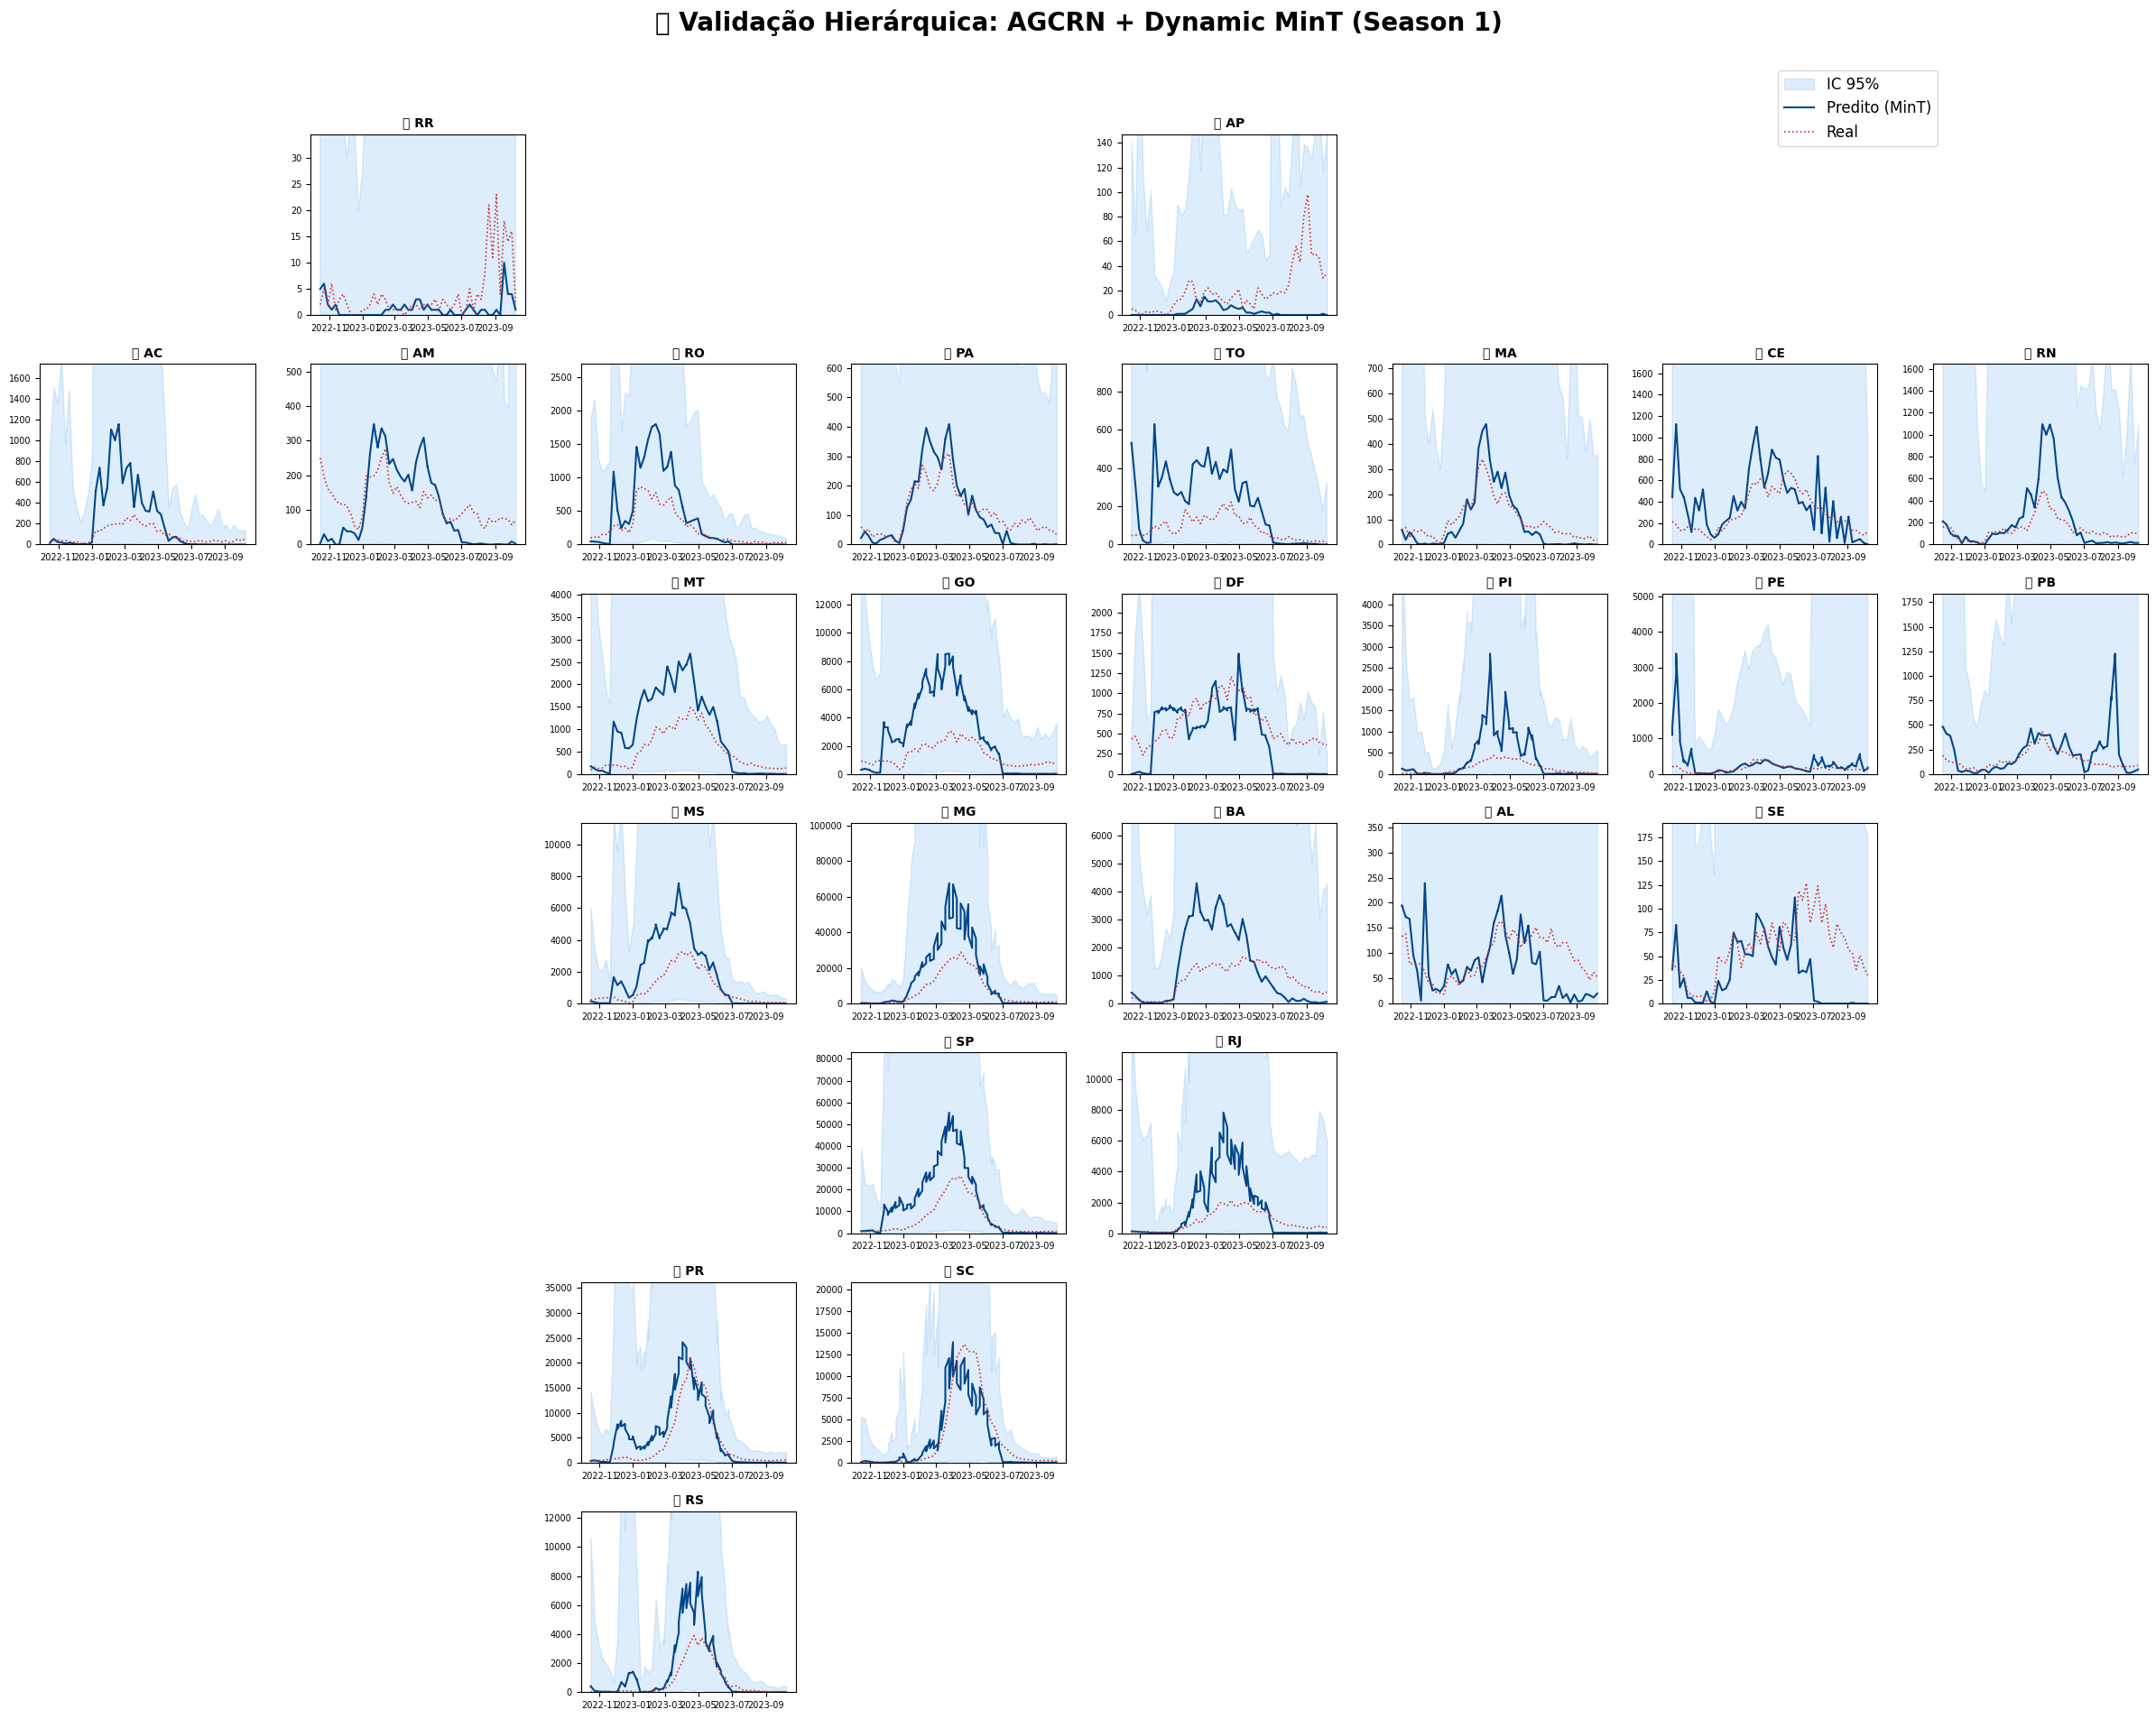

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# @title GRÁFICO DE PREDIÇÕES ESTADUAIS
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

def plotar_grid_geofacet_brasil_hd(df_estadual_resultados, season_id, col_uf=VARS['uf_code'], y_max_factor=1.5, y_max_absolute=None):
    """
    Gera o grid geofacet do Brasil com controle customizado do limite do Eixo Y
    para evitar que intervalos de confiança extremos prejudiquem a visualização.
    """
    df_plot = df_estadual_resultados.copy()

    # Garantindo que a data seja reconhecida corretamente
    df_plot['date'] = pd.to_datetime(df_plot['date'])
    df_plot = df_plot.sort_values('date')

    # Matriz do Layout Geográfico do Brasil
    grid_brasil = {
        14: {'uf': 'RR', 'row': 0, 'col': 1}, 16: {'uf': 'AP', 'row': 0, 'col': 4},
        12: {'uf': 'AC', 'row': 1, 'col': 0}, 13: {'uf': 'AM', 'row': 1, 'col': 1},
        11: {'uf': 'RO', 'row': 1, 'col': 2}, 15: {'uf': 'PA', 'row': 1, 'col': 3},
        17: {'uf': 'TO', 'row': 1, 'col': 4}, 21: {'uf': 'MA', 'row': 1, 'col': 5},
        23: {'uf': 'CE', 'row': 1, 'col': 6}, 24: {'uf': 'RN', 'row': 1, 'col': 7},
        51: {'uf': 'MT', 'row': 2, 'col': 2}, 52: {'uf': 'GO', 'row': 2, 'col': 3},
        53: {'uf': 'DF', 'row': 2, 'col': 4}, 22: {'uf': 'PI', 'row': 2, 'col': 5},
        26: {'uf': 'PE', 'row': 2, 'col': 6}, 25: {'uf': 'PB', 'row': 2, 'col': 7},
        50: {'uf': 'MS', 'row': 3, 'col': 2}, 31: {'uf': 'MG', 'row': 3, 'col': 3},
        29: {'uf': 'BA', 'row': 3, 'col': 4}, 27: {'uf': 'AL', 'row': 3, 'col': 5},
        28: {'uf': 'SE', 'row': 3, 'col': 6}, 35: {'uf': 'SP', 'row': 4, 'col': 3},
        33: {'uf': 'RJ', 'row': 4, 'col': 4}, 32: {'uf': 'ES', 'row': 4, 'col': 5},
        41: {'uf': 'PR', 'row': 5, 'col': 2}, 42: {'uf': 'SC', 'row': 5, 'col': 3},
        43: {'uf': 'RS', 'row': 6, 'col': 2}
    }

    fig, axes = plt.subplots(7, 8, figsize=(24, 20))
    for ax in axes.flat: ax.axis('off')

    for code, info in grid_brasil.items():
        ax = axes[info['row'], info['col']]
        df_uf = df_plot[df_plot[col_uf] == code].dropna(subset=['pred', 'date'])

        if df_uf.empty: continue

        ax.axis('on')
        # Plot das bandas de incerteza
        ax.fill_between(df_uf['date'], df_uf['lower_95'], df_uf['upper_95'],
                        color='#1e88e5', alpha=0.15, label='IC 95%' if code==14 else "")

        # Plot da predição reconciliada
        ax.plot(df_uf['date'], df_uf['pred'], color='#00468b', linewidth=1.5,
                label='Predito (MinT)' if code==14 else "")

        # Plot dos dados reais
        ax.plot(df_uf['date'], df_uf['casos_reais'], color='#d32f2f', linewidth=1.2, linestyle=':',
                label='Real' if code==14 else "")

        ax.set_title(f"📍 {info['uf']}", fontsize=10, weight='bold')
        ax.tick_params(axis='both', which='major', labelsize=7)

        # ----------------------------------------------------------------------
        # CONTROLE DO EIXO Y (Ignora os picos do IC95% na escala do gráfico)
        # ----------------------------------------------------------------------
        if y_max_absolute is not None:
            ax.set_ylim(bottom=0, top=y_max_absolute)
        elif y_max_factor is not None:
            # Encontra o pico real da epidemia no estado (linha central ou casos reais)
            pico_visivel = max(df_uf['pred'].max(), df_uf['casos_reais'].max())
            ax.set_ylim(bottom=0, top=pico_visivel * y_max_factor)
        else:
            ax.set_ylim(bottom=0)

    fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.95), fontsize=12)
    plt.suptitle(f'🗺️ Validação Hierárquica: AGCRN + Dynamic MinT (Season {season_id})', fontsize=20, weight='bold')
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])

    nome_arquivo = f'validacao_brasil_s{season_id}_4K.png'
    plt.savefig(nome_arquivo, dpi=200, bbox_inches='tight')
    plt.show()

    try:
        from google.colab import files
        files.download(nome_arquivo)
    except:
        pass

# Execução
import sqlite3
db_conn = sqlite3.connect('resultados_agcrn.db')

# Carrega a última submissão para a temporada atual
df_est_rec = pd.read_sql_query(f"SELECT * FROM estadual_results WHERE season = {SEASON_ALVO}", db_conn)
db_conn.close()

# Agora sim, chame a função de plotagem
plotar_grid_geofacet_brasil_hd(df_est_rec, season_id=SEASON_ALVO)

# AGCRN + MHA

In [ ]:
# @title NB loss pico - corrigido
import torch
import torch.nn.functional as F
import numpy as np
from scipy.stats import nbinom

def nb_loss_pico(log_mu: torch.Tensor, log_r: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    log_mu = torch.clamp(log_mu, min=-10, max=10)
    log_r  = torch.clamp(log_r,  min=-6,  max=6)
    mu, r = torch.exp(log_mu), torch.exp(log_r)

    # 1. NLL Base (Justa)
    nll = (
        - torch.lgamma(y + r) + torch.lgamma(r) + torch.lgamma(y + 1)
        - r * torch.log(r / (r + mu + 1e-8)) - y * torch.log(mu / (r + mu + 1e-8))
    )

    # 2. Ponderação de Magnitude
    # Faz o gradiente prestar muito mais atenção nas semanas com volume alto
    peso_surto = 1.0 + torch.log1p(y)

    # 3. Penalidade Assimétrica de Subestimação (O "Motor de Aceleração")
    # F.relu(y - mu) só ativa se a realidade (y) for MAIOR que a previsão (mu).
    # Se o modelo tentar prever para baixo durante o surto, ele toma uma "multa" linear pesada.
    erro_subestimacao = F.relu(y - mu)
    penalidade = erro_subestimacao * 0.2  # Fator de agressividade (0.2 a 0.5 costuma ser ideal)

    loss_final = (nll * peso_surto) + penalidade
    return loss_final.mean()

In [ ]:
# @title
import torch
import torch.nn.functional as F

def nb_loss_pico(log_mu: torch.Tensor, log_r: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    # 1. FORÇAR FLOAT32: A salvação contra o NaN do autocast (Float16)
    # Isso garante que lgamma e log tenham o espaço de memória necessário
    log_mu = log_mu.float()
    log_r  = log_r.float()
    y      = y.float()

    log_mu = torch.clamp(log_mu, min=-10.0, max=10.0)
    log_r  = torch.clamp(log_r,  min=-6.0,  max=6.0)
    mu, r  = torch.exp(log_mu), torch.exp(log_r)

    # 2. REESCRITA ALGÉBRICA PARA ESTABILIDADE
    # Em vez de calcular a divisão propensa a underflow, calculamos o denominador comum
    log_r_mu = torch.log(r + mu + 1e-8)

    # Substituímos log(r/(r+mu)) por (log_r - log_r_mu) e log(mu/(r+mu)) por (log_mu - log_r_mu)
    nll = (
        - torch.lgamma(y + r) + torch.lgamma(r) + torch.lgamma(y + 1)
        - r * (log_r - log_r_mu) - y * (log_mu - log_r_mu)
    )

    # 3. Ponderação de Magnitude
    peso_surto = 1.0 + torch.log1p(y)

    # 4. Penalidade Assimétrica de Subestimação
    erro_subestimacao = F.relu(y - mu)
    penalidade = erro_subestimacao * 0.2

    loss_final = (nll * peso_surto) + penalidade

    # Tratamento de segurança final caso algum nan passe (muito raro com FP32)
    #loss_final = torch.nan_to_num(loss_final, nan=0.0, posinf=0.0, neginf=0.0)

    return loss_final.mean()

In [ ]:
# @title NB loss seca
def nb_loss_seca(log_mu: torch.Tensor, log_r: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    log_mu = torch.clamp(log_mu, min=-10, max=10)
    log_r  = torch.clamp(log_r,  min=-6,  max=6)
    mu, r = torch.exp(log_mu), torch.exp(log_r)

    # 1. NLL Base (Justa)
    nll = (
        - torch.lgamma(y + r) + torch.lgamma(r) + torch.lgamma(y + 1)
        - r * torch.log(r / (r + mu + 1e-8)) - y * torch.log(mu / (r + mu + 1e-8))
    )

    # 2. Penalidade Assimétrica de Superestimação (O "Escudo Anti-Ruído")
    # F.relu(mu - y) só ativa se o modelo prever MAIS (mu) do que a realidade (y).
    erro_superestimacao = F.relu(mu - y)

    # 3. Trava de Falso Alarme (Zero-Inflation Shield)
    # torch.exp(-y) vale 1.0 quando os casos reais são 0, e cai rapidamente para perto de zero se houver casos reais.
    # Ou seja: A multa só é aplicada cruelmente se a cidade estava sem dengue.
    peso_falso_alarme = torch.exp(-y)

    penalidade = erro_superestimacao * peso_falso_alarme * 0.5 # Fator de conservadorismo

    loss_final = nll + penalidade
    return loss_final.mean()

In [ ]:
# @title Criar Quantis
def nb_quantile(mu: np.ndarray, r: np.ndarray, q: float) -> np.ndarray:
    p = r / (r + mu + 1e-8)
    return nbinom.ppf(q, n=r, p=p).astype(float)

In [ ]:
# @title LISTAS DE FEATURES PARA O AGCRN (Atualizadas com nomes pós-transformação)


# Variáveis físicas básicas que o modelo precisa saber a posição exata
COLS_FISICA = ['velocidade', 'aceleracao']

# 🌵 FEATURES DA SECA (Foco em clima basal e imunidade de longo prazo)
COLS_SECA = COLS_FISICA + [
    'access_count', 'seno_semana', 'temp_min', 'w2_velocidade_t1',
    'w1_log_pop_t1', 'w1_imunidade_t1', 'w2_log_inc_dengue_t1', 'w1_log_inc_dengue_t1',
    'imunidade_ewm', 'imunidade_ewm_t1', 'log_inc_dengue_t1', 'log_inc_chiku',
    'log_pop_t1', 'rel_humid_max', 'log_inc_chiku_t1', 'cosseno_semana',
    'w1_velocidade_t1', 'temp_med', 'koppen_encoded'
]

# 🌊 FEATURES DO PICO (Foco em explosão espacial W1/W2 e aceleração meteorológica)
COLS_PICO = COLS_FISICA + [
    'access_count', 'seno_semana', 'w2_velocidade_t1', 'w1_log_pop_t1',
    'w2_aceleracao_t1', 'access_count_t1', 'w1_log_inc_dengue_t1',
    'imunidade_ewm', 'imunidade_ewm_t1', 'log_inc_dengue_t1', 'log_inc_chiku',
    'log_pop_t1', 'cosseno_semana', 'w1_velocidade_t1', 'w1_aceleracao_t1',
    'w2_log_inc_dengue_t1', 'w2_temp_forecast_t1', 'w1_temp_forecast_t1',
    'log_inc_chiku_t1', 'umid_med_forecast', 'temp_min', 'koppen_encoded',
    'w2_umid_forecast_t1', 'temp_med_forecast', 'w2_precip_forecast_t1'
]

In [ ]:
# @title NOVO AGCRN pico - corrigido
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric_temporal.nn.recurrent import AGCRN
import torch
import torch.nn as nn
import torch.nn.functional as F

class PreditorNBAGCRN_Pico(nn.Module):
    def __init__(self, num_nodes: int, num_features: int, embedding_dim: int = 64, idx_velocidade: int = 0, idx_aceleracao: int = 1):
        super().__init__()
        self.idx_vel = idx_velocidade
        self.idx_acel = idx_aceleracao

        # 1. Definições originais restauradas
        self.node_embeddings = nn.Parameter(torch.randn(num_nodes, embedding_dim), requires_grad=True)
        self.recurrent = AGCRN(
            number_of_nodes=num_nodes,
            in_channels=num_features,
            out_channels=64,
            K=2,
            embedding_dimensions=embedding_dim
        )

        # 2. Multi-Head Attention Espacial
        self.mha_espacial = nn.MultiheadAttention(
            embed_dim=64,
            num_heads=4,
            dropout=0.1,
            batch_first=True
        )

        # 3. Adições de estabilidade (Pre-LN, Projeção Linear para MHA)
        self.proj_mha = nn.Linear(64, 64)
        self.norm = nn.LayerNorm(64)
        self.dropout = nn.Dropout(p=0.2)

        # 4. Cabeças de Saída
        self.head_mu = nn.Linear(64, 1)
        self.head_logr = nn.Linear(64 + 2, 1)

    def forward(self, x: torch.Tensor, log_pop: torch.Tensor, attn_mask: torch.Tensor, h=None):
        x_batched = x.unsqueeze(0)
        h = self.recurrent(x_batched, self.node_embeddings, h)
        h_out = h.squeeze(0)  # [Num_nodes, 64]

        # Preparação para o Multi-Head Attention Espacial
        h_mha_in = h_out.unsqueeze(0)  # [1, Num_nodes, 64]

        attn_out, attn_weights = self.mha_espacial(
            query=h_mha_in, key=h_mha_in, value=h_mha_in,
            attn_mask=attn_mask
        )

        # Projeção da atenção para estabilizar a escala antes de somar ao histórico
        attn_projected = self.proj_mha(attn_out.squeeze(0))

        # Conexão residual e normalização de camada (Pre-LN)
        h_mha_out = self.norm(h_out + attn_projected)

        # Ativação SiLU substituindo a ReLU para evitar "neurônios mortos"
        h_activated = F.silu(h_mha_out)
        h_reg = self.dropout(h_activated)

        # Cálculo da média ajustada pela população
        log_mu_raw = self.head_mu(h_reg)
        log_mu = log_mu_raw + log_pop.unsqueeze(-1)

        # Cálculo da dispersão dependente da cinemática
        vel = x[:, self.idx_vel].unsqueeze(-1)
        acel = x[:, self.idx_acel].unsqueeze(-1)
        h_r = torch.cat([h_reg, vel, acel], dim=-1)
        log_r = self.head_logr(h_r)

        return log_mu, log_r, h, attn_weights

In [ ]:
# @title NOVO AGCRN padrão
import torch
import torch.nn as nn
import torch.nn.functional as F

class PreditorNBAGCRN(nn.Module):
    def __init__(self, num_nodes: int, num_features: int, embedding_dim: int = 64, idx_velocidade: int = 0, idx_aceleracao: int = 1):
        super().__init__()

        # Recebe dinamicamente os índices da velocidade e aceleração
        self.idx_vel = idx_velocidade
        self.idx_acel = idx_aceleracao

        # Node Embeddings (Aprendem o viés estrutural de cada cidade)
        self.node_embeddings = nn.Parameter(torch.randn(num_nodes, embedding_dim), requires_grad=True)

        self.recurrent = AGCRN(
            number_of_nodes=num_nodes,
            in_channels=num_features,
            out_channels=64,
            K=2,                                   # Ordem de vizinhança espacial
            embedding_dimensions=embedding_dim     # Passando a dimensão do embedding
        )

        # 🔥 ALTERAÇÃO: Inclusão de Dropout Espaço-Temporal
        self.dropout = nn.Dropout(p=0.2)

        self.head_mu = nn.Linear(64, 1)
        # Head do parâmetro R recebe o hidden state + as 2 variáveis físicas brutas (vel e acel)
        self.head_logr = nn.Linear(64 + 2, 1)

    def forward(self, x: torch.Tensor, log_pop: torch.Tensor, h=None):
        # 1. Adiciona a dimensão de Batch
        x_batched = x.unsqueeze(0)

        # 2. Passa pela rede recorrente (Geração do estado oculto espaço-temporal)
        h = self.recurrent(x_batched, self.node_embeddings, h)

        h_out = h.squeeze(0)
        h_relu = F.relu(h_out)

        # 🔥 CORREÇÃO: O dropout agora é devidamente aplicado antes de calcular mu e r
        h_reg = self.dropout(h_relu)

        # Cálculo do log_mu utilizando o tensor com Dropout (h_reg)
        log_mu_raw = self.head_mu(h_reg)
        log_mu = log_mu_raw + log_pop.unsqueeze(-1)

        # Resgate da física diretamente da matriz de entrada usando os índices dinâmicos
        vel = x[:, self.idx_vel].unsqueeze(-1)
        acel = x[:, self.idx_acel].unsqueeze(-1)

        # Concatena o estado oculto regularizado (h_reg) com a física
        h_r = torch.cat([h_reg, vel, acel], dim=-1)
        log_r = self.head_logr(h_r)

        return log_mu, log_r, h

In [ ]:
# @title Novíssimo treino e validação com rede diferente para o pico - corrigido eval again
from tqdm import tqdm
import sys
def treinar_e_validar_season(df_train: pd.DataFrame, df_test: pd.DataFrame,
                             season_id: int, encoder_means_globais: dict,
                             num_nodes: int, mapa_simples: pd.DataFrame,
                             epochs_max_pico: int = 200, epochs_max_seca: int = 100,
                             patience: int = 25) -> dict:

    torch.backends.cudnn.benchmark = True

    df_tr, df_tgt = df_train, df_test
    if 'log_pop' not in df_tr.columns:
        df_tr['log_pop'] = np.log(df_tr[VARS['populacao']].clip(lower=1).astype(float))
    if 'log_pop' not in df_tgt.columns:
        df_tgt['log_pop'] = np.log(df_tgt[VARS['populacao']].clip(lower=1).astype(float))

    semanas_treino = sorted(df_tr[VARS['semana_epi']].unique())

    # Restauração da Validação Cruzada Temporal
    df_tr_real = df_tr[df_tr[VARS['semana_epi']].isin(semanas_treino[:-10])]
    df_val_int = df_tr[df_tr[VARS['semana_epi']].isin(semanas_treino[-10:])]

    df_tr_sort  = df_tr_real.drop(columns=['node_id', 'time_index'], errors='ignore').merge(mapa_simples, on=VARS['municipio'], how='left').sort_values([VARS['data'], 'node_id'])
    df_val_sort = df_val_int.drop(columns=['node_id', 'time_index'], errors='ignore').merge(mapa_simples, on=VARS['municipio'], how='left').sort_values([VARS['data'], 'node_id'])
    df_tgt_sort = df_tgt.drop(columns=['node_id', 'time_index'], errors='ignore').merge(mapa_simples, on=VARS['municipio'], how='left').sort_values([VARS['data'], 'node_id'])

    tempos_tr  = sorted(df_tr_sort[VARS['data']].unique())
    tempos_val = sorted(df_val_sort[VARS['data']].unique())
    tempos_tgt = sorted(df_tgt_sort[VARS['data']].unique())

    epiweeks_tr  = df_tr_sort.groupby(VARS['data'])[VARS['semana_epi']].first().values % 100
    epiweeks_val = df_val_sort.groupby(VARS['data'])[VARS['semana_epi']].first().values % 100
    epiweeks_tgt = df_tgt_sort.groupby(VARS['data'])[VARS['semana_epi']].first().values % 100

    # Construção da Máscara Categórica de Microrregião
    df_nodes_unico = df_tr_sort.drop_duplicates(subset=['node_id']).sort_values('node_id')
    codigos_micro = torch.tensor(df_nodes_unico['macroregional_geocode'].values, device=device)
    mascara_espacial_micro = (codigos_micro.unsqueeze(0) != codigos_micro.unsqueeze(1)).to(device)

    cols_seca = [c for c in COLS_SECA if c in df_tr_sort.columns]
    cols_pico = [c for c in COLS_PICO if c in df_tr_sort.columns]
    num_features_seca, num_features_pico = len(cols_seca), len(cols_pico)

    idx_vel_seca  = cols_seca.index('velocidade') if 'velocidade' in cols_seca else 0
    idx_acel_seca = cols_seca.index('aceleracao') if 'aceleracao' in cols_seca else 1
    idx_vel_pico  = cols_pico.index('velocidade') if 'velocidade' in cols_pico else 0
    idx_acel_pico = cols_pico.index('aceleracao') if 'aceleracao' in cols_pico else 1

    X_tr_sc_seca  = df_tr_sort[cols_seca].fillna(0).values.astype(np.float16)
    X_val_sc_seca = df_val_sort[cols_seca].fillna(0).values.astype(np.float16)
    X_tgt_sc_seca = df_tgt_sort[cols_seca].fillna(0).values.astype(np.float16)
    X_tr_sc_pico  = df_tr_sort[cols_pico].fillna(0).values.astype(np.float16)
    X_val_sc_pico = df_val_sort[cols_pico].fillna(0).values.astype(np.float16)
    X_tgt_sc_pico = df_tgt_sort[cols_pico].fillna(0).values.astype(np.float16)

    def _to_tensor(X_sc, tempos, num_f): return torch.tensor(X_sc.reshape(len(tempos), num_nodes, num_f), dtype=torch.float16).to(device)
    def _pop_tensor(df_sort, tempos): return torch.tensor(df_sort['log_pop'].values.reshape(len(tempos), num_nodes), dtype=torch.float16).to(device)
    def _casos_tensor(df_sort, tempos): return torch.tensor(df_sort[VARS['casos_dengue']].fillna(0).values.reshape(len(tempos), num_nodes), dtype=torch.float32).to(device)

    X_tr_t_seca, X_val_t_seca, X_tgt_t_seca = _to_tensor(X_tr_sc_seca, tempos_tr, num_features_seca), _to_tensor(X_val_sc_seca, tempos_val, num_features_seca), _to_tensor(X_tgt_sc_seca, tempos_tgt, num_features_seca)
    X_tr_t_pico, X_val_t_pico, X_tgt_t_pico = _to_tensor(X_tr_sc_pico, tempos_tr, num_features_pico), _to_tensor(X_val_sc_pico, tempos_val, num_features_pico), _to_tensor(X_tgt_sc_pico, tempos_tgt, num_features_pico)

    logpop_tr_t, logpop_val_t, logpop_tgt_t = _pop_tensor(df_tr_sort, tempos_tr), _pop_tensor(df_val_sort, tempos_val), _pop_tensor(df_tgt_sort, tempos_tgt)
    Y_tr_t, Y_val_t = _casos_tensor(df_tr_sort, tempos_tr), _casos_tensor(df_val_sort, tempos_val)

    del df_tr, df_tr_real, df_val_int, df_tr_sort, df_val_sort
    del X_tr_sc_seca, X_val_sc_seca, X_tgt_sc_seca, X_tr_sc_pico, X_val_sc_pico, X_tgt_sc_pico
    import gc
    gc.collect()

    # ==========================================================================
    # SUBFUNÇÃO DE TREINAMENTO DO ESPECIALISTA (Com Limites Dinâmicos)
    # ==========================================================================
    def treinar_especialista(num_features, idx_v, idx_a, is_pico_mode, nome, X_tr_t, X_val_t):

        # Definição dinâmica do limite máximo de épocas baseada no modo de operação
        epocas_fase = epochs_max_pico if is_pico_mode else epochs_max_seca

        if is_pico_mode:
            modelo = torch.compile(PreditorNBAGCRN_Pico(num_nodes, num_features, 64, idx_v, idx_a).to(device))
            w_decay = 1e-4
        else:
            modelo = torch.compile(PreditorNBAGCRN(num_nodes, num_features, 64, idx_v, idx_a).to(device))
            w_decay = 1e-3

        otimizador = torch.optim.AdamW(modelo.parameters(), lr=0.004, weight_decay=w_decay)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(otimizador, patience=5, factor=0.5, min_lr=1e-5)

        melhor_loss_val = float('inf')
        sem_melhora = 0
        melhor_estado = None

        from tqdm import tqdm
        import sys

        # A barra de progresso agora itera sobre a variável de controle da fase atual
        barra = tqdm(range(epocas_fase), desc=f' Treino {nome} (S{season_id})', unit='ep', file=sys.stdout)

        for epoch in barra:
            modelo.train()
            h = None
            loss_tr_total = 0.0
            passos_tr = 0

            for t in range(len(tempos_tr) - 1):
                otimizador.zero_grad()
                week_pura = epiweeks_tr[t + 1]
                pertence_ao_pico = (week_pura >= 47) or (week_pura <= 25)

                if pertence_ao_pico == is_pico_mode:
                   # with torch.amp.autocast(device_type='cuda', dtype=torch.bfloat16):
                    if is_pico_mode:
                        log_mu, log_r, h, _ = modelo(X_tr_t[t], logpop_tr_t[t], mascara_espacial_micro, h)
                    else:
                        log_mu, log_r, h = modelo(X_tr_t[t], logpop_tr_t[t], h)

                    h = h.detach().clone()
                    alvo = Y_tr_t[t + 1].unsqueeze(-1)
                    loss = nb_loss_pico(log_mu, log_r, alvo) if is_pico_mode else nb_loss_seca(log_mu, log_r, alvo)

                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
                    otimizador.step()
                    loss_tr_total += loss.item()
                    passos_tr += 1

            loss_tr_media = loss_tr_total / max(passos_tr, 1)

            # --- Validação Estratificada (Independente) ---
            modelo.eval()
            loss_val_total = 0.0
            passos_val = 0

            with torch.no_grad():
                h_val = None
                for t in range(len(tempos_val) - 1):
                    week_val = epiweeks_val[t + 1]
                    val_pertence_pico = (week_val >= 47) or (week_val <= 25)

                    if val_pertence_pico == is_pico_mode:
                        if is_pico_mode:
                            log_mu_v, log_r_v, h_val, _ = modelo(X_val_t[t], logpop_val_t[t], mascara_espacial_micro, h_val)
                        else:
                            log_mu_v, log_r_v, h_val = modelo(X_val_t[t], logpop_val_t[t], h_val)

                        if h_val is not None: h_val = h_val.clone()
                        alvo_v = Y_val_t[t + 1].unsqueeze(-1)
                        loss_v = nb_loss_pico(log_mu_v, log_r_v, alvo_v) if is_pico_mode else nb_loss_seca(log_mu_v, log_r_v, alvo_v)

                        loss_val_total += loss_v.item()
                        passos_val += 1

            loss_val_media = loss_val_total / max(passos_val, 1)

            scheduler.step(loss_val_media)
            barra.set_postfix({'L_Tr': f'{loss_tr_media:.3f}', 'L_Val': f'{loss_val_media:.3f}'})

            if loss_val_media < melhor_loss_val - 1e-4:
                melhor_loss_val = loss_val_media
                melhor_estado = {k: v.clone() for k, v in modelo.state_dict().items()}
                # Zera o contador apenas no modelo de pico
                if is_pico_mode:
                    sem_melhora = 0
            else:
                # Conta e verifica o early stopping apenas no modelo de pico
                if is_pico_mode:
                    sem_melhora += 1
                    if sem_melhora >= patience:
                        break

        if melhor_estado:
            modelo.load_state_dict(melhor_estado)
        torch.save(modelo.state_dict(), f"modelo_agcrn_{nome}_s{season_id}.pt")
        return modelo

    # Execução das instâncias de treinamento
    modelo_seca = treinar_especialista(num_features_seca, idx_vel_seca, idx_acel_seca, is_pico_mode=False, nome="SECA", X_tr_t=X_tr_t_seca, X_val_t=X_val_t_seca)
    modelo_pico = treinar_especialista(num_features_pico, idx_vel_pico, idx_acel_pico, is_pico_mode=True,  nome="PICO", X_tr_t=X_tr_t_pico, X_val_t=X_val_t_pico)

    # Execução da Matriz de Alvos Reconciliados (Test)
    modelo_seca.eval()
    modelo_pico.eval()
    preds_mu_tgt, preds_r_tgt = [], []

    with torch.no_grad():
        h_seca, h_pico = None, None
        for t in range(len(tempos_tgt)):
            #with torch.amp.autocast(device_type='cuda', dtype=torch.float16):
            log_mu_s, log_r_s, h_seca = modelo_seca(X_tgt_t_seca[t], logpop_tgt_t[t], h_seca)
            log_mu_p, log_r_p, h_pico, _ = modelo_pico(X_tgt_t_pico[t], logpop_tgt_t[t], mascara_espacial_micro, h_pico)

            if h_seca is not None: h_seca = h_seca.clone()
            if h_pico is not None: h_pico = h_pico.clone()

            week_pura = epiweeks_tgt[t]
            if (week_pura >= 47) or (week_pura <= 25):
                preds_mu_tgt.append(torch.exp(log_mu_p).squeeze(-1))
                preds_r_tgt.append(torch.exp(log_r_p).squeeze(-1))
            else:
                preds_mu_tgt.append(torch.exp(log_mu_s).squeeze(-1))
                preds_r_tgt.append(torch.exp(log_r_s).squeeze(-1))

    preds_mu_tgt_np = torch.stack(preds_mu_tgt).cpu().numpy()
    preds_r_tgt_np = torch.stack(preds_r_tgt).cpu().numpy()

    return {
        'season_id': season_id,
        'preds_mu_np': np.maximum(preds_mu_tgt_np, 0),
        'preds_r_np': np.maximum(preds_r_tgt_np, 1e-3),
        'df_tgt_sort': df_tgt_sort,
        'mapa_simples': mapa_simples,
    }

In [ ]:
# @title GERAÇÃO DA SUBMISSÃO MUNICIPAL (Vetorizada e Otimizada)
import pandas as pd
import numpy as np
from scipy.stats import nbinom

# ==============================================================================
# GERAÇÃO DA SUBMISSÃO MUNICIPAL (Vetorizada e Otimizada)
# ==============================================================================
def montar_submissao_agcrn(resultado_agcrn: dict, col_alvo: str = 'casos.x') -> pd.DataFrame:
    print("🛠️ Montando arquivo de submissão e calculando quantis...")

    df_tgt_sort  = resultado_agcrn['df_tgt_sort'].copy()

    # As matrizes mu e r vêm com formato [Semanas, Nós].
    # Como o df_tgt_sort foi perfeitamente ordenado por [time_index, node_id] no treino,
    # um simples .flatten() alinha os 300.000 tensores perfeitamente com as linhas do DataFrame.
    mu_flat = resultado_agcrn['preds_mu_np'].flatten()
    r_flat  = resultado_agcrn['preds_r_np'].flatten()

    # Prevenção matemática contra divisão por zero
    mu_flat = np.clip(mu_flat, a_min=1e-8, a_max=None)
    r_flat  = np.clip(r_flat, a_min=1e-8, a_max=None)

    # Probabilidade p requerida pela SciPy (nbinom)
    p_flat = r_flat / (r_flat + mu_flat)

    # Extrai o esqueleto base do DataFrame
    # Mapeie geocode para VARS['municipio'] caso seu pipeline posterior exija
    df_pred = df_tgt_sort[['geocode', 'date', 'epiweek', col_alvo]].copy()
    df_pred = df_pred.rename(columns={col_alvo: 'casos_reais'})

    # --------------------------------------------------------------------------
    # CÁLCULO VETORIZADO MASSIVO (Roda em milissegundos)
    # --------------------------------------------------------------------------
    quantis_necessarios = {
        'lower_95': 0.025, 'lower_90': 0.05, 'lower_80': 0.10, 'lower_50': 0.25,
        'pred': 0.50, # Mediana entra direto no loop
        'upper_50': 0.75,  'upper_80': 0.90, 'upper_90': 0.95, 'upper_95': 0.975,
    }

    for col_name, q in quantis_necessarios.items():
        # Calcula todos os 5492 nós x 52 semanas de uma única vez
        df_pred[col_name] = nbinom.ppf(q, n=r_flat, p=p_flat).astype(float)

    # Limitações físicas de predição (não existe caso negativo)
    cols_pred = ['pred'] + [k for k in quantis_necessarios.keys() if k != 'pred']
    df_pred[cols_pred] = df_pred[cols_pred].clip(lower=0).round(2)

    # --------------------------------------------------------------------------
    # AJUSTE DE DATAS E PREENCHIMENTO DE BURACOS (Grid Filler)
    # --------------------------------------------------------------------------
    # Parsing da data baseada no YYYYWW
    df_pred['date_parsed'] = pd.to_datetime(df_pred['epiweek'].astype(str) + '-0', format='%G%V-%w')
    df_pred['date'] = df_pred['date_parsed'].dt.strftime('%Y-%m-%d')

    # Garante que não falte nenhuma semana no calendário da submissão
    geocodes = df_pred['geocode'].unique()
    todas_datas = pd.date_range(start=df_pred['date_parsed'].min(), end=df_pred['date_parsed'].max(), freq='W-SUN')

    grade = pd.MultiIndex.from_product(
        [geocodes, todas_datas], names=['geocode', 'date_parsed']
    ).to_frame().reset_index(drop=True)
    grade['date'] = grade['date_parsed'].dt.strftime('%Y-%m-%d')

    # Realiza o Merge para criar buracos (NaN) onde faltarem semanas
    df_final = pd.merge(grade, df_pred, on=['geocode', 'date', 'date_parsed'], how='left')

    # Preenche os eventuais buracos com interpolação linear restrita
    for col in cols_pred:
        df_final[col] = df_final.groupby('geocode')[col].transform(lambda x: x.interpolate('linear').bfill().ffill())
        df_final[col] = np.maximum(df_final[col], 0).round(2)

    # Organização Final das Colunas
    colunas_finais = [
        'geocode', 'date', 'casos_reais', 'pred',
        'lower_50', 'upper_50', 'lower_80', 'upper_80',
        'lower_90', 'upper_90', 'lower_95', 'upper_95',
    ]

    # Usa geocode ou VARS['municipio'] conforme seu padrão
    return df_final[colunas_finais].sort_values(by=['geocode', 'date']).reset_index(drop=True)

In [ ]:
# @title MAIN epochs separado+MHA
import os
import zipfile

# Tenta importar a biblioteca de download do Colab
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if __name__ == '__main__':
    # ==========================================================================
    # CONTROLE MANUAL DE EXECUÇÃO
    # Defina aqui qual Season você deseja processar (1, 2, 3 ou 4)
    # ==========================================================================
    SEASON_ALVO = 1

    print(f"\n{'='*75}")
    print(f" 🚀 INICIANDO PIPELINE FINAL (DUPLO ESPECIALISTA): SEASON {SEASON_ALVO}")
    print(f"{'='*75}")

    # Conecta (ou cria) o banco de dados que vai armazenar os 4 folds
    db_conn = sqlite3.connect('resultados_agcrn.db')

    # Carrega os arquivos FINAIS (já com log1p, incidências e StandardScaler)
    arquivo_treino = f"train{SEASON_ALVO}_FINAL_NN.parquet"
    arquivo_teste  = f"test{SEASON_ALVO}_FINAL_NN.parquet"

    print(f"📥 Carregando tensores padronizados:\n   - {arquivo_treino}\n   - {arquivo_teste}")
    df_train = pd.read_parquet(arquivo_treino)
    df_test  = pd.read_parquet(arquivo_teste)

    # Filtro de segurança para garantir a ausência do Espírito Santo
    df_train = df_train[df_train[VARS['uf_code']] != 32].reset_index(drop=True)
    df_test  = df_test[df_test[VARS['uf_code']] != 32].reset_index(drop=True)

    # ==========================================================================
    # 💉 A CURA: CORREÇÃO DO PRODUTO CARTESIANO (MERGE EXPLOSIVO) DO R
    # ==========================================================================
    print("🔪 Removendo duplicações dimensionais herdadas do R...")
    df_train = df_train.drop_duplicates(subset=[VARS['municipio'], VARS['data']]).reset_index(drop=True)
    df_test  = df_test.drop_duplicates(subset=[VARS['municipio'], VARS['data']]).reset_index(drop=True)

    # 🔥 OTIMIZAÇÃO DE RAM 1: DOWNCAST AGRESSIVO (Reduz de float64 para float32)
    print("🧹 Compactando memória RAM (Downcasting)...")
    for df in [df_train, df_test]:
        colunas_float = df.select_dtypes(include=['float64']).columns
        df[colunas_float] = df[colunas_float].astype('float32')
        colunas_int = df.select_dtypes(include=['int64']).columns
        df[colunas_int] = df[colunas_int].astype('int32')

    # O mapa de nós (Dicionário de localização) é extraído do dataframe
    mapa_simples = df_train[[VARS['municipio']]].drop_duplicates().sort_values(VARS['municipio']).reset_index(drop=True)
    mapa_simples['node_id'] = mapa_simples.index
    num_nodes = len(mapa_simples)

    print(f"🗺️ Malha Espacial validada: {num_nodes} municípios computáveis.")

    # ----------------------------------------------------------------------
    # 1. TREINAMENTO BIFURCADO (Rede Seca + Rede Pico)
    # ----------------------------------------------------------------------
    res_agcrn = treinar_e_validar_season(
        df_train=df_train,
        df_test=df_test,
        season_id=SEASON_ALVO,
        encoder_means_globais={},
        num_nodes=num_nodes,
        mapa_simples=mapa_simples,
        epochs_max_pico=200,  # <-- Atualizado para o novo nome
        epochs_max_seca=50,  # <-- Limite de 100 épocas para a entressafra
        patience=20
    )

    # ----------------------------------------------------------------------
    # 2. GERAÇÃO DA SUBMISSÃO MUNICIPAL (Matriz Vetorizada)
    # ----------------------------------------------------------------------
    df_mun = montar_submissao_agcrn(res_agcrn, col_alvo=VARS['casos_dengue'])

    # Mapeamento do uf_code para agrupar o nível estadual com precisão
    mapa_uf_code = df_train[[VARS['municipio'], VARS['uf_code']]].drop_duplicates()
    df_mun = df_mun.merge(mapa_uf_code, on=VARS['municipio'], how='left')

    # ----------------------------------------------------------------------
    # 3. AGREGAÇÃO ESTADUAL BASELINE (Soma Pura)
    # ----------------------------------------------------------------------
    print("📊 Agregando predições para a Macro-região Estadual (Baseline)...")
    cols_agregacao = ['pred', 'lower_50', 'upper_50', 'lower_80', 'upper_80',
                      'lower_90', 'upper_90', 'lower_95', 'upper_95', 'casos_reais']
    df_est = df_mun.groupby([VARS['uf_code'], 'date'])[cols_agregacao].sum().reset_index()

    # ----------------------------------------------------------------------
    # 4. RECONCILIAÇÃO HIERÁRQUICA (MinT Dinâmico WLS)
    # ----------------------------------------------------------------------
    # 🔥 ALTERAÇÃO AQUI: Chamada atualizada para o MinT Dinâmico WLS
    df_mun_rec, df_est_rec = reconciliar_mint_dinamico_wls(
        df_municipal=df_mun,
        df_estadual=df_est,
        semana_inicio_alta=47,
        semana_fim_alta=25,
        col_uf_code=VARS['uf_code'],
        var_municipio='geocode' # Alinhado com a saída da função de submissão
    )

    # ----------------------------------------------------------------------
    # 5. SALVAMENTO NO BANCO DE DADOS SQLITE
    # ----------------------------------------------------------------------
    print("💾 Salvando projeções reconciliadas no banco de dados SQLite...")
    df_mun_rec['season'] = SEASON_ALVO
    df_est_rec['season'] = SEASON_ALVO

    df_mun_rec.to_sql('municipal_results', db_conn, if_exists='append', index=False)
    df_est_rec.to_sql('estadual_results', db_conn, if_exists='append', index=False)
    db_conn.close()

    # ----------------------------------------------------------------------
    # 6. DOWNLOAD DOS ARQUIVOS GERADOS
    # ----------------------------------------------------------------------
    # 🔥 ALTERAÇÃO AQUI: Empacotamento em ZIP para garantir o download de ambos
    modelo_seca_file = f"modelo_agcrn_SECA_s{SEASON_ALVO}.pt"
    modelo_pico_file = f"modelo_agcrn_PICO_s{SEASON_ALVO}.pt"
    zip_name = f"modelos_agcrn_s{SEASON_ALVO}.zip"

    print("\n📦 Preparando arquivos para extração...")

    with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zipf:
        if os.path.exists(modelo_seca_file):
            zipf.write(modelo_seca_file)
        if os.path.exists(modelo_pico_file):
            zipf.write(modelo_pico_file)

    if IN_COLAB:
        print(f"   -> Detectado ambiente Colab. Iniciando download de {zip_name}...")
        if os.path.exists(zip_name):
            files.download(zip_name)
    else:
        print(f"   -> Ambiente local. Os pesos foram salvos fisicamente na sua pasta atual no arquivo:\n      - {zip_name}")

    # Limpeza final de memória
    del df_train, df_test, res_agcrn, df_mun, df_est, df_mun_rec, df_est_rec
    gc.collect()

    print(f"\n✅ SEASON {SEASON_ALVO} COMPLETA! Pode mudar a variável para a próxima.")


 🚀 INICIANDO PIPELINE FINAL (DUPLO ESPECIALISTA): SEASON 1
📥 Carregando tensores padronizados:
   - train1_FINAL_NN.parquet
   - test1_FINAL_NN.parquet
🔪 Removendo duplicações dimensionais herdadas do R...
🧹 Compactando memória RAM (Downcasting)...
🗺️ Malha Espacial validada: 5492 municípios computáveis.
 Treino PICO (S1):  25%|██▌       | 50/200 [44:46<2:14:20, 53.74s/ep, L_Tr=2.576, L_Val=5.883]
🛠️ Montando arquivo de submissão e calculando quantis...
📊 Agregando predições para a Macro-região Estadual (Baseline)...
⚙️ [MinT Dinâmico WLS] Iniciando reconciliação orientada a variância sazonal...
   -> Alta Transmissão: SE-47 a SE-25
   -> Matriz P_wls (PICO) calculada e otimizada.
   -> Matriz P_wls (SECA) calculada e otimizada.
✅ [MinT Dinâmico WLS] Finalizado com sucesso!
💾 Salvando projeções reconciliadas no banco de dados SQLite...

📦 Preparando arquivos para extração...
   -> Detectado ambiente Colab. Iniciando download de modelos_agcrn_s1.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

NameError: name 'gc' is not defined

In [ ]:
# @title
import torch
import numpy as np
import pandas as pd
import os

def inferencia_com_warmup(df_train: pd.DataFrame, df_test: pd.DataFrame,
                          season_id: int, num_nodes: int, mapa_simples: pd.DataFrame) -> dict:

    print("\n🔥 Preparando período de Warm-up (Aquecimento do Estado Oculto)...")

    # 1. Isola as últimas 10 semanas do treino (O período original de validação)
    semanas_treino = sorted(df_train[VARS['semana_epi']].unique())
    semanas_val = semanas_treino[-10:]
    df_val = df_train[df_train[VARS['semana_epi']].isin(semanas_val)].copy()

    # Prepara log_pop se não existir
    for df in [df_val, df_test]:
        if 'log_pop' not in df.columns:
            df['log_pop'] = np.log(df[VARS['populacao']].clip(lower=1).astype(float))

    # 2. Concatena Validação (Warm-up) + Teste (Alvo Real) ordenados no tempo
    df_val_sort = df_val.drop(columns=['node_id', 'time_index'], errors='ignore').merge(mapa_simples, on=VARS['municipio'], how='left').sort_values([VARS['data'], 'node_id'])
    df_tgt_sort = df_test.drop(columns=['node_id', 'time_index'], errors='ignore').merge(mapa_simples, on=VARS['municipio'], how='left').sort_values([VARS['data'], 'node_id'])

    # Dataframe contínuo para a inferência
    df_inf_sort = pd.concat([df_val_sort, df_tgt_sort], ignore_index=True)

    tempos_val = sorted(df_val_sort[VARS['data']].unique())
    tempos_inf = sorted(df_inf_sort[VARS['data']].unique())
    epiweeks_inf = df_inf_sort.groupby(VARS['data'])[VARS['semana_epi']].first().values % 100

    # 3. Construção dos Tensores contínuos
    codigos_micro = torch.tensor(mapa_simples.merge(df_val_sort[[VARS['municipio'], 'macroregional_geocode']].drop_duplicates(), on=VARS['municipio'], how='left')['macroregional_geocode'].values, device=device)
    mascara_espacial_micro = (codigos_micro.unsqueeze(0) != codigos_micro.unsqueeze(1)).to(device)

    cols_seca = [c for c in COLS_SECA if c in df_inf_sort.columns]
    cols_pico = [c for c in COLS_PICO if c in df_inf_sort.columns]

    idx_vel_seca  = cols_seca.index('velocidade') if 'velocidade' in cols_seca else 0
    idx_acel_seca = cols_seca.index('aceleracao') if 'aceleracao' in cols_seca else 1
    idx_vel_pico  = cols_pico.index('velocidade') if 'velocidade' in cols_pico else 0
    idx_acel_pico = cols_pico.index('aceleracao') if 'aceleracao' in cols_pico else 1

    X_inf_sc_seca = df_inf_sort[cols_seca].fillna(0).values.astype(np.float32)
    X_inf_sc_pico = df_inf_sort[cols_pico].fillna(0).values.astype(np.float32)

    X_inf_t_seca = torch.tensor(X_inf_sc_seca.reshape(len(tempos_inf), num_nodes, len(cols_seca)), dtype=torch.float32).to(device)
    X_inf_t_pico = torch.tensor(X_inf_sc_pico.reshape(len(tempos_inf), num_nodes, len(cols_pico)), dtype=torch.float32).to(device)
    logpop_inf_t = torch.tensor(df_inf_sort['log_pop'].values.reshape(len(tempos_inf), num_nodes), dtype=torch.float32).to(device)

    # 4. Instancia e Carrega os Pesos Salvos
    print("🧠 Carregando pesos dos especialistas (SECA e PICO)...")
    print("🧠 Carregando pesos dos especialistas (SECA e PICO)...")
    modelo_seca = PreditorNBAGCRN(num_nodes, len(cols_seca), 64, idx_vel_seca, idx_acel_seca).to(device)
    modelo_pico = PreditorNBAGCRN_Pico(num_nodes, len(cols_pico), 64, idx_vel_pico, idx_acel_pico).to(device)

    # Carrega os dicionários originais do arquivo
    state_dict_seca = torch.load(f"modelo_agcrn_SECA_s{season_id}.pt", weights_only=True)
    state_dict_pico = torch.load(f"modelo_agcrn_PICO_s{season_id}.pt", weights_only=True)

    # Remove o prefixo '_orig_mod.' deixado pelo torch.compile
    state_dict_seca_clean = {k.replace('_orig_mod.', ''): v for k, v in state_dict_seca.items()}
    state_dict_pico_clean = {k.replace('_orig_mod.', ''): v for k, v in state_dict_pico.items()}

    # Carrega os pesos limpos nos modelos
    modelo_seca.load_state_dict(state_dict_seca_clean)
    modelo_pico.load_state_dict(state_dict_pico_clean)

    modelo_seca.eval()
    modelo_pico.eval()

    preds_mu_inf, preds_r_inf = [], []

    # 5. O Loop de Inferência Contínua
    print("🚀 Executando inferência sequencial...")
    with torch.no_grad():
        h_seca, h_pico = None, None
        for t in range(len(tempos_inf)):
            log_mu_s, log_r_s, h_seca = modelo_seca(X_inf_t_seca[t], logpop_inf_t[t], h_seca)
            log_mu_p, log_r_p, h_pico, _ = modelo_pico(X_inf_t_pico[t], logpop_inf_t[t], mascara_espacial_micro, h_pico)

            if h_seca is not None: h_seca = h_seca.clone()
            if h_pico is not None: h_pico = h_pico.clone()

            week_pura = epiweeks_inf[t]
            if (week_pura >= 47) or (week_pura <= 25):
                preds_mu_inf.append(torch.exp(log_mu_p).squeeze(-1))
                preds_r_inf.append(torch.exp(log_r_p).squeeze(-1))
            else:
                preds_mu_inf.append(torch.exp(log_mu_s).squeeze(-1))
                preds_r_inf.append(torch.exp(log_r_s).squeeze(-1))

    # 6. O CORTE CIRÚRGICO (Descarte do Warm-up)
    offset_warmup = len(tempos_val)
    preds_mu_test_np = torch.stack(preds_mu_inf)[offset_warmup:].cpu().numpy()
    preds_r_test_np  = torch.stack(preds_r_inf)[offset_warmup:].cpu().numpy()

    print("✂️ Warm-up descartado. Retornando apenas matriz do período de Teste.")
    return {
        'season_id': season_id,
        'preds_mu_np': np.maximum(preds_mu_test_np, 0),
        'preds_r_np': np.maximum(preds_r_test_np, 1e-3),
        'df_tgt_sort': df_tgt_sort,
        'mapa_simples': mapa_simples,
    }

In [ ]:
import sqlite3
import pandas as pd
import numpy as np

def gerar_banco_inferencia_limpa(season_id: int):
    print(f"\n{'='*75}")
    print(f" 🗄️ INICIANDO INFERÊNCIA LIMPA E MONTAGEM DE BANCO: SEASON {season_id}")
    print(f"{'='*75}")

    # 1. Carregamento e Pré-processamento Rápido
    arquivo_treino = f"train{season_id}_FINAL_NN.parquet"
    arquivo_teste  = f"test{season_id}_FINAL_NN.parquet"

    print(f"📥 Carregando tensores de dados da Season {season_id}...")
    df_train = pd.read_parquet(arquivo_treino)
    df_test  = pd.read_parquet(arquivo_teste)

    # Filtros de segurança e limpeza espacial
    df_train = df_train[df_train[VARS['uf_code']] != 32].reset_index(drop=True)
    df_test  = df_test[df_test[VARS['uf_code']] != 32].reset_index(drop=True)

    df_train = df_train.drop_duplicates(subset=[VARS['municipio'], VARS['data']]).reset_index(drop=True)
    df_test  = df_test.drop_duplicates(subset=[VARS['municipio'], VARS['data']]).reset_index(drop=True)

    # Downcasting para economizar RAM
    for df in [df_train, df_test]:
        colunas_float = df.select_dtypes(include=['float64']).columns
        df[colunas_float] = df[colunas_float].astype('float32')
        colunas_int = df.select_dtypes(include=['int64']).columns
        df[colunas_int] = df[colunas_int].astype('int32')

    # Dicionário Espacial
    mapa_simples = df_train[[VARS['municipio']]].drop_duplicates().sort_values(VARS['municipio']).reset_index(drop=True)
    mapa_simples['node_id'] = mapa_simples.index
    num_nodes = len(mapa_simples)

    # 2. Executa a Inferência com descarte do Warm-up
    res_agcrn = inferencia_com_warmup(
        df_train=df_train,
        df_test=df_test,
        season_id=season_id,
        num_nodes=num_nodes,
        mapa_simples=mapa_simples
    )

    # 3. Montagem da Submissão Municipal e Agregação
    print("🧩 Montando matrizes de submissão e agregando nível estadual...")
    df_mun = montar_submissao_agcrn(res_agcrn, col_alvo=VARS['casos_dengue'])

    mapa_uf_code = df_train[[VARS['municipio'], VARS['uf_code']]].drop_duplicates()
    df_mun = df_mun.merge(mapa_uf_code, on=VARS['municipio'], how='left')

    cols_agregacao = ['pred', 'lower_50', 'upper_50', 'lower_80', 'upper_80',
                      'lower_90', 'upper_90', 'lower_95', 'upper_95', 'casos_reais']
    df_est = df_mun.groupby([VARS['uf_code'], 'date'])[cols_agregacao].sum().reset_index()

    # 4. Reconciliação MinT
    print("⚖️ Aplicando Reconciliação Hierárquica MinT Dinâmico WLS...")
    df_mun_rec, df_est_rec = reconciliar_mint_dinamico(
        df_municipal=df_mun,
        df_estadual=df_est,
        semana_inicio_alta=47,
        semana_fim_alta=25,
        col_uf_code=VARS['uf_code'],
        var_municipio='geocode'
    )

    # 5. Inserção no SQLite
    print("💾 Gravando resultados no banco de dados SQLite...")
    df_mun_rec['season'] = season_id
    df_est_rec['season'] = season_id

    db_conn = sqlite3.connect('resultados_agcrn.db')
    df_mun_rec.to_sql('municipal_results', db_conn, if_exists='append', index=False)
    df_est_rec.to_sql('estadual_results', db_conn, if_exists='append', index=False)
    db_conn.close()

    print(f"✅ Banco populado com sucesso para a Season {season_id}!")

# ==============================================================================
# GATILHO DE EXECUÇÃO
# ==============================================================================
if __name__ == '__main__':
    # Basta mudar o número da season e rodar este bloco!
    gerar_banco_inferencia_limpa(season_id=1)


 🗄️ INICIANDO INFERÊNCIA LIMPA E MONTAGEM DE BANCO: SEASON 1
📥 Carregando tensores de dados da Season 1...


In [ ]:
from google.colab import files

# Substitua 'seu_arquivo.db' pelo caminho correto do seu banco de dados
files.download('resultados_agcrn.db')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>